# 3-servo: compensation

Score the speed estimate built from the board's own signals on this servo, band by band, against the ripple tach, the order-tracked ripple count, the camera's tag and the pot. Grade the pot as a velocity source against the tag by window length, put a rule on the dropout-rate flag, read the limits a firmware writes, and close stage 3 with the table of what to compensate and how. The notebook has no capture of its own. It re-reads the ladder, run-up, sag, pot-table and load datasets and takes every constant from the stage 3 and stage 1 results.

## Purpose

Stages 4 to 7 build the servo's estimators, loops and limits on this stage's data. Each of them needs to know which error terms are large enough to matter, how large each one is, and which way of handling it the data support.

- The speed estimate. The back-EMF estimate with its four terms, the current's zero, the crest sample's reading term, the brush drop and the resistance with temperature, scored per speed band from a crawl to the top of the run-ups, on the free shaft and with current flowing.
- The pot as a velocity source. The pot's speed over a window against the EMF's over the same window, and the window where the pot becomes the better of the two.
- The position. The pot through its table against the tag over the travel and by direction, and the spread of a hold under torque.
- The dropout flag. The rate of crest samples near zero, what it does to the estimate on this servo, and the rule for the flag.
- The limits. The current ceiling, the stall line cold and warm, the sag cap, the zero's awake step, the undervolt floor and the tap floor.
- The closing table. Every effect with its size, whether a firmware compensates it, designs around it or bounds it, and the stage that owns it.

## Procedure

The procedure is the README's `compensation` section. No sitting ran for it. The datasets it reads ran on the experiment image, so every drive is open loop.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`.

- `ladder/capture-1` and `ladder/rail-1`, the free ladder (`cycles.csv`, a spin and a coast with the bridge open per cycle, both directions, on the three rails), the reference rung `ladder/ref-open-N` and `ref-close-N` of sittings 1, 6 and 7, and `ladder/low-1`, the kicked low holds.
- The six `run-up/runup-open-N` and `runup-close-N` sets, 5 V spins at full duty from rest, each with a coast.
- `sag/capture-1` (`levels.csv`), a crawl and a 30 % cycle at each rail as the DPS steps down.
- The camera sitting's `pot-table/pass-open-9`, `crawl-9`, `reversal-9`, `steps-9` and `pass-close-9`, chains (`chains.csv`, `chains/K`) beside one phone clip per block, with the tag's corners, the STAT lamp's level and the clapper's log per clip.
- `load/lift-1` and `load/ladder-1`, the hanging arm's lifts and holds of sitting `servo-load-1`.

The sitting manifests under `sittings/` give the rail and the board NTC before each sweep. Each sweep folder holds `sweep.csv`, one row per control tick, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.ndimage import uniform_filter1d

from oscnb import (boards, coast, figures, manifest, motors, results, ripple,
                   scales, servos, tel)
from oscnb import fiducial as fd
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

pd.set_option("display.width", 200)    # the printed tables run wide

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
FS = BOARD.tick_hz                      # rows per second, the control tick
ARR = BOARD.pwm_arr                     # timer ticks per PWM period
GEAR = SERVO.gear_ratio                 # motor revs per output rev, teeth
N_R = MOTOR.ripple_per_rev              # commutation events per motor rev
DEG_S_PER_REV_S = 360.0 / GEAR          # horn deg/s per motor rev/s
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"gear {GEAR:.4f}:1, {N_R} ripple events per motor rev, {FS} "
      f"rows/s, PWM period {ARR} ticks")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
gear 308.0533:1, 6 ripple events per motor rev, 20000 rows/s, PWM period 1200 ticks


## 1. The setup

### The constants, through the chain

Every constant comes from a result file. The stage 1 scales turn counts into amps and volts, with the bridge's edge lags on each rail. The resistance result gives construction C's line through the chains and the lock, R_C and V0, the locked laps' resistance with V0 inside and their board temperature T0, and the crest term g the meter confirmed. The inductance result gives the brake interval's drop as a line in the current, and L. Stage 1's bridge-states gives the brake loop as the alternative. The ladder gives Ke, the dropout coefficient k_d as a candidate, and the awake zero's line on the rail. The run-up gives J, the pot table its table of record and its scale, the friction result the drag pair and the load result the warm stall line, the hold's deadband, the static friction and Kt through the gears over its three sittings. The one typed number is copper's resistance slope, a physical constant.

In [3]:
SC = scales.load(BOARD)                 # stage 1: counts to amps and volts
A_PER_COUNT = SC.a_per_count            # A per count of current
V_PER_COUNT = SC.v_per_count            # V per count of tap difference
TAP_OFFSET = SC.terminal_offset_counts  # counts, the taps' own offset
I_DRIVE_OFFSET = SC.drive_offset_counts  # counts, stage 1's in-drive one


def stage3(experiment):
    """One stage 3 result file of this pair."""
    return results.read("3-servo", experiment, pair=PAIR)


RES, IND = stage3("resistance"), stage3("inductance")
LAD, RUN, STP = stage3("ladder"), stage3("run-up"), stage3("steps")
SAG, POT = stage3("sag"), stage3("pot-table")
FRIC, LOAD = stage3("friction"), stage3("load")
S1C = results.read("1-board", "compensation", pair=BOARD.key)
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD.key)
# the type's bare motor, for the drag a run-up's order count starts from
NL_TYPE = results.read("2-motor", "no-load-current", pair=SERVO.type_motor)
# the pot table of record, written beside the pot-table result
POT_TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                        .with_suffix(".table.csv"))
SC.describe()

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end


In [4]:
def val(d, key):
    """A result quantity's value."""
    return d[key]["value"]


BRAKE = IND["brake_line_motor_plain"]   # the brake interval's drop line
K = {
    # construction C's line through the chains and the lock, ohm and V
    "r_c": val(RES, "r_rails_at_measured_e_ohm"),
    "v0": val(RES, "v0_rails_at_measured_e_v"),
    "r_locked": val(RES, "r_term_ohm"),    # ohm, 100 % laps, V0 inside
    "t0_c": val(RES, "board_ntc_c"),       # C, the locked laps' board NTC
    "g": val(RES, "meter_g_ms") * 1e-3,    # S, the meter's crest term
    "brake_b0": val(BRAKE, "intercept_mv") * 1e-3,   # V
    "brake_b1": val(BRAKE, "slope_ohm"),             # ohm
    "r_brk_loop": val(BRIDGE, "low_side_loop_ohm"),  # ohm, stage 1's loop
    "l_h": val(IND, "l_mh") * 1e-3,        # H, the winding's inductance
    "ke": val(LAD, "ke_mv_per_rev_s") * 1e-3,        # V per rev/s
    "k_d": val(LAD["k_d_mv_per_dropout_s"], "B") * 1e-3,  # V per drop/s
    # the awake zero's step over the asleep zero, a line on the rail
    "awake_per_v": val(LAD, "zero_awake_step_per_v_counts"),
    "awake_c0": val(LAD, "zero_awake_step_intercept_counts"),
    "j": val(RUN, "j_kg_m2"),              # kg m2, rotor and train
    "pot_scale": val(POT, "pot_scale_counts_per_deg"),
    "tag_grade_deg": val(POT, "tag_grade_deg"),
}
# the brackets the result files carry, (lo, hi)
BRACKET = {"r_c": RES["r_rails_at_measured_e_ohm"],
           "v0": RES["v0_rails_at_measured_e_v"],
           "g": RES["meter_g_ms"], "ke": LAD["ke_mv_per_rev_s"]}
BRACKET = {k: (v["lo"], v["hi"]) for k, v in BRACKET.items()}
ALPHA_CU = 0.0039       # per C, copper's resistance slope: typed, physical

In [5]:
lo, hi = BRACKET["r_c"]
print(f"R_C {K['r_c']:.4f} ohm ({lo:.4f} to {hi:.4f}), R locked "
      f"{K['r_locked']:.4f} ohm, T0 {K['t0_c']:.2f} C")
lo, hi = BRACKET["v0"]
print(f"V0 {K['v0'] * 1e3:+.1f} mV ({lo * 1e3:+.1f} to {hi * 1e3:+.1f})")
lo, hi = BRACKET["g"]
print(f"g {K['g'] * 1e3:.3f} mS ({lo:.2f} to {hi:.2f}) on (1 - D) V_on")
print(f"brake line {K['brake_b0'] * 1e3:.2f} mV + {K['brake_b1']:.4f} ohm "
      f"x i; stage 1's loop {K['r_brk_loop']:.3f} ohm")
lo, hi = BRACKET["ke"]
print(f"Ke {K['ke'] * 1e3:.4f} mV per rev/s ({lo:.4f} to {hi:.4f}); L "
      f"{K['l_h'] * 1e3:.3f} mH; J {K['j']:.3e} kg m2")
print(f"k_d {K['k_d'] * 1e3:.3f} mV per dropout/s (the ladder's candidate)")
print(f"awake zero line {K['awake_per_v']:.3f} counts/V "
      f"{K['awake_c0']:+.2f}; pot {K['pot_scale']:.2f} counts/deg; tag "
      f"grade {K['tag_grade_deg']:.2f} deg; copper {ALPHA_CU * 100:.2f} %/C")
print(f"stage 1: {SC.counts_per_a:.1f} counts/A, in-drive offset "
      f"{I_DRIVE_OFFSET:+.2f} counts, {SC.terminal_counts_per_v:.2f} "
      f"counts/V on the taps, offset {TAP_OFFSET:+.2f}")
for rail in (3.7, 5.0, 7.4):
    on, off, _, _ = SC.edge_lags_at(rail)   # stage 1's lags on the rail
    print(f"  edge lags at {rail} V: ON {on:.1f}, OFF {off:.1f} ticks")

R_C 4.1767 ohm (4.1676 to 4.1932), R locked 4.2189 ohm, T0 26.26 C
V0 +33.2 mV (+16.3 to +40.4)
g 4.746 mS (4.52 to 4.97) on (1 - D) V_on
brake line 8.75 mV + 0.2397 ohm x i; stage 1's loop 0.301 ohm
Ke 7.2828 mV per rev/s (7.2372 to 7.3285); L 0.820 mH; J 6.433e-09 kg m2
k_d 0.781 mV per dropout/s (the ladder's candidate)
awake zero line 1.811 counts/V -3.80; pot 18.91 counts/deg; tag grade 0.16 deg; copper 0.39 %/C
stage 1: 1135.0 counts/A, in-drive offset +5.26 counts, 248.37 counts/V on the taps, offset +2.38
  edge lags at 3.7 V: ON 37.0, OFF 13.0 ticks
  edge lags at 5.0 V: ON 38.8, OFF 13.7 ticks
  edge lags at 7.4 V: ON 42.0, OFF 15.0 ticks


### The estimate

Per row of a driven window the board's signals give four terms.

$$i_w = \frac{c - z_a}{k_i} - g\,(1 - D)\,V_\mathrm{on}$$

$$V_c = s\,V_\mathrm{on} - (1 - s)\,(b_0 + b_1\,i_w)$$

$$E = V_c - V_0 - R(T)\,i_w - k_d\,\dot n_d - V_b(\omega, \mathrm{dir})$$

$$\omega = E / K_e$$

Here $c$ is the crest sample in counts, $z_a$ the awake zero, $k_i$ the counts per amp, $g$ the crest term, $D$ the duty and $V_\mathrm{on}$ the crest tap volts, so $i_w$ is the winding current. $s$ is the share of the period the bridge drives after stage 1's edge lags and $b_0 + b_1\,i_w$ the brake interval's drop, so $V_c$ is the volts applied over the period. $V_0$ is the contact offset and $R(T) = R_C\,(1 + \alpha\,(T - T_0))$ the resistance at the board NTC's temperature $T$, with $\alpha$ ("alpha") copper's slope. $\dot n_d$ ("n dot d") is the dropout rate, the crest samples a second that sit under a quarter of their window's mean, $V_b$ the brush drop by speed and direction, $K_e$ the back-EMF constant in mV per rev/s and $\omega$ ("omega") the motor's speed in rev/s. In the code they are i_w, V_c, E and w.

The README's four terms are the zero ($z_a$), the reading term ($g$), the brush drop ($V_b$) and $R(T)$. $V_b$ depends on $\omega$, so the equation is solved for its one root by bisection. At full duty nothing switches, $s = 1$, the brake and reading terms drop out, and the run-ups take $L\,di/dt$ off the volts as well.

The awake zero is each sweep's own coast tail, with the bridge open and the rotor at rest, the value a perfect tracker would hold. The variant `stage1_zero` takes stage 1's constant in-drive offset instead.

The method's settings follow, each with its unit and reason.

In [6]:
# the spin window, as the ladder notebook reads it
SPIN_WINDOW_MS, SPIN_WINDOW_MIN_MS = 100, 20  # ms, the held duty's last
TAIL_ROWS = 2000            # rows, the coast's last 100 ms: the awake zero
DECEL_FRAC_MAX = 0.35       # the Ke window's speed loss gate, a share
MIN_CYCLES = 4              # ripple cycles the Ke window needs at least
HOLD_TAIL_ROWS = 8000       # rows, a low hold's last 400 ms
SEED_MIN_HZ = 7.5           # Hz, the lowest ripple seed the tach takes
TACH_MIN_REV_S = 50         # rev/s, a ladder spin's tach counts over this
SETTLED_PCT = 2.5           # %, a settled spin's last two windows agree
# the brush table: knots, solve
KNOTS = np.arange(50.0, 551.0, 50.0)  # rev/s, the table's knots
NULL_PAST_REV_S = 25        # rev/s past the top rung the table stays null
SOLVE_MARGIN_V = 0.3        # V, room above u for a signed table's dip
SOLVE_ITERS = 50            # bisection steps
# the bands every score is reported in, motor rev/s
BANDS = ((0, 30), (30, 100), (100, 160), (160, 250), (250, 350),
         (350, 450), (450, 600))
BAND_NAMES = [f"{a}-{b}" for a, b in BANDS]
ORDER = {b: i for i, b in enumerate(BAND_NAMES)}
X_LINE_TOP = 350            # rev/s, X's line is read under this
EXPECT_CRAWL = (1, 3)       # rev/s, the README's expectation at a crawl
EXPECT_PCT = (2, 4)         # %, the README's expectation over 100 rev/s
print(f"spin window the held duty's last {SPIN_WINDOW_MS} ms, at most half "
      f"the held rows, at least {SPIN_WINDOW_MIN_MS} ms; a low hold's last "
      f"{HOLD_TAIL_ROWS / FS * 1e3:.0f} ms; awake zero the coast's last "
      f"{TAIL_ROWS / FS * 1e3:.0f} ms; tach over {TACH_MIN_REV_S} rev/s")
print(f"bands {', '.join(BAND_NAMES)} rev/s; knots every "
      f"{KNOTS[1] - KNOTS[0]:.0f} rev/s, null {NULL_PAST_REV_S} rev/s past "
      f"the top rung")
print(f"the README expects {EXPECT_CRAWL[0]} to {EXPECT_CRAWL[1]} rev/s at a "
      f"crawl and {EXPECT_PCT[0]} to {EXPECT_PCT[1]} % above 100 rev/s")

spin window the held duty's last 100 ms, at most half the held rows, at least 20 ms; a low hold's last 400 ms; awake zero the coast's last 100 ms; tach over 50 rev/s
bands 0-30, 30-100, 100-160, 160-250, 250-350, 350-450, 450-600 rev/s; knots every 50 rev/s, null 25 rev/s past the top rung
the README expects 1 to 3 rev/s at a crawl and 2 to 4 % above 100 rev/s


## 2. The data and the reduction

Every sweep is loaded with its sense block checked, and the manifest's probe before it gives its rail and board NTC.

In [7]:
def load(folder):
    """(rows, meta, board) of one sweep, its sense block checked."""
    frame, meta = tel.load(folder)
    board = tel.board_of(meta)
    board.check_meta(meta, str(results.rel(folder)))
    return frame, meta, board


def probes(sitting_csv):
    """The sitting manifest's probes by folder label: pos, NTC, rail."""
    return manifest.manifest_probes(PAIR_DIR / "sittings" / sitting_csv)


def rail_and_ntc(probe, board):
    """(rail V, board NTC C) from a probe, nan without one."""
    if probe is None or not np.isfinite(probe.get("vbus_raw", np.nan)):
        return np.nan, np.nan
    return (float(SC.rail_v(probe["vbus_raw"])),
            float(board.ntc_c_beta(probe["ntc_raw"])))


def label(*parts):
    """A manifest label: the folder under the telemetry root."""
    return "/".join(["telemetry", PAIR, *map(str, parts)])


def flag(s, default):
    """A True/False column with its missing rows set to `default`."""
    return np.where(s.isna(), default, s).astype(bool)

In [8]:
# the table's increasing rows, so its inverse is a function of counts
_inc = np.r_[True, np.diff(POT_TABLE["counts"].to_numpy()) > 0]
T_COUNTS = POT_TABLE["counts"].to_numpy()[_inc]
T_DEG = POT_TABLE["angle_deg"].to_numpy()[_inc]


def pot_deg(pos):
    """The pot through the table's inverse, in tag degrees; nan outside."""
    return np.interp(np.asarray(pos, float), T_COUNTS, T_DEG,
                     left=np.nan, right=np.nan)


def pot_rev_s(pos, direction):
    """Motor rev/s from a line through the pot through the table, signed
    so the drive reads positive; nan with under 20 rows in the table."""
    deg = pot_deg(np.asarray(pos, float))
    ok = np.isfinite(deg)
    if ok.sum() < 20:
        return np.nan
    t = np.arange(len(deg)) / FS
    slope = np.polyfit(t[ok], deg[ok], 1)[0]
    return slope / DEG_S_PER_REV_S * direction


print(f"table {T_COUNTS.min():.0f} to {T_COUNTS.max():.0f} counts, "
      f"{T_DEG.min():.0f} to {T_DEG.max():.0f} deg of tag angle")

table 582 to 3188 counts, -163 to -29 deg of tag angle


The reduction is the ladder notebook's. A spin is read over the last 100 ms of its held duty, at most half the held rows and at least 20 ms. Its speed is the ripple tach, the count of the current's commutation ripple, seeded by the coast's early line. The coast gives Ke's window and its gate, the awake zero from its last 100 ms and the tail's tap zero. A low hold, a kick then a hold then a coast, is read over its last 400 ms with the pot through the table as the tach's seed.

In [9]:
def e0_line(emf, start, f_seed, target_ms=10, order=1):
    """The coast's EMF over its first whole ripple cycles: a line through
    the boxcar-smoothed EMF, its value and slope at the cut, its mean."""
    f, i0, i1, n = ripple.read_window(emf, start, f_seed,
                                      target_ms=target_ms)
    if not np.isfinite(f) or n == 0:
        return dict(e_cut=np.nan, dedt=np.nan, e_win=np.nan, i0=start,
                    i1=start, f=np.nan, n=0)
    nbox = max(int(round(FS / f)), 1)   # one ripple period of rows
    smooth = np.convolve(emf, np.ones(nbox) / nbox, mode="same")
    t = np.arange(len(emf)) / FS
    p = np.polyfit(t[i0:i1], smooth[i0:i1], order)
    return dict(e_cut=float(np.polyval(p, 0.0)),
                dedt=float(np.polyval(np.polyder(p), 0.0)),
                e_win=float(emf[i0:i1].mean()), i0=i0, i1=i1, f=f, n=n)

In [10]:
def coast_read(co, d, zero_e, zero_i):
    """The coast: the awake zero, turned, E0, the Ke window and its
    gate, the tail tap zero, the tach's seed."""
    row = {"awake_counts": float(co["current_raw"].iloc[-TAIL_ROWS:].mean()
                                 - zero_i)}
    cut = coast.cut_row(co)
    if cut is None:
        return row
    emf_read = coast.emf_from_cut(co, d, cut, zero_e,
                                  v_per_count=V_PER_COUNT)
    row["e_first_v"] = float(coast.early_emf(emf_read))
    row["turned"] = bool(row["e_first_v"] >= coast.TURN_V)
    taps = ((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)
    row["tail_tap_zero_counts"] = float(np.median(taps[-TAIL_ROWS:]) - zero_e)
    tail_pos = co["pos"].iloc[-TAIL_ROWS:]
    row["coast_pos_range"] = float(tail_pos.max() - tail_pos.min())
    if not row["turned"]:
        return row
    emf = coast.bridge(emf_read, coast.open_rows(emf_read))
    stop = coast.stop_row(emf)
    f0 = coast.seed_freq(emf)           # the tach's seed, Hz
    m = e0_line(emf, coast.COAST_FROM_ROWS, f0)
    row.update(f_seed=f0, e_cut_v=m["e_cut"], dedt_v_s=m["dedt"],
               stop_ms=np.nan if stop is None else stop / FS * 1e3,
               e_win_v=m["e_win"], coast_cycles=m["n"])
    if np.isfinite(m["f"]):
        w = 2 * np.pi * m["f"] / N_R     # rad/s
        row["coast_rev_s"] = m["f"] / N_R
        row["ke_mv_per_rev_s"] = m["e_win"] / w * 2 * np.pi * 1e3
        win_ms = (m["i1"] - m["i0"]) / FS * 1e3
        row["decel_frac_win"] = (-m["dedt"] * win_ms / 1e3 / m["e_win"]
                                 if m["e_win"] else np.nan)
        row["ke_gate"] = bool(row["decel_frac_win"] <= DECEL_FRAC_MAX
                              and m["n"] >= MIN_CYCLES)
    return row

In [11]:
def spin_window(sp, arr):
    """(window, the window before it, row): the held duty's last 100 ms,
    at most half the held rows, at least 20 ms."""
    ticks = sp["duty_counts"].abs()
    half = float(ticks.iloc[len(sp) // 2:].median())   # the held duty
    held = sp[ticks == half]
    n_held = len(held)
    n = int(min(SPIN_WINDOW_MS * FS / 1e3, n_held // 2))
    n = max(n, int(SPIN_WINDOW_MIN_MS * FS / 1e3))
    n = min(n, n_held)
    win = held.iloc[-n:]
    prev = held.iloc[-2 * n:-n] if n_held >= 2 * n else None
    row = {"half_ticks": half, "duty_pct": 100 * half / arr,
           "held_rows": n_held, "window_ms": n / FS * 1e3,
           "window_valid_share": float(win["window_valid"].mean())}
    return win, prev, row


def window_signals(win, d, zero_i):
    """The window's mean crest counts over the asleep zero, V_on, the
    dropout rate and the trough."""
    i_over = win["current_raw"].to_numpy(float) - zero_i
    taps = ((win["vmotor_a"] - win["vmotor_b"]) * d).to_numpy(float)
    v_on = SC.volts(taps, TAP_OFFSET)
    drop = tel.dropout_rows(i_over)     # the quarter rule
    row = {"i_over_counts": float(i_over.mean()),
           "i_sd_counts": float(i_over.std()),
           "v_on_v": float(np.nanmean(v_on)),
           "dropout_rows": int(drop.sum()),
           "dropouts_per_s": float(drop.sum() / (len(win) / FS)),
           "rows": len(win)}
    trough = win.get("current_trough")
    if trough is not None and trough.notna().any():
        row["trough_over_zero_counts"] = float(trough.mean() - zero_i)
    return row

In [12]:
def spin_tach(win, prev, d, f_seed):
    """The ripple tach over the window, the window before it and the last
    20 ms, seeded by the coast; the pot's speed beside it."""
    row = {}
    raw = win["current_raw"].to_numpy(float)
    if np.isfinite(f_seed):
        f_cnt, ncyc = ripple.count_cycles(raw - raw.mean(), f_seed)
        row["tach_rev_s"], row["tach_cycles"] = f_cnt / N_R, ncyc
        if prev is not None:
            xp = prev["current_raw"].to_numpy(float)
            fp, _ = ripple.count_cycles(xp - xp.mean(), f_seed)
            row["tach_prev_rev_s"] = fp / N_R
        x20 = raw[-int(0.02 * FS):]
        f20, _ = ripple.count_cycles(x20 - x20.mean(), f_seed)
        row["tach_last20_rev_s"] = f20 / N_R
    row["pot_rev_s"] = pot_rev_s(win["pos"].to_numpy(float), d)
    return row


def reduce_spin_cycle(df, meta, board, base):
    """[rows]: one per direction of a spin and coast cycle."""
    zero_i, zero_e = tel.rest_zeros(df)
    rows = []
    for d, sp, co in coast.pairs(df):
        crow = coast_read(co, d, zero_e, zero_i)
        win, prev, srow = spin_window(sp, board.pwm_arr)
        srow.update(window_signals(win, d, zero_i))
        srow.update(spin_tach(win, prev, d, crow.get("f_seed", np.nan)))
        if ("tach_prev_rev_s" in srow
                and np.isfinite(srow.get("tach_rev_s", np.nan))):
            srow["settle_pct"] = (srow["tach_rev_s"]
                                  / srow["tach_prev_rev_s"] - 1) * 100
        rows.append({**base, "dir": d, "zero_i": zero_i, "zero_e": zero_e,
                     **srow, **crow})
    return rows

In [13]:
def hold_tach(tail, pot):
    """(rev/s, cycles): the ripple tach over a hold's tail, seeded by the
    pot's slope; nan under the seed floor or when the count fails."""
    seed = abs(pot) * N_R if np.isfinite(pot) else 0.0
    raw = tail["current_raw"].to_numpy(float)
    try:
        f, n = (ripple.count_cycles(raw - raw.mean(), seed)
                if seed > SEED_MIN_HZ else (np.nan, 0))
    except Exception:
        f, n = np.nan, 0
    return f / N_R, n


def read_hold(hold, co, d, zero_i, zero_e, arr):
    """A low hold's last 400 ms at its held duty: the signals, the pot,
    the tach, and the coast's first EMF as a speed."""
    ticks = hold["duty_counts"].abs()
    half = float(ticks.iloc[-1])        # the held duty
    tail = hold[ticks == half].iloc[-HOLD_TAIL_ROWS:]
    row = {"half_ticks": half, "duty_pct": 100 * half / arr,
           "window_ms": len(tail) / FS * 1e3,
           "window_valid_share": float(tail["window_valid"].mean())}
    row.update(window_signals(tail, d, zero_i))
    pot = pot_rev_s(tail["pos"].to_numpy(float), d)
    w, n = hold_tach(tail, pot)
    row.update(pot_rev_s=pot, tach_rev_s=w, tach_cycles=n)
    cut = coast.cut_row(co)
    if cut is not None:
        emf = coast.emf_from_cut(co, d, cut, zero_e,
                                 v_per_count=V_PER_COUNT)
        row["e_first_rev_s"] = float(coast.early_emf(emf)) / K["ke"]
    row["kept_turning"] = bool(np.isfinite(pot) and abs(pot) >= 1.0
                               and row.get("e_first_rev_s", 0) >= 1.0)
    return row

In [14]:
def reduce_low_cycle(df, meta, board, base):
    """[rows]: one per direction of a kick, hold and coast cycle."""
    zero_i, zero_e = tel.rest_zeros(df)
    segs = {int(s): g for s, g in df.groupby("seg")}
    driven = [s for s in sorted(segs) if s > 0]
    rows = []
    for first in driven[::3]:
        kick, hold, co = segs[first], segs[first + 1], segs[first + 2]
        d = int(kick["dir"].iloc[0])
        crow = coast_read(co, d, zero_e, zero_i)
        row = read_hold(hold, co, d, zero_i, zero_e, board.pwm_arr)
        rows.append({**base, "dir": d, "zero_i": zero_i, "zero_e": zero_e,
                     **row, **crow})
    return rows


def read_cycles(dataset_dir, sitting_csv, prefix, kind="spin", tag=None):
    """Every cycle of a cycles.csv dataset through its reducer, with the
    probe's rail and NTC."""
    cy = pd.read_csv(dataset_dir / "cycles.csv")
    pr = probes(sitting_csv)
    out = []
    for _, info in cy.iterrows():
        df, meta, board = load(dataset_dir / info["folder"])
        probe = pr.get(f"{prefix}/{info['folder']}")
        rail, ntc = rail_and_ntc(probe, board)
        base = {"set": tag or dataset_dir.name, "k": int(info["k"]),
                "repeat": int(info.get("repeat", 0)),
                "volts_set": float(info["volts_set"]), "rail_v": rail,
                "ntc_c": ntc, "t_start": float(info["t_start"]),
                "rows_dropped": int(meta.get("rows_dropped", 0))}
        if not np.isfinite(rail):
            base["rail_v"] = float(info.get("vsys_read", np.nan))
        red = reduce_spin_cycle if kind == "spin" else reduce_low_cycle
        out += red(df, meta, board, base)
    return pd.DataFrame(out)

In [15]:
LADDER_DIR = PAIR_DIR / "ladder"
LADDER_SITTING = {"capture-1": "servo-1.csv", "rail-1": "servo-1.csv",
                  "ref-open-1": "servo-1.csv", "ref-close-1": "servo-1.csv",
                  "ref-open-6": "servo-6.csv", "ref-close-6": "servo-6.csv",
                  "ref-open-7": "servo-7.csv", "ref-close-7": "servo-7.csv"}
LADDER_SETS = ["capture-1", "rail-1"]   # the free ladder, the table's data
parts = []
for name, csv in LADDER_SITTING.items():
    parts.append(read_cycles(LADDER_DIR / name, csv, label("ladder", name)))
    print(f"{name}: {len(parts[-1])} spins")
SP = pd.concat(parts, ignore_index=True)
# the crest current with stage 1's offset out, and over the awake zero
SP["i_crest_ma"] = (SP["i_over_counts"] - I_DRIVE_OFFSET) * A_PER_COUNT * 1e3
SP["i_awake_ma"] = ((SP["i_over_counts"] - SP["awake_counts"])
                    * A_PER_COUNT * 1e3)
print(f"{len(SP)} spins; rows dropped {SP['rows_dropped'].sum()}; "
      f"window_valid at least {SP['window_valid_share'].min():.3f}")

capture-1: 90 spins
rail-1: 18 spins


ref-open-1: 6 spins
ref-close-1: 6 spins
ref-open-6: 6 spins


ref-close-6: 6 spins
ref-open-7: 6 spins
ref-close-7: 6 spins
144 spins; rows dropped 0; window_valid at least 1.000


In [16]:
cap = SP[SP["set"].isin(LADDER_SETS) & SP["ke_gate"].eq(True)]
mine = cap.groupby(["volts_set", "duty_pct", "dir"]).agg(
    speed=("tach_rev_s", "mean"), i_ma=("i_crest_ma", "mean"),
    i_awake=("i_awake_ma", "mean"), ke=("ke_mv_per_rev_s", "mean"),
    n=("k", "size")).reset_index()
rows = []
for _, r in mine.iterrows():
    key = f"{r.volts_set:g} V {r.duty_pct:.0f} % {int(r.dir):+d}"
    ref = LAD["rungs"].get(key)         # the ladder result's rung
    if ref is None:
        continue
    rows.append({"rung": key, "n": r.n,
                 "speed": r.speed / ref["speed_rev_s"]["value"],
                 "i_ma": r.i_ma / ref["i_crest_ma"]["value"],
                 "i_awake": r.i_awake
                 / ref["i_crest_awake_zero_ma"]["value"],
                 "ke": r.ke / ref["ke_mv_per_rev_s"]["value"]})
CHECK = pd.DataFrame(rows)
for c in ("speed", "i_ma", "i_awake", "ke"):
    print(f"{c} over the ladder result: mean {CHECK[c].mean():.5f} sd "
          f"{CHECK[c].std():.5f} over {len(CHECK)} rungs")
print(f"gated spins {len(cap)}")

speed over the ladder result: mean 1.00000 sd 0.00000 over 29 rungs
i_ma over the ladder result: mean 1.00000 sd 0.00000 over 29 rungs
i_awake over the ladder result: mean 1.00000 sd 0.00000 over 29 rungs
ke over the ladder result: mean 1.00000 sd 0.00000 over 29 rungs
gated spins 85


The reduction reproduces the ladder result's rungs. Speed, crest current, the current over the awake zero and Ke read 1.00000 sd 0.00000 of the result over 29 rungs, from 85 gated spins.

## 3. The method

### The construction

`construct` turns a window's rows into the duty, the on-share, the crest current over the chosen zero, the winding current and the applied volts. `r_of_t` carries R_C from T0 to the board NTC by copper's slope, and takes T0 where a sweep has no probe.

In [17]:
def r_of_t(ntc_c):
    """R(T): the chains' R at the locked laps' board temperature, carried
    to the board NTC by copper's slope; T0 where no NTC was read."""
    t = np.where(np.isfinite(ntc_c), ntc_c, K["t0_c"])
    return K["r_c"] * (1 + ALPHA_CU * (t - K["t0_c"]))


def construct(half_ticks, v_on, i_over, rail_v, g=None, zero_mode="awake",
              awake_counts=None, brake="line"):
    """Per-row D, the on-share s, the crest current i, the winding
    current i_w and the applied volts V_c. i_over is the crest over the
    asleep zero; "awake" takes the awake step off, "stage1" stage 1's
    in-drive offset. At 100 % nothing switches."""
    g = K["g"] if g is None else g
    h = np.asarray(half_ticks, float)
    D = h / ARR
    full = h >= ARR
    s, _, _ = SC.share_of(h, rail_v, 2 * ARR)   # stage 1's edge lags
    s = np.where(full, 1.0, s)
    step = awake_counts if zero_mode == "awake" else I_DRIVE_OFFSET
    i = (np.asarray(i_over, float) - step) * A_PER_COUNT
    i_w = i - g * (1 - D) * np.asarray(v_on, float)   # the reading term
    if brake == "line":
        drop = K["brake_b0"] + K["brake_b1"] * i_w   # the brake line
    else:
        drop = K["r_brk_loop"] * i_w                 # stage 1's loop
    v_c = s * v_on - (1 - s) * np.where(full, 0.0, drop)
    return {"D": D, "s": s, "i": i, "i_w": i_w, "v_c": v_c,
            "v_a": D * np.asarray(v_on, float)}

### The brush table and the solve

$V_b$ is read from the free ladder's own spins. Per spin, $X = V_c - V_0 - R(T)\,i_w - k_d\,\dot n_d - K_e\,\omega_\mathrm{tach}$ is what is left of the volts once the EMF at the tach's speed and the copper's drop are out. The rung means of X per direction are interpolated to the knots, held flat under the lowest rung, carried on past the top rung and left null 25 rev/s past it, and clipped at zero, since a drop is not negative. `signed` is the same table allowed below zero, the alternative the low speeds ask for (section 4).

In [18]:
def vb_table(rung_means, knots=KNOTS, clip=True):
    """{dir: mV at the knots}: X's rung means per direction interpolated
    to the knots, flat under the lowest rung, the last segment carried
    on past the top and null past the top rung + 25 rev/s; clipped at
    zero unless `clip` is False (the signed table)."""
    out = {"knots": knots}
    for d, h in rung_means.groupby("dir"):
        s = h.sort_values("rev_s")
        xs, ys = s["rev_s"].to_numpy(float), s["x_mv"].to_numpy(float)
        tab = np.interp(knots, xs, ys)  # flat outside by default
        beyond = knots > xs[-1]
        if beyond.any() and len(xs) >= 2:
            slope = (ys[-1] - ys[-2]) / (xs[-1] - xs[-2])
            tab[beyond] = ys[-1] + slope * (knots[beyond] - xs[-1])
        if clip:
            tab = np.maximum(tab, 0.0)  # a drop is not negative
        tab[knots > xs[-1] + NULL_PAST_REV_S] = np.nan
        out[int(d)] = tab
    return out


def vb_eval(table, direction, w_rev_s):
    """V_b in mV at w for each row, by direction; the last finite knot
    held past the top."""
    w = np.asarray(w_rev_s, float)
    d = np.asarray(direction, int)
    out = np.zeros_like(w)
    for m in (1, -1):
        if m not in table:
            continue
        ok = np.isfinite(table[m])
        sel = d == m
        out[sel] = np.interp(np.abs(w[sel]), table["knots"][ok],
                             table[m][ok])
    return out

In [19]:
def solve_w(u_volts, direction, table, ke=None, iters=SOLVE_ITERS):
    """w (rev/s) from Ke w + V_b(w) / 1000 = u by bisection, one root
    since both rise with w; a u under the table's value at rest reads as
    the plain estimate carried on through zero."""
    ke = K["ke"] if ke is None else ke
    u = np.asarray(u_volts, float)
    hi = (np.maximum(u, 0.0) + SOLVE_MARGIN_V) / ke
    lo = np.zeros_like(hi)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        over = ke * mid + vb_eval(table, direction, mid) * 1e-3 > u
        hi = np.where(over, mid, hi)
        lo = np.where(over, lo, mid)
    w = 0.5 * (lo + hi)
    vb0 = vb_eval(table, direction, np.zeros_like(u)) * 1e-3
    return np.where(u <= vb0, (u - vb0) / ke, w)

In [20]:
VARIANTS = ["full", "signed", "no_kd", "no_g", "stage1_zero", "no_rt",
            "brake_loop", "no_vb", "as_read"]


def signals(df, variant):
    """construct() over a table of spin windows for one variant, with the
    stage 1 zero's crest current beside it for as_read."""
    g = 0.0 if variant == "no_g" else None
    zero = "stage1" if variant == "stage1_zero" else "awake"
    brake = "loop" if variant == "brake_loop" else "line"
    cols = [df[c].to_numpy() for c in ("half_ticks", "v_on_v",
                                       "i_over_counts", "rail_v")]
    c = construct(*cols, g=g, zero_mode=zero, brake=brake,
                  awake_counts=df["awake_counts"].to_numpy())
    c["i_s1"] = construct(*cols, zero_mode="stage1")["i"]
    return c


def u_of(df, variant, r_b=0.0):
    """u = V_c - V0 - (R(T) + r_b) i_w - k_d rate, the volts the EMF and
    V_b(w) share; as_read is D V_on less R locked times the crest."""
    c = signals(df, variant)
    if variant == "as_read":
        return c["v_a"] - K["r_locked"] * c["i_s1"], c
    r = (np.full(len(df), K["r_c"]) if variant == "no_rt"
         else r_of_t(df["ntc_c"].to_numpy()))
    u = c["v_c"] - K["v0"] - (r + r_b) * c["i_w"]
    if variant not in ("no_kd", "no_vb"):
        u = u - K["k_d"] * df["dropouts_per_s"].to_numpy()
    return u, c

In [21]:
def rung_means(df, x_mv):
    """X's mean, sd and count per rung and direction, at the tach's mean."""
    f = pd.DataFrame({"volts_set": df["volts_set"].to_numpy(),
                      "duty": df["duty_pct"].round().to_numpy(),
                      "dir": df["dir"].to_numpy(),
                      "rev_s": df["truth"].to_numpy(), "x_mv": x_mv})
    return f.groupby(["volts_set", "duty", "dir"]).agg(
        rev_s=("rev_s", "mean"), x_mv=("x_mv", "mean"), sd=("x_mv", "std"),
        n=("x_mv", "size")).reset_index()


def fit_table(df, variant, r_b=0.0, clip=None):
    """(table, rung means): V_b from X = u - Ke w_tach per spin."""
    u, _ = u_of(df, variant, r_b)
    x = (u - K["ke"] * df["truth"].to_numpy()) * 1e3
    rm = rung_means(df, x)
    clip = (variant != "signed") if clip is None else clip
    return vb_table(rm, clip=clip), rm


def predict(df, variant, table, r_b=0.0):
    """The estimate in rev/s for one variant with its table."""
    u, _ = u_of(df, variant, r_b)
    if variant in ("no_vb", "as_read"):
        return u / K["ke"]
    return solve_w(u, df["dir"].to_numpy(), table)

### The variants and the scores

The free ladder is scored by repeat. The table comes from two repeats and the third is scored, three folds. The reference rungs, the run-ups, the holds, the sag, the lift and the camera clips never enter a table. Every variant refits its own table, so a dropped term's cost is what the table does not absorb.

- `full`, every term as above.
- `signed`, the table allowed below zero.
- `no_kd`, the dropout term off.
- `no_g`, the reading term off.
- `stage1_zero`, the constant in-drive offset in place of the awake zero.
- `no_rt`, R_C at every temperature.
- `brake_loop`, stage 1's brake loop in place of the brake line.
- `no_vb`, no brush table.
- `as_read`, $D\,V_\mathrm{on}$ less the locked R times the crest current over stage 1's zero, the reading stage 2 started from.

The bands go by the truth's speed, 0-30 rev/s for the crawl and then the six bands above it. The error is the estimate less the truth, per band its mean with the standard error (se), its sd and its rms, in rev/s and in % of the truth.

In [22]:
def band_of(w):
    """Each speed's band name, "other" outside every band."""
    w = np.abs(np.asarray(w, float))
    out = np.full(len(w), "other", dtype=object)
    for a, b in BANDS:
        out[(w >= a) & (w < b)] = f"{a}-{b}"
    return out


def score(df, cols, truth="truth", by=("band",)):
    """Per group: n, the truth's mean, and per column the error's mean,
    se, sd and rms in rev/s and its mean and rms in % of the truth."""
    rows = []
    for key, g in df.groupby(list(by)):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key))
        r.update(n=len(g), rev_s=float(g[truth].mean()))
        for c in cols:
            e = (g[c] - g[truth]).to_numpy(float)
            p = e / g[truth].to_numpy(float) * 100
            ok = np.isfinite(e)
            e, p = e[ok], p[ok]
            r[f"{c}_mean"] = e.mean() if len(e) else np.nan
            r[f"{c}_se"] = (e.std(ddof=1) / np.sqrt(len(e)) if len(e) > 1
                            else np.nan)
            r[f"{c}_sd"] = e.std(ddof=1) if len(e) > 1 else np.nan
            r[f"{c}_rms"] = np.sqrt((e ** 2).mean()) if len(e) else np.nan
            r[f"{c}_pct"] = p.mean() if len(p) else np.nan
            r[f"{c}_rms_pct"] = np.sqrt((p ** 2).mean()) if len(p) else np.nan
        rows.append(r)
    return pd.DataFrame(rows)

In [23]:
def by_band(S, *first):
    """S sorted by any leading keys, then by band."""
    return S.sort_values([*first, "band"], key=lambda s: s.map(ORDER)
                         if s.name == "band" else s).reset_index(drop=True)


def fmt(S, cols, keys=("band",), pct=True):
    """mean +/- se / rms in rev/s, and mean / rms in %, per column."""
    out = S[[*keys, "n", "rev_s"]].copy()
    out["rev_s"] = out["rev_s"].round(1)
    for c in cols:
        out[c] = [f"{m:+.2f}+/-{s:.2f} / {r:.2f}" for m, s, r in
                  zip(S[f"{c}_mean"], S[f"{c}_se"], S[f"{c}_rms"])]
        if pct:
            out[c + " %"] = [f"{m:+.2f} / {r:.2f}" for m, r in
                             zip(S[f"{c}_pct"], S[f"{c}_rms_pct"])]
    return out.to_string(index=False)


def fit_ls(A, y, w=None):
    """(coefficients, se, residuals) of y on the columns of A by least
    squares, weighted by w when given."""
    w = np.ones(len(y)) if w is None else w
    beta, *_ = np.linalg.lstsq(A * w[:, None], y * w, rcond=None)
    res = y - A @ beta
    cov = np.linalg.pinv((A * w[:, None]).T @ (A * w[:, None])) * (
        ((res * w) ** 2).sum() / (len(y) - A.shape[1]))
    return beta, np.sqrt(np.diag(cov)), res

## 4. The free shaft

The ladder's spins with a gated coast and a tach over 50 rev/s, the conditions an identification runs under, and X under the full construction per rung.

In [24]:
SP["ke_gate"] = SP["ke_gate"].eq(True)  # missing: the coast never turned
SP["tach_ok"] = SP["ke_gate"] & (SP["tach_rev_s"] > TACH_MIN_REV_S)
SP["truth"] = SP["tach_rev_s"]          # the ripple tach is the truth
SP["band"] = band_of(SP["truth"])
FIT = SP[SP["set"].isin(LADDER_SETS) & SP["tach_ok"]].copy()
REFS = SP[SP["set"].str.startswith("ref") & SP["tach_ok"]].copy()
print(f"{len(SP)} spins, {int(SP['tach_ok'].sum())} with a valid tach; "
      f"ladder {len(FIT)}, reference rungs {len(REFS)}")

144 spins, 120 with a valid tach; ladder 85, reference rungs 35


In [25]:
# every variant's own table, from every ladder spin
TABLES, RUNGS = {}, {}
for v in VARIANTS:
    TABLES[v], RUNGS[v] = fit_table(FIT, v)
RM = RUNGS["full"]
print("X = V_c - V0 - R(T) i_w - k_d rate - Ke w_tach, mV, rung means "
      "under the full construction:")
print(RM.round(1).to_string(index=False))

X = V_c - V0 - R(T) i_w - k_d rate - Ke w_tach, mV, rung means under the full construction:
 volts_set  duty  dir  rev_s  x_mv   sd  n
       3.7  30.0   -1   95.7 -28.0  0.9  3
       3.7  30.0    1   93.8 -24.1  3.6  3
       3.7  40.0   -1  137.9 -17.3  0.6  3
       3.7  40.0    1  137.5 -13.7  1.6  3
       3.7  60.0   -1  223.0   8.9  1.5  3
       3.7  60.0    1  217.4  19.3  3.3  3
       3.7  80.0   -1  308.4  44.1  3.6  3
       3.7  80.0    1  297.2  63.7  5.1  3
       3.7 100.0   -1  386.5  97.2  4.4  3
       3.7 100.0    1  372.7 121.3  3.6  3
       5.0  20.0   -1   82.1 -19.0  NaN  1
       5.0  30.0   -1  140.1 -10.1  1.4  3
       5.0  30.0    1  136.3  -3.0  0.7  3
       5.0  40.0   -1  198.2  -0.9  2.4  3
       5.0  40.0    1  192.7  12.0  3.5  3
       5.0  60.0   -1  311.8  34.5  2.1  3
       5.0  60.0    1  299.9  52.9  3.2  3
       7.4  15.0   -1   96.5 -14.6  1.4  3
       7.4  15.0    1   94.0 -14.6  1.2  3
       7.4  20.0   -1  138.0  -9.9  3.1  3
     

In [26]:
MATCHED = ((30, 15), (40, 20), (60, 30), (80, 40))   # 3.7 V / 7.4 V duty
rows = []
for v in VARIANTS[:6]:
    r_ = RUNGS[v]
    for lo_d, hi_d in MATCHED:
        for d in (1, -1):
            lo = r_[(r_["volts_set"] == 3.7) & (r_["duty"] == lo_d)
                    & (r_["dir"] == d)]
            hi = r_[(r_["volts_set"] == 7.4) & (r_["duty"] == hi_d)
                    & (r_["dir"] == d)]
            if len(lo) and len(hi):
                rows.append({"variant": v, "dir": d,
                             "rev_s": (lo["rev_s"].iloc[0]
                                       + hi["rev_s"].iloc[0]) / 2,
                             "split_mv": hi["x_mv"].iloc[0]
                             - lo["x_mv"].iloc[0]})
SPLIT = pd.DataFrame(rows)
print("X at matched speed, 7.4 V less 3.7 V (mV): mean +/- se over 8 "
      "pairs (4 speeds x 2 directions)")
for v, g in SPLIT.groupby("variant", sort=False):
    se = g["split_mv"].std(ddof=1) / np.sqrt(len(g))
    print(f"  {v:12s} {g['split_mv'].mean():+6.1f} +/- {se:.1f}; under "
          f"250 rev/s {g[g['rev_s'] < 250]['split_mv'].mean():+6.1f}, "
          f"over {g[g['rev_s'] >= 250]['split_mv'].mean():+6.1f}")

X at matched speed, 7.4 V less 3.7 V (mV): mean +/- se over 8 pairs (4 speeds x 2 directions)
  full           -2.7 +/- 4.9; under 250 rev/s   +4.0, over  -22.6
  signed         -2.7 +/- 4.9; under 250 rev/s   +4.0, over  -22.6
  no_kd          -2.7 +/- 4.9; under 250 rev/s   +4.0, over  -22.6
  no_g          -78.9 +/- 4.6; under 250 rev/s  -72.6, over  -97.6
  stage1_zero   -29.9 +/- 5.2; under 250 rev/s  -23.1, over  -50.6
  no_rt          -1.3 +/- 4.6; under 250 rev/s   +4.9, over  -19.9


In [27]:
u_full, _ = u_of(FIT, "full")
FIT["x_mv"] = (u_full - K["ke"] * FIT["truth"]) * 1e3
FIT["settled"] = FIT["settle_pct"].abs() < SETTLED_PCT
low = FIT[FIT["truth"] < X_LINE_TOP]
# X = c0 + c_dir [+1] + c_w w + c_rail rail over the spins under 350
A = np.column_stack([np.ones(len(low)), (low["dir"] == 1).astype(float),
                     low["truth"], low["rail_v"]])
beta, se, res = fit_ls(A, low["x_mv"].to_numpy())
X_FIT = {"c0_mv": (beta[0], se[0]), "c_dir_mv": (beta[1], se[1]),
         "c_w_mv_per_rev_s": (beta[2], se[2]),
         "c_rail_mv_per_v": (beta[3], se[3]),
         "rms_mv": float(np.sqrt((res ** 2).mean())), "n": int(len(low))}
print(f"X under {X_LINE_TOP} rev/s: c0 {beta[0]:+.1f} +/- {se[0]:.1f} mV, "
      f"c_dir {beta[1]:+.1f} +/- {se[1]:.1f} mV, c_w {beta[2]:+.3f} +/- "
      f"{se[2]:.3f} mV per rev/s, c_rail {beta[3]:+.1f} +/- {se[3]:.1f} "
      f"mV/V ({beta[3] / se[3]:+.1f} sigma)")
at5 = beta[0] + beta[3] * 5.0            # the line's intercept on 5 V
print(f"rms {X_FIT['rms_mv']:.1f} mV over {X_FIT['n']} spins; on 5 V the "
      f"line crosses zero at {-(at5 + beta[1]) / beta[2]:.0f} rev/s in +1 "
      f"and {-at5 / beta[2]:.0f} in -1")

X under 350 rev/s: c0 -52.8 +/- 4.4 mV, c_dir +11.2 +/- 2.0 mV, c_w +0.303 +/- 0.013 mV per rev/s, c_rail -0.7 +/- 0.6 mV/V (-1.2 sigma)
rms 7.9 mV over 67 spins; on 5 V the line crosses zero at 150 rev/s in +1 and 187 in -1


In [28]:
parts = []
for rep in sorted(FIT["repeat"].unique()):
    train = FIT[FIT["repeat"] != rep]         # two repeats fit the table
    test = FIT[FIT["repeat"] == rep].copy()   # the third is scored
    for v in VARIANTS:
        tab, _ = fit_table(train, v)
        test[f"w_{v}"] = predict(test, v, tab)
    parts.append(test)
HELD = pd.concat(parts, ignore_index=True)
for v in VARIANTS:              # the refs on the table from every spin
    REFS[f"w_{v}"] = predict(REFS, v, TABLES[v])
COLS = [f"w_{v}" for v in VARIANTS]
S_LAD = by_band(score(HELD, COLS))
S_ALL = score(HELD.assign(band="all"), COLS)
S_REF = score(REFS, COLS, by=("set", "dir"))
S_REF_ALL = score(REFS.assign(band="ref 5 V 30 %"), COLS)
S_RAIL = by_band(score(HELD, COLS, by=("volts_set", "band")), "volts_set")
S_DIR = by_band(score(HELD, COLS, by=("band", "dir")), "dir")
print("ladder, held out by repeat: the full estimate less the tach")
print(fmt(S_LAD, ["w_full"]))
print(fmt(S_ALL, ["w_full"]))

ladder, held out by repeat: the full estimate less the tach
   band  n  rev_s              w_full     w_full %
 30-100 13   94.0 -2.78+/-0.23 / 2.89 -2.96 / 3.08
100-160 18  137.5 -1.47+/-0.15 / 1.60 -1.07 / 1.16
160-250 18  211.8 -0.01+/-0.13 / 0.53 -0.00 / 0.25
250-350 18  303.3 +0.31+/-0.31 / 1.32 +0.10 / 0.44
350-450 15  413.2 -2.99+/-1.17 / 5.31 -0.67 / 1.24
450-600  3  456.9 +4.81+/-0.62 / 4.88 +1.05 / 1.07
band  n  rev_s              w_full     w_full %
 all 85  241.6 -1.03+/-0.29 / 2.84 -0.74 / 1.45


In [29]:
print("rms (rev/s) per band, each variant with its own refitted table; "
      "d = the variant's rms less the full one's")
tab = S_LAD[["band", "n"]].copy()
for v in VARIANTS:
    tab[v] = S_LAD[f"w_{v}_rms"].round(2)
    if v != "full":
        tab["d " + v] = (S_LAD[f"w_{v}_rms"] - S_LAD["w_full_rms"]).round(2)
print(tab.to_string(index=False))
print("\nmean signed error (rev/s) per band per variant")
tab = S_LAD[["band", "n"]].copy()
for v in VARIANTS:
    tab[v] = [f"{m:+.2f}+/-{s:.2f}" for m, s in
              zip(S_LAD[f"w_{v}_mean"], S_LAD[f"w_{v}_se"])]
print(tab.to_string(index=False))

rms (rev/s) per band, each variant with its own refitted table; d = the variant's rms less the full one's
   band  n  full  signed  d signed  no_kd  d no_kd  no_g  d no_g  stage1_zero  d stage1_zero  no_rt  d no_rt  brake_loop  d brake_loop  no_vb  d no_vb  as_read  d as_read
 30-100 13  2.89    1.05     -1.84   2.89      0.0 15.70   12.81         3.09           0.20   2.98     0.09        2.47         -0.42   2.89     0.00     2.58      -0.31
100-160 18  1.60    0.62     -0.97   1.60      0.0 12.94   11.35         2.20           0.60   1.68     0.08        1.29         -0.31   1.60     0.00     3.48       1.89
160-250 18  0.53    0.55      0.02   0.53      0.0  8.85    8.31         1.90           1.37   0.49    -0.04        0.52         -0.01   1.65     1.12     7.13       6.60
250-350 18  1.32    1.32      0.00   1.32      0.0  5.59    4.27         2.79           1.47   1.19    -0.13        1.30         -0.02   6.20     4.88    13.17      11.86
350-450 15  5.31    5.31      0.00   5.

In [30]:
cols = ["n", "rev_s", "w_full_mean", "w_full_se", "w_full_rms", "w_full_pct"]
print("by rail and band (full)")
print(S_RAIL[["volts_set", "band", *cols]].round(2).to_string(index=False))
print("\nby band and direction (full)")
print(S_DIR[["band", "dir", *cols]].round(2).to_string(index=False))

by rail and band (full)
 volts_set    band  n  rev_s  w_full_mean  w_full_se  w_full_rms  w_full_pct
       3.7  30-100  6  94.76        -3.58       0.18        3.60       -3.77
       3.7 100-160  6 137.69        -2.12       0.13        2.14       -1.54
       3.7 160-250  6 220.22         0.33       0.21        0.57        0.15
       3.7 250-350  6 302.77         1.73       0.33        1.88        0.57
       3.7 350-450  6 379.58         1.08       0.43        1.44        0.29
       5.0  30-100  1  82.10        -2.61        NaN        2.61       -3.18
       5.0 100-160  6 138.23        -0.90       0.22        1.03       -0.64
       5.0 160-250  6 195.41        -0.05       0.22        0.50       -0.02
       5.0 250-350  6 305.86         0.15       0.26        0.60        0.05
       7.4  30-100  6  95.23        -2.00       0.06        2.01       -2.10
       7.4 100-160  6 136.47        -1.40       0.11        1.42       -1.02
       7.4 160-250  6 219.66        -0.30       0.19

In [31]:
print("reference rungs (5 V 30 %), the table from every ladder spin, by "
      "set and direction")
print(S_REF[["set", "dir", "n", "rev_s", "w_full_mean", "w_full_se",
             "w_full_rms", "w_as_read_mean"]].round(2).to_string(index=False))
print(fmt(S_REF_ALL, ["w_full", "w_signed", "w_as_read"]))
print(f"by set and direction: {S_REF['w_full_mean'].min():+.2f} to "
      f"{S_REF['w_full_mean'].max():+.2f} rev/s")

reference rungs (5 V 30 %), the table from every ladder spin, by set and direction
        set  dir  n  rev_s  w_full_mean  w_full_se  w_full_rms  w_as_read_mean
ref-close-1   -1  3 141.61        -0.37       0.14        0.41            3.61
ref-close-1    1  3 138.25         1.20       0.13        1.21            5.30
ref-close-6   -1  3 143.02        -1.00       0.26        1.07            2.94
ref-close-6    1  3 139.79         0.24       0.25        0.43            4.24
ref-close-7   -1  3 143.53        -0.95       0.18        0.98            3.25
ref-close-7    1  3 142.47        -0.65       0.17        0.70            3.63
 ref-open-1   -1  3 140.07        -1.75       0.15        1.76            2.39
 ref-open-1    1  2 136.63        -0.92       0.10        0.93            3.30
 ref-open-6   -1  3 143.07        -1.33       0.05        1.33            2.69
 ref-open-6    1  3 140.93        -0.38       0.45        0.74            3.75
 ref-open-7   -1  3 144.07        -1.67       0.

In [32]:
FIT["tach_over_pot"] = FIT["tach_rev_s"] / FIT["pot_rev_s"].abs()
st = FIT[FIT["settled"]]["tach_over_pot"]
print(f"ripple tach over the pot through the table, per spin: all "
      f"{FIT['tach_over_pot'].mean():.4f} sd {FIT['tach_over_pot'].std():.4f}"
      f"; settled {st.mean():.4f} sd {st.std():.4f}")
TP = FIT.groupby(["volts_set", "duty_pct", "dir"])["tach_over_pot"].agg(
    ["mean", "std"]).reset_index()
print(TP[TP["duty_pct"] <= 40].round(4).to_string(index=False))

ripple tach over the pot through the table, per spin: all 0.9873 sd 0.0206; settled 0.9716 sd 0.0169
 volts_set  duty_pct  dir   mean    std
       3.7      30.0   -1 0.9476 0.0167
       3.7      30.0    1 0.9508 0.0227
       3.7      40.0   -1 0.9640 0.0065
       3.7      40.0    1 0.9744 0.0117
       5.0      20.0   -1 0.9544    NaN
       5.0      30.0   -1 0.9669 0.0027
       5.0      30.0    1 0.9790 0.0058
       5.0      40.0   -1 0.9854 0.0027
       5.0      40.0    1 0.9997 0.0042
       7.4      15.0   -1 0.9813 0.0164
       7.4      15.0    1 0.9772 0.0125
       7.4      20.0   -1 0.9773 0.0144
       7.4      20.0    1 0.9812 0.0019
       7.4      30.0   -1 1.0052 0.0054
       7.4      30.0    1 1.0006 0.0038
       7.4      40.0   -1 1.0035 0.0055
       7.4      40.0    1 1.0069 0.0055


In [33]:
TABLE = TABLES["full"]                  # the table of record, every spin
TABLE_SIGNED = TABLES["signed"]         # the same allowed below zero
print("V_b (mV) at the knots, the full construction, clipped and signed")
print(pd.DataFrame({"rev_s": KNOTS, "+1": TABLE[1].round(1),
                    "-1": TABLE[-1].round(1),
                    "signed +1": TABLE_SIGNED[1].round(1),
                    "signed -1": TABLE_SIGNED[-1].round(1)})
      .to_string(index=False))
lo_s = TABLE_SIGNED[1][:3].tolist() + TABLE_SIGNED[-1][:3].tolist()
print(f"the signed table at 50 to 150 rev/s: {min(lo_s):+.0f} to "
      f"{max(lo_s):+.0f} mV")

V_b (mV) at the knots, the full construction, clipped and signed
 rev_s    +1    -1  signed +1  signed -1
  50.0   0.0   0.0      -24.1      -19.0
 100.0   0.0   0.0      -14.0      -14.8
 150.0   0.0   0.0       -7.9       -8.5
 200.0  13.0   0.0       13.0       -0.6
 250.0  28.6  12.8       28.6       12.8
 300.0  52.9  20.0       52.9       20.0
 350.0 100.0  66.6      100.0       66.6
 400.0 119.5 102.6      119.5      102.6
 450.0 315.7 162.7      315.7      162.7
 500.0   NaN   NaN        NaN        NaN
 550.0   NaN   NaN        NaN        NaN
the signed table at 50 to 150 rev/s: -24 to -8 mV


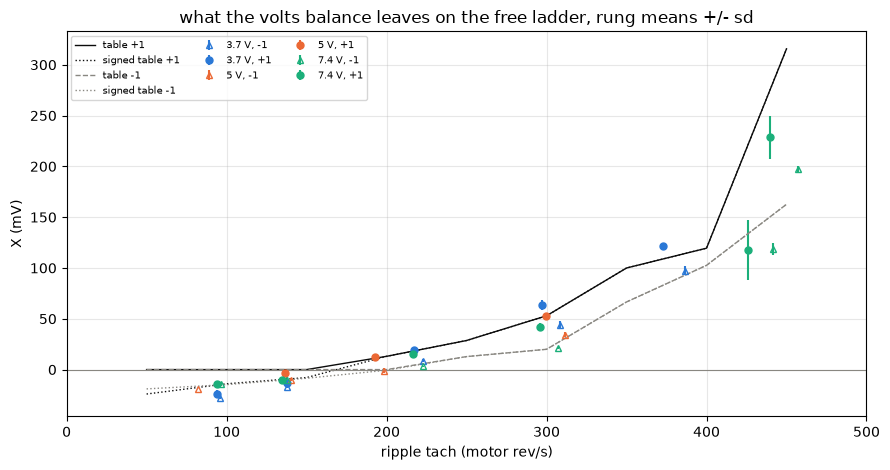

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.8))
RAIL_COLOR = {3.7: BLUE, 5.0: ORANGE, 7.4: GREEN}
for (v_, d), h in RM.groupby(["volts_set", "dir"]):
    style = figures.direction_style(d, RAIL_COLOR[v_])
    ax.errorbar(h["rev_s"], h["x_mv"], yerr=h["sd"], ms=5,
                label=f"{v_:g} V, {d:+d}", **style)
for d, c, ls in ((1, INK, "-"), (-1, MUTED, "--")):
    ax.plot(KNOTS, TABLE[d], ls=ls, color=c, lw=1, label=f"table {d:+d}")
    ax.plot(KNOTS, TABLE_SIGNED[d], ls=":", color=c, lw=1,
            label=f"signed table {d:+d}")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlim(0, 500)
ax.legend(fontsize=7, ncol=3)
figures.label(ax, x="ripple tach (motor rev/s)", y="X (mV)",
              title="what the volts balance leaves on the free ladder, "
                    "rung means +/- sd")
figures.finish(fig)

What you are looking at. X per rung under the full construction against the tach's speed, colored by rail, filled +1 and open -1, with the clipped table per direction as lines and the signed table dotted.

Up to 140.1 rev/s X is negative on every rail and in both directions, -28.0 to -3.0 mV over the rungs at 82.1 to 140.1 rev/s. The line through the spins under 350 rev/s is c0 -52.8 +/- 4.4 mV, a direction term c_dir +11.2 +/- 2.0 mV on +1, a slope +0.303 +/- 0.013 mV per rev/s and a rail term -0.7 +/- 0.6 mV/V, -1.2 sigma, rms 7.9 mV over 67 spins. On 5 V it crosses zero at 150 rev/s in +1 and 187 in -1. The rail term is flat. At matched speed, 7.4 V less 3.7 V, X splits by -2.7 +/- 4.9 mV under the full construction. Without g the rails split by -78.9 +/- 4.6 mV, and with stage 1's constant zero in place of the awake zero by -29.9 +/- 5.2. The meter's g and the awake zero flatten the rails, high confidence.

A drop is not negative, so the clipped table is zero under 150 rev/s and leaves X's negative part in the estimate. The signed table follows it, -24.1 to -7.9 mV at 50 to 150 rev/s.

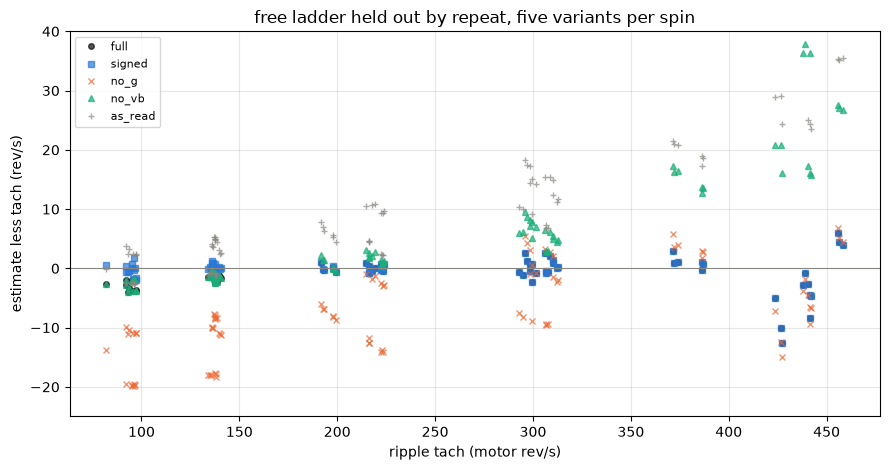

In [35]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for v, col, mk in (("full", INK, "o"), ("signed", BLUE, "s"),
                   ("no_g", ORANGE, "x"), ("no_vb", GREEN, "^"),
                   ("as_read", MUTED, "+")):
    e = HELD[f"w_{v}"] - HELD["truth"]
    ax.plot(HELD["truth"], e, mk, ms=4, alpha=0.7, color=col, label=v,
            ls="none")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylim(-25, 40)
ax.legend(fontsize=8)
figures.label(ax, x="ripple tach (motor rev/s)",
              y="estimate less tach (rev/s)",
              title="free ladder held out by repeat, five variants per spin")
figures.finish(fig)

What you are looking at. Each held-out ladder spin's estimate less its tach, for five of the variants.

Held out by repeat, the full estimate reads -2.78 +/- 0.23 rev/s at 94.0 rev/s (rms 2.89, -2.96 %), -1.47 +/- 0.15 at 137.5 (rms 1.60), -0.01 +/- 0.13 at 211.8 (rms 0.53), +0.31 +/- 0.31 at 303.3 (rms 1.32, 0.44 %), and -2.99 +/- 1.17 and +4.81 +/- 0.62 on the top two bands, whose rungs are run-ups the runway cut before they settled. Over all 85 spins it reads -1.03 +/- 0.29 rev/s, rms 2.84, 1.45 %. The reference rung, 5 V 30 % at 141.4 rev/s, reads -0.70 +/- 0.15 rev/s over three sittings, rms 1.11, n 35, and -1.75 to +1.20 by set and direction, on the table read in sitting 1. Against the README's 2 to 4 % above 100 rev/s the free shaft sits at 0.25 to 1.24 % rms per band.

What each term is worth, with the table refitted without it.

- The reading term is the largest at low speed. Without g the estimate reads -15.09 +/- 1.25 rev/s at 94 rev/s and -12.25 +/- 1.02 at 137, +12.81 and +11.35 rev/s of rms added.
- The brush table carries the estimate above 160 rev/s. Without it the rms grows by +1.12, +4.88, +16.84 and +22.26 rev/s on the bands at 211.8, 303.3, 413.2 and 456.9 rev/s.
- The constant zero in place of the awake zero adds +0.20 to +1.47 rev/s of rms under 350 rev/s.
- R(T) moves the rms by 0.42 rev/s at most, since the board stayed near room temperature (section 10). The brake loop in place of the brake line moves it by -0.42 to +0.01 rev/s, not a finding, and k_d by -0.2 at most.
- The as-read construction adds +1.89 to +30.48 rev/s of rms from 137 rev/s up and reads +0.10 +/- 0.74 at 94 rev/s, where the missing reading term pulls it low and the missing brush drop pushes it high by about as much, the cancellation stage 2 described.

The signed table takes the 30-100 band to -0.27 +/- 0.29 rev/s (rms 1.05) and the 100-160 band to -0.03 +/- 0.15 (rms 0.62), and leaves the bands above them where they were.

## 5. The crawl

### The low holds and the sag's crawls

`ladder/low-1` kicks the rotor and then holds a low effective volts on each rail. The sag runs a crawl at a fixed effective volts and a 30 % cycle at each rail as the DPS steps down. Both are scored against the ripple tach where it counts, on the table from every ladder spin, with the pot through the table beside it. A hold counts as turning when the pot and the coast's first EMF both read it turning.

In [36]:
LOW = read_cycles(LADDER_DIR / "low-1", "servo-1.csv",
                  label("ladder", "low-1"), "low", tag="low-1")
SAG_DIR = PAIR_DIR / "sag" / "capture-1"
LEVELS = pd.read_csv(SAG_DIR / "levels.csv")   # folders per rail and kind
pr = probes("servo-1.csv")
parts = []
for _, info in LEVELS.iterrows():
    if info["what"] not in ("crawl", "cycle"):
        continue
    df, meta, board = load(SAG_DIR / info["folder"])
    rail, ntc = rail_and_ntc(pr.get(label("sag", "capture-1",
                                          info["folder"])), board)
    base = {"set": f"sag-{info['what']}", "k": int(info["k"]), "repeat": 0,
            "volts_set": float(info["volts_set"]),
            "rail_v": rail if np.isfinite(rail) else float(info["vsys_read"]),
            "ntc_c": ntc, "t_start": float(info["t_start"]),
            "rows_dropped": int(meta.get("rows_dropped", 0))}
    red = reduce_low_cycle if info["what"] == "crawl" else reduce_spin_cycle
    parts += red(df, meta, board, base)
SAGC = pd.DataFrame(parts)
H = pd.concat([LOW, SAGC], ignore_index=True)
print(f"low-1 {len(LOW)} holds, sag {len(SAGC)} crawls and cycles")

low-1 102 holds, sag 52 crawls and cycles


In [37]:
HOLD_FORMS = ("full", "signed", "no_g", "stage1_zero", "no_vb", "as_read")


def hold_variants(df):
    """{variant: rev/s} per row of the holds, with the full form's i_w."""
    cols = [df[c].to_numpy() for c in ("half_ticks", "v_on_v",
                                       "i_over_counts", "rail_v")]
    out = {}
    for v in HOLD_FORMS:
        c = construct(*cols, g=0.0 if v == "no_g" else None,
                      zero_mode="stage1" if v == "stage1_zero" else "awake",
                      awake_counts=df["awake_counts"].to_numpy())
        if v == "as_read":
            s1 = construct(*cols, zero_mode="stage1")
            out[v] = (c["v_a"] - K["r_locked"] * s1["i"]) / K["ke"]
            continue
        u = c["v_c"] - K["v0"] - r_of_t(df["ntc_c"].to_numpy()) * c["i_w"]
        if v == "no_vb":
            out[v] = u / K["ke"]
            continue
        u = u - K["k_d"] * df["dropouts_per_s"].to_numpy()
        tab = TABLE_SIGNED if v == "signed" else TABLE
        out[v] = solve_w(u, df["dir"].to_numpy(), tab)
        if v == "full":
            out["iw_ma"] = c["i_w"] * 1e3
    return out


for k_, v_ in hold_variants(H).items():
    H["w_" + k_ if k_ != "iw_ma" else "full_iw_ma"] = v_
H["valid"] = H["window_valid_share"] > 0.99
H["turning"] = flag(H["kept_turning"], True)   # a spin cycle has no flag
H["v_eff"] = H["rail_v"] * H["half_ticks"] / ARR
H["pot_abs"] = H["pot_rev_s"].abs()

In [38]:
def crest_ma(s):
    return (s.mean() - I_DRIVE_OFFSET) * A_PER_COUNT * 1e3


LV = H[H["set"] == "low-1"].groupby(["volts_set", "duty_pct"]).agg(
    v_eff=("v_eff", "mean"), valid=("valid", "mean"), n=("k", "size"),
    turning=("turning", "sum"), tach=("tach_rev_s", "mean"),
    pot=("pot_abs", "mean"), emf_first=("e_first_rev_s", "mean"),
    full=("w_full", "mean"), signed=("w_signed", "mean"),
    no_g=("w_no_g", "mean"), as_read=("w_as_read", "mean"),
    i_w_ma=("full_iw_ma", "mean"),
    i_crest_ma=("i_over_counts", crest_ma)).reset_index()
print("low-1 hold levels: valid share, turning holds, tach, pot, the "
      "coast's first EMF, the estimate's variants (rev/s), means per level")
print(LV.round(2).sort_values(["volts_set", "duty_pct"],
                              ascending=[True, False]).to_string(index=False))
stopped = LV[(LV["turning"] == 0) & (LV["volts_set"] == 7.4)]
print(f"7.4 V levels with no turning hold: the full estimate "
      f"{stopped['full'].min():+.1f} to {stopped['full'].max():+.1f} rev/s")

low-1 hold levels: valid share, turning holds, tach, pot, the coast's first EMF, the estimate's variants (rev/s), means per level
 volts_set  duty_pct  v_eff  valid  n  turning  tach   pot  emf_first   full  signed   no_g  as_read  i_w_ma  i_crest_ma
       3.7      16.0   0.59    1.0  6        6 41.09 42.07      37.28  36.70   39.65  28.00    41.48   53.91       65.92
       3.7      14.0   0.52    1.0  6        6 34.06 34.68      35.16  29.80   32.75  20.90    34.25   48.90       61.30
       3.7      11.0   0.41    1.0  6        6 23.39 23.58      25.72  19.55   22.51  10.32    23.70   41.13       53.88
       3.7       8.0   0.29    1.0  6        1 12.85  2.15       1.29  -1.74    1.21 -11.28     2.24   51.42       64.96
       3.7       7.0   0.26    1.0  6        0   NaN  0.02      -1.15  -2.94    0.02 -12.58     0.83   45.10       58.79
       3.7       5.0   0.18    0.0  6        0   NaN  0.00      -0.57 -18.49  -15.53 -23.34   -12.65   37.46       43.00
       5.0      12.0   

In [39]:
HT = H[H["valid"] & H["turning"] & H["tach_rev_s"].notna()
       & (H["tach_cycles"] >= MIN_CYCLES)].copy()
HT["truth"] = HT["tach_rev_s"]
HT["band"] = band_of(HT["truth"])
HCOLS = [f"w_{v}" for v in HOLD_FORMS]
S_HOLD = by_band(score(HT, HCOLS, by=("set", "band")), "set")
print("turning holds and sag cycles with a valid window and a ripple "
      "count: the estimate less the tach")
print(fmt(S_HOLD, ["w_full", "w_signed", "w_no_g", "w_stage1_zero"],
          keys=("set", "band"), pct=False))
HP = H[H["valid"] & H["turning"] & H["pot_abs"].notna()
       & (H["pot_abs"] > 1)].copy()
HP["truth"] = HP["pot_abs"]
HP["band"] = band_of(HP["truth"])
S_HOLD_POT = by_band(score(HP, HCOLS, by=("set", "band")), "set")
print("\nthe same against the pot through the table")
print(fmt(S_HOLD_POT, ["w_full", "w_signed"], keys=("set", "band"),
          pct=False))
tp = HT["tach_rev_s"] / HT["pot_abs"]
print(f"\ntach over the pot on the holds {tp.mean():.3f} sd {tp.std():.3f} "
      f"n {len(tp)}")

turning holds and sag cycles with a valid window and a ripple count: the estimate less the tach
      set    band  n  rev_s              w_full            w_signed                w_no_g       w_stage1_zero
    low-1    0-30 14   21.8 -3.01+/-0.24 / 3.14 -0.11+/-0.28 / 1.01 -14.10+/-0.28 / 14.14 -2.31+/-0.09 / 2.33
    low-1  30-100 35   37.4 -3.29+/-0.15 / 3.40 -0.32+/-0.17 / 1.03 -16.84+/-0.71 / 17.34 -3.59+/-0.21 / 3.79
sag-crawl    0-30  4   29.2 -6.47+/-1.23 / 6.81 -3.69+/-1.22 / 4.25 -25.79+/-1.74 / 25.97 -8.38+/-1.19 / 8.63
sag-crawl  30-100 22   32.6 -3.95+/-0.49 / 4.53 -0.96+/-0.50 / 2.48 -22.37+/-0.85 / 22.71 -6.03+/-0.50 / 6.45
sag-cycle 160-250 24  210.4 +0.98+/-0.12 / 1.15 +1.11+/-0.13 / 1.26 -12.39+/-0.33 / 12.49 -1.05+/-0.16 / 1.29
sag-cycle 250-350  2  253.6 -0.41+/-0.07 / 0.42 -0.41+/-0.07 / 0.42 -16.03+/-0.30 / 16.03 -2.55+/-0.36 / 2.57

the same against the pot through the table
      set    band  n  rev_s              w_full            w_signed
    low-1    0-30 14  

In [40]:
def by_rail(df):
    """Per rail: the tach and each form's error, and its slope on the rail."""
    g = df.groupby("volts_set").agg(
        n=("k", "size"), tach=("truth", "mean"), full=("w_full", "mean"),
        no_g=("w_no_g", "mean"), s1=("w_stage1_zero", "mean")).reset_index()
    for c in ("full", "no_g", "s1"):
        g[c + "_err"] = g[c] - g["tach"]
    slopes = {c: np.polyfit(g["volts_set"], g[c + "_err"], 1)[0]
              for c in ("full", "no_g", "s1")}
    return g, slopes


SAG_CRAWL, SLOPE_CRAWL = by_rail(HT[HT["set"] == "sag-crawl"])
SAG_CYCLE, SLOPE_CYCLE = by_rail(HT[HT["set"] == "sag-cycle"])
print("sag crawls at 0.5 V effective by rail: errors (rev/s)")
print(SAG_CRAWL.round(2).to_string(index=False))
print("slopes on the rail (rev/s per V): " + ", ".join(
    f"{c} {s:+.2f}" for c, s in SLOPE_CRAWL.items()))
under = SAG_CRAWL[SAG_CRAWL["volts_set"] <= 7.6]
print(f"6.0 to 7.6 V: full {under['full_err'].max():+.2f} to "
      f"{under['full_err'].min():+.2f} rev/s, slope "
      f"{np.polyfit(under['volts_set'], under['full_err'], 1)[0]:+.2f}")
print("\nsag 30 % cycles by rail: slopes (rev/s per V): " + ", ".join(
    f"{c} {s:+.2f}" for c, s in SLOPE_CYCLE.items()))

sag crawls at 0.5 V effective by rail: errors (rev/s)
 volts_set  n  tach  full  no_g    s1  full_err  no_g_err  s1_err
       6.0  2 30.40 28.26 12.72 26.35     -2.14    -17.68   -4.05
       6.2  2 31.74 29.60 13.53 27.49     -2.14    -18.21   -4.25
       6.4  2 33.93 31.79 15.20 29.02     -2.14    -18.73   -4.91
       6.6  2 34.91 32.49 15.39 30.43     -2.42    -19.52   -4.48
       6.8  2 30.21 27.41  9.62 25.83     -2.80    -20.59   -4.38
       7.0  2 31.38 28.11  9.78 26.12     -3.26    -21.60   -5.26
       7.2  2 32.23 29.22 10.36 26.88     -3.01    -21.86   -5.35
       7.4  2 34.56 31.19 11.82 28.85     -3.37    -22.74   -5.71
       7.6  2 35.68 31.86 11.96 30.38     -3.81    -23.72   -5.29
       7.8  2 29.09 21.50  1.83 19.91     -7.59    -27.27   -9.19
       8.0  2 29.50 22.06  1.89 19.58     -7.44    -27.61   -9.92
       8.2  2 31.19 23.19  2.49 21.28     -8.00    -28.70   -9.91
       8.4  2 31.89 23.67  2.49 21.46     -8.22    -29.41  -10.44
slopes on the rail (re

On the turning low holds the full estimate reads -3.01 +/- 0.24 rev/s at 21.8 rev/s and -3.29 +/- 0.15 at 37.4 against the tach, and the sag's crawls -3.95 +/- 0.49 at 32.6 rev/s, rms 3.14, 3.40 and 4.53. The signed table takes them to -0.11 +/- 0.28, -0.32 +/- 0.17 and -0.96 +/- 0.50. Without g they read -14.10, -16.84 and -22.37. The sag's 30 % cycles at 210.4 rev/s, on rails the ladder never saw, read +0.98 +/- 0.12, rms 1.15. The tach over the pot reads 0.984 sd 0.020 over 101 holds.

The sag's crawls follow the rail. From 6.0 to 7.6 V the error runs -2.14 to -3.81 rev/s, -1.08 rev/s per volt, and from 7.8 V up it steps to -7.44 to -8.22 rev/s. The step is the tap floor below (discrepancy 5). The 30 % cycles move by -0.46 rev/s per volt, and without g by -2.22.

Under the floor the holds stop. At 7.4 V the levels with no turning hold sit under the current's window floor, a valid share of 0.0, and their full estimate reads -46.9 to -42.4 rev/s on a stopped rotor, the number the estimate gives there when the flag is not honored.

### The camera sitting

The tag on the horn is the outside truth. Each clip's frames go on the host clock by a line through the STAT flashes against the clapper's log, the pot-table notebook's fit. Each chain's rows go on the camera's clock by the stamps' lead over the tag's motion, read per group of segments by correlation. Windows tile each held segment, half-overlapping. In each window the tag's speed is a line through its frames, the pot's speed a line and a two-point difference through the table, and each form of the estimate the mean of its per-row solve over the window's valid rows. The ripple tach runs over the 100 ms windows, seeded by the tag. The awake zero is the group's own coast tail where it has one, and the ladder's line at the rail where it does not.

In [41]:
POT_DIR = PAIR_DIR / "pot-table"
BLOCKS = ("pass-open-9", "crawl-9", "reversal-9", "steps-9", "pass-close-9")
HALF_FLASH_S = 0.050        # s, a STAT flash's half length
SKIP_S, END_S = 0.15, 0.02  # s, a held segment's spin-up out, its end out
WINDOWS_MS = (50, 100, 200, 300, 500)   # ms, the windows tiled
MIN_FRAMES = 6              # tag frames a window needs at least
POT_BOX_ROWS = 41           # rows, the pot's boxcar before the table
TACH_SEED_MIN_HZ = 30       # Hz, the clips' tach takes a seed over this
CRAWL_DUTY_MIN = 6.5        # %, the held segments scored sit over this
MOVING_DEG_S = 2.0          # deg/s, a frame moving for the position grade
# the lead search: span, step, grid and smoothing (pot-table's method)
LEAD_SEARCH_S, LEAD_STEP_S, LEAD_GRID_S, LEAD_SMOOTH = 0.06, 0.0005, 0.001, 10
# the segments of a chain that share one lead, per kind
GROUPS = {"pass": ((1, 2), (3, 4)), "crawl": ((1, 2, 3), (4, 5, 6)),
          "reversal": ((1, 2, 3), (4, 5, 6)), "steps": ((1, 2, 3), (4, 5, 6))}
print(f"windows of {', '.join(map(str, WINDOWS_MS))} ms from "
      f"{SKIP_S * 1e3:.0f} ms into a held segment to {END_S * 1e3:.0f} ms "
      f"before its end; held segments at {CRAWL_DUTY_MIN} % and over scored")

windows of 50, 100, 200, 300, 500 ms from 150 ms into a held segment to 20 ms before its end; held segments at 6.5 % and over scored


In [42]:
def clip_clock(block_dir, clip):
    """Container time to host time: a line through the STAT flashes'
    midpoints against the clapper's host times (pot-table's fit)."""
    stat = pd.read_csv(block_dir / f"{clip}.stat.csv")
    clap = pd.read_csv(block_dir / f"{clip}-clapper.csv")
    b = fd.bursts(stat["t"], stat["level"])
    if len(b) != len(clap):
        raise ValueError(f"{clip}: {len(b)} flashes, {len(clap)} logged")
    h0 = float(clap["t_before"].iloc[0])
    host = clap["t_before"] - h0
    mid = (b["on"] + b["off"]) / 2
    off_m, rate_m, rms_m = fd.fit_clock(mid, host + HALF_FLASH_S)
    return {"h0": h0, "offset": off_m, "rate": rate_m, "rms_ms": rms_m * 1e3}


def clip_angles(block_dir, clip):
    """Per frame: host time and the horn's image angle."""
    ck = clip_clock(block_dir, clip)
    a = fd.angles(pd.read_csv(block_dir / f"{clip}.corners.csv"))
    return pd.DataFrame({
        "frame": a["frame"], "t": a["t"],
        "host": ck["h0"] + (a["t"] - ck["offset"]) / ck["rate"],
        "deg": a["image_deg"], "both": np.isfinite(a["image_deg"])}), ck


def boxcar(x, n):
    """A centered running mean of n rows, shortened at the ends."""
    x = np.asarray(x, float)
    k = np.ones(n)
    return np.convolve(x, k, "same") / np.convolve(np.ones_like(x), k, "same")

In [43]:
def lead_of(tags, rows):
    """(shift s, correlation): the pot stamps' lead over the tag's motion,
    the correlation of the two speeds on a 1 ms grid, its peak refined by
    a parabola (pot-table's method)."""
    f = tags[tags["both"]]
    t0, t1 = rows["host"].min(), rows["host"].max()
    f = f[(f["host"] >= t0 - 0.3) & (f["host"] <= t1 + 0.3)]
    grid = np.arange(t0 - 0.1, t1 + 0.1, LEAD_GRID_S)
    va = np.diff(uniform_filter1d(np.interp(grid, f["host"], f["deg"]),
                                  LEAD_SMOOTH))
    offs = np.arange(-LEAD_SEARCH_S, LEAD_SEARCH_S + LEAD_STEP_S / 2,
                     LEAD_STEP_S)
    cs = np.array([np.corrcoef(va, np.diff(uniform_filter1d(
        np.interp(grid, rows["host"] + o, rows["pos"]), LEAD_SMOOTH)))[0, 1]
        for o in offs])
    i = int(np.argmax(cs))
    if 0 < i < len(cs) - 1:
        y0, y1, y2 = cs[i - 1:i + 2]
        step = 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * LEAD_STEP_S
        return offs[i] + step, cs[i]
    return offs[i], cs[i]

In [44]:
CLIPS = {}
for block in BLOCKS:
    for p in sorted((POT_DIR / block).glob("*.corners.csv")):
        clip = p.name.replace(".corners.csv", "")
        if clip == "board":
            continue
        tags, ck = clip_angles(POT_DIR / block, clip)
        CLIPS[(block, clip)] = {"tags": tags, "clock": ck,
                                "span": (tags["host"].min(),
                                         tags["host"].max())}
print(f"{len(CLIPS)} clips; clock rms " + ", ".join(
    f"{v['clock']['rms_ms']:.1f}" for v in CLIPS.values()) + " ms")

10 clips; clock rms 1.7, 0.7, 1.2, 1.3, 1.5, 1.6, 1.2, 1.5, 1.7, 1.4 ms


In [45]:
PR_CAM = probes("servo-camera-9.csv")
CHAINS = []
for block in BLOCKS:
    kind = block.split("-")[0]
    for _, r in pd.read_csv(POT_DIR / block / "chains.csv").iterrows():
        folder = POT_DIR / block / "chains" / str(int(r["k"]))
        df, meta, board = load(folder)
        seg = pd.read_csv(folder / "segments.csv").set_index("seg")
        df["host"] = (df["seg"].map(seg["t_start"])
                      + df["tick"] / meta["tick_hz"])
        zero_i, zero_e = tel.rest_zeros(df)
        rail, ntc = rail_and_ntc(PR_CAM.get(label(
            "pot-table", block, "chains", int(r["k"]))), board)
        clip = next((c for (b, c), v in CLIPS.items() if b == block
                     and v["span"][0] <= r["t_start"] + 0.5
                     and v["span"][1] >= r["t_start"]), None)
        if clip is None:
            print(f"  {block} chain {r['k']}: no clip covers it")
            continue
        tags = CLIPS[(block, clip)]["tags"]
        leads = {gi: lead_of(tags, df[df["seg"].isin(segs)])
                 for gi, segs in enumerate(GROUPS[kind])}
        CHAINS.append({"block": block, "kind": kind, "k": int(r["k"]),
                       "clip": clip, "df": df, "seg": seg, "zero_i": zero_i,
                       "rail_v": rail, "ntc_c": ntc, "leads": leads,
                       "share": r.get("start_share", np.nan),
                       "step_pct": r.get("step_pct", np.nan)})
LEADS = [v for c in CHAINS for v in c["leads"].values()]
print(f"{len(CHAINS)} chains; leads {min(x[0] for x in LEADS) * 1e3:+.0f} "
      f"to {max(x[0] for x in LEADS) * 1e3:+.0f} ms; correlations min "
      f"{min(x[1] for x in LEADS):.2f}")

21 chains; leads -0 to +23 ms; correlations min 0.89


In [46]:
def row_estimates(g, d, c, awake_counts):
    """Per row of one segment: the volts u (before the dropout term) for
    each speed-table form, and the rows a window averages over."""
    half = g["duty_counts"].abs().to_numpy(float)
    taps = ((g["vmotor_a"] - g["vmotor_b"]) * d).to_numpy(float)
    v_on = SC.volts(taps, TAP_OFFSET)
    i_over = g["current_raw"].to_numpy(float) - c["zero_i"]
    valid = ((g["window_valid"].to_numpy() == 1) & np.isfinite(v_on)
             & (half > 0))
    out = {"valid": valid, "v_on": v_on, "i_over": i_over}
    r_t = r_of_t(np.full(len(g), c["ntc_c"]))
    for name, g_, zero in (("full", None, "awake"), ("no_g", 0.0, "awake"),
                           ("stage1_zero", None, "stage1")):
        cc = construct(half, v_on, i_over, c["rail_v"], g=g_,
                       zero_mode=zero, awake_counts=awake_counts)
        out["u_" + name] = cc["v_c"] - K["v0"] - r_t * cc["i_w"]
        if name == "full":     # kept for the current term's forms
            out.update(i_w=cc["i_w"], i_w_ma=cc["i_w"] * 1e3,
                       v_c=cc["v_c"], r_t=r_t)
    s1 = construct(half, v_on, i_over, c["rail_v"], zero_mode="stage1")
    out["w_as_read"] = (s1["v_a"] - K["r_locked"] * s1["i"]) / K["ke"]
    return out

In [47]:
SPEED_FORMS = {"w_full": ("u_full", "table"),
               "w_signed": ("u_full", "signed"),
               "w_no_g": ("u_no_g", "table"),
               "w_stage1_zero": ("u_stage1_zero", "table")}


def window_estimates(est, m, d, forms, tables):
    """Each form over one window's valid rows: the dropout rate from the
    window's own rows, the mean of the per-row solve."""
    ok = m & est["valid"]
    n = int(ok.sum())
    out = {"rate": np.nan, "w_no_vb": np.nan, "w_as_read": np.nan}
    out.update({c: np.nan for c in forms})
    if n < 20:
        return out
    rate = float(tel.dropout_rows(est["i_over"][ok]).sum() / (n / FS))
    kd = K["k_d"] * rate
    dd = np.full(n, d)
    for col, (key, tab) in forms.items():
        out[col] = float(solve_w(est[key][ok] - kd, dd, tables[tab]).mean())
    out["rate"] = rate
    if "u_full" in est:         # the clips' first pass, not the r_b one
        out["w_no_vb"] = float((est["u_full"][ok] / K["ke"]).mean())
        out["w_as_read"] = float(est["w_as_read"][ok].mean())
    return out


SPEED_TABLES = {"table": TABLE, "signed": TABLE_SIGNED}

In [48]:
def window_row(est, frames, a, wms, d, raw):
    """One window of `wms` from host time `a`: the tag's speed (a line
    through its frames), the pot's (two points and a line), the forms."""
    b = a + wms / 1e3
    ta, pdeg = est["ta"], est["pdeg"]
    fr = frames[(frames["host"] >= a) & (frames["host"] < b)]
    rows_m = (ta >= a) & (ta < b)
    if len(fr) < MIN_FRAMES or rows_m.sum() < 20:
        return None
    tag_v = np.polyfit(fr["host"] - a, fr["deg"], 1)[0] / DEG_S_PER_REV_S * d
    pw = pdeg[rows_m]
    okp = np.isfinite(pw)
    if okp.sum() < 10:
        return None
    tt = ta[rows_m][okp] - a
    to_rev = DEG_S_PER_REV_S * d        # deg/s at the horn per motor rev/s
    rec = {"w_ms": wms, "t0": a, "t_in_seg": a - ta[0], "n_frames": len(fr),
           "tag": tag_v, "pot_line": np.polyfit(tt, pw[okp], 1)[0] / to_rev,
           "pot_two": (pw[okp][-1] - pw[okp][0]) / (tt[-1] - tt[0]) / to_rev,
           "pos_mid": float(np.nanmean(est["pos_box"][rows_m])),
           "tag_deg_mid": float(fr["deg"].mean()),
           "valid_share": float(est["valid"][rows_m].mean()),
           "v_on": float(np.nanmean(est["v_on"][rows_m])),
           "i_w_ma": float(np.nanmean(np.where(
               est["valid"], est["i_w_ma"], np.nan)[rows_m]))}
    rec.update(window_estimates(est, rows_m, d, SPEED_FORMS, SPEED_TABLES))
    if wms == 100:              # the ripple tach, seeded by the tag
        seed = abs(tag_v) * N_R
        x = raw[rows_m]
        try:
            f, nc = (ripple.count_cycles(x - x.mean(), seed)
                     if seed > TACH_SEED_MIN_HZ else (np.nan, 0))
        except Exception:
            f, nc = np.nan, 0
        rec["tach"], rec["tach_cycles"] = f / N_R if nc >= 4 else np.nan, nc
    return rec

In [49]:
def read_segment(c, s, lead, awake, frames):
    """(window rows, frame rows, segment row, row estimates) of one held
    segment, its rows put on the camera's clock by the group's lead."""
    g = c["df"][c["df"]["seg"] == s]
    duty_q15 = int(c["seg"].loc[s, "cmd_duty_q15"])
    d = int(np.sign(duty_q15))          # the drive's sign: + along it
    est = row_estimates(g, d, c, awake)
    est["ta"] = g["host"].to_numpy() + lead   # the pot's rows, camera clock
    est["pos_box"] = boxcar(g["pos"].to_numpy(float), POT_BOX_ROWS)
    est["pdeg"] = pot_deg(est["pos_box"])
    ta = est["ta"]
    fs = frames[(frames["host"] >= ta[0]) & (frames["host"] <= ta[-1])]
    fr = pd.DataFrame({"host": fs["host"].to_numpy(), "dir": d, "seg": s,
                       "tag_deg": fs["deg"].to_numpy(),
                       "pot_deg": np.interp(fs["host"], ta, est["pdeg"]),
                       "pot_speed": np.interp(fs["host"], ta,
                                              np.gradient(est["pdeg"], ta))})
    duty_pct = abs(duty_q15) / 32768 * 100
    kind = c["kind"]
    lab = ("kick" if duty_pct > 25 and kind != "pass" else kind)
    t_lo = ta[0] + (0.0 if lab == "kick" else SKIP_S)
    raw = g["current_raw"].to_numpy(float)
    wins = []
    for wms in WINDOWS_MS:
        wsec = wms / 1e3
        for a in np.arange(t_lo, ta[-1] - END_S - wsec + 1e-9, wsec / 2):
            rec = window_row(est, fs, a, wms, d, raw)
            if rec is not None:
                wins.append({"seg": s, "dir": d, "duty_pct": duty_pct,
                             "label": lab, **rec})
    srow = {"seg": s, "dir": d, "duty_pct": duty_pct, "label": lab,
            "valid_share": float(est["valid"].mean()), "rail_v": c["rail_v"],
            "v_on": float(np.nanmean(est["v_on"][est["valid"]]))
            if est["valid"].any() else np.nan}
    return wins, fr, srow, est

In [50]:
WIN_ROWS, FRAME_PARTS, SEG_ROWS, SEG_EST = [], [], [], []
for c in CHAINS:
    tags = CLIPS[(c["block"], c["clip"])]["tags"]
    tf = tags[tags["both"]]
    tag_c = {"block": c["block"], "kind": c["kind"], "k": c["k"]}
    for gi, segs in enumerate(GROUPS[c["kind"]]):
        lead = c["leads"][gi][0]
        coasts = [s for s in segs if c["seg"].loc[s, "cmd_duty_q15"] == 0]
        if coasts:      # the group's own coast tail gives the awake zero
            co = c["df"][c["df"]["seg"] == coasts[-1]]
            awake = float(co["current_raw"].iloc[-TAIL_ROWS:].mean()
                          - c["zero_i"])
        else:           # else the ladder's awake line at the rail
            awake = K["awake_per_v"] * c["rail_v"] + K["awake_c0"]
        for s in segs:
            if c["seg"].loc[s, "cmd_duty_q15"] == 0:
                continue
            wins, fr, srow, est = read_segment(c, s, lead, awake, tf)
            i = len(SEG_EST)
            SEG_EST.append({k: est[k] for k in (
                "ta", "valid", "i_over", "v_c", "i_w", "r_t")})
            WIN_ROWS += [{**tag_c, "seg_i": i, "share": c["share"],
                          "awake_src": "coast" if coasts else "line", **w}
                         for w in wins]
            if len(fr):
                FRAME_PARTS.append(fr.assign(**tag_c))
            SEG_ROWS.append({**tag_c, "lead_ms": lead * 1e3, **srow})
WIN = pd.DataFrame(WIN_ROWS)
FR = pd.concat(FRAME_PARTS, ignore_index=True)
SEG = pd.DataFrame(SEG_ROWS)
print(f"{len(WIN)} windows, {len(FR)} frames, {len(SEG)} segments")

3234 windows, 9719 frames, 88 segments


In [51]:
print("V_on over the held segments by duty: mean, valid share, rail")
TAPS = SEG.groupby(["label", SEG["duty_pct"].round()]).agg(
    n=("k", "size"), v_on=("v_on", "mean"), valid=("valid_share", "mean"),
    rail=("rail_v", "mean")).reset_index()
print(TAPS.round(3).to_string(index=False))
crawl = TAPS[TAPS["label"] == "crawl"]
floor_row = crawl[crawl["duty_pct"] == 6]
TAP_FLOOR_HALF_TICKS = round(6 / 100 * ARR)   # the 6 % crawl's half ticks
print(f"6 % crawl ({TAP_FLOOR_HALF_TICKS} half-ticks) V_on "
      f"{floor_row['v_on'].iloc[0]:.2f} V, valid share "
      f"{floor_row['valid'].iloc[0]:.3f}; 7 to 11 % "
      f"{crawl[crawl['duty_pct'] >= 7]['v_on'].min():.2f} to "
      f"{crawl[crawl['duty_pct'] >= 7]['v_on'].max():.2f} V from "
      f"{round(7 / 100 * ARR)} half-ticks up; the board's window floors "
      f"{BOARD.v_window_min_ticks} half-ticks for the taps, "
      f"{BOARD.i_window_min_ticks} for the current")
TAP_LOW_V = crawl[crawl["duty_pct"] >= 7]["v_on"].mean() - floor_row[
    "v_on"].iloc[0]
print(f"the 6 % taps read {TAP_LOW_V:.2f} V under the 7 to 11 % ones")

V_on over the held segments by duty: mean, valid share, rail
   label  duty_pct  n  v_on  valid  rail
   crawl       6.0  6 4.596  1.000 4.989
   crawl       7.0  6 4.922  1.000 4.993
   crawl       8.0  6 4.930  1.000 4.989
   crawl       9.0  6 4.934  1.000 4.985
   crawl      11.0  6 4.931  1.000 4.984
    kick      30.0 38 4.874  0.998 4.988
    pass      20.0  4 4.910  1.000 4.991
reversal       9.0  4 4.930  1.000 4.993
reversal      20.0  4 4.912  1.000 4.985
   steps       8.0  2 4.932  1.000 4.997
   steps       9.0  4 4.934  1.000 4.985
   steps      10.0  2 4.931  1.000 4.973
6 % crawl (72 half-ticks) V_on 4.60 V, valid share 1.000; 7 to 11 % 4.92 to 4.93 V from 84 half-ticks up; the board's window floors 93 half-ticks for the taps, 64 for the current
the 6 % taps read 0.33 V under the 7 to 11 % ones


In [52]:
W100 = WIN[(WIN["w_ms"] == 100) & (WIN["valid_share"] > 0.99)].copy()
W100["truth"] = W100["tag"]             # the tag's speed is the truth
W100["band"] = band_of(W100["truth"])
STEADY = W100[W100["label"].isin(["crawl", "pass", "steps"])
              & (W100["duty_pct"] >= CRAWL_DUTY_MIN)].copy()
CCOLS = ["w_full", "w_signed", "w_no_g", "w_stage1_zero", "w_no_vb",
         "w_as_read", "tach"]
S_CLIP = by_band(score(STEADY, CCOLS))
print("against the tag, 100 ms windows, held segments at >= 7 % duty")
print(fmt(S_CLIP, CCOLS, pct=False))
S_CLIP_LAB = score(STEADY, ["w_full", "w_signed", "w_as_read", "tach"],
                   by=("label", "duty_pct", "dir"))
print("\nby label, duty and direction: mean rev/s")
print(S_CLIP_LAB[["label", "duty_pct", "dir", "n", "rev_s", "w_full_mean",
                  "w_signed_mean", "w_as_read_mean", "tach_mean"]].round(2)
      .to_string(index=False))

against the tag, 100 ms windows, held segments at >= 7 % duty
  band   n  rev_s              w_full            w_signed                w_no_g       w_stage1_zero             w_no_vb           w_as_read                tach
  0-30 362   17.4 -2.58+/-0.09 / 3.13 +0.38+/-0.10 / 1.89 -15.68+/-0.09 / 15.78 -2.86+/-0.09 / 3.38 -2.58+/-0.09 / 3.13 -1.27+/-0.10 / 2.25 +0.04+/-0.12 / 1.95
30-100 152   53.2 -3.59+/-0.20 / 4.32 -0.88+/-0.20 / 2.58 -15.84+/-0.21 / 16.05 -3.86+/-0.19 / 4.55 -3.59+/-0.20 / 4.32 -1.49+/-0.21 / 2.99 -0.87+/-0.20 / 2.56

by label, duty and direction: mean rev/s
label  duty_pct  dir  n  rev_s  w_full_mean  w_signed_mean  w_as_read_mean  tach_mean
crawl       7.0   -1 63  15.39        -2.84          -0.24           -2.02      -0.10
crawl       7.0    1 63   8.10        -2.46           0.84           -1.22      -0.21
crawl       8.0   -1 52  20.83        -3.30          -0.69           -2.03      -0.22
crawl       8.0    1 52  11.25        -2.50           0.81           -0.

In [53]:
low6 = W100[(W100["label"] == "crawl") & (W100["duty_pct"] < CRAWL_DUTY_MIN)]
S_FLOOR = score(low6.assign(band="under the floor"),
                ["w_full", "w_as_read", "tach"])
print("crawl holds at 6 % (under the tap floor): mean / rms rev/s")
print(fmt(S_FLOOR, ["w_full", "w_as_read", "tach"], pct=False))
KICK = W100[W100["label"] == "kick"]
print("\nthe kicks (30 % for 150 ms, speeding up), against the tag")
print(fmt(score(KICK, ["w_full", "w_as_read", "tach"]),
          ["w_full", "w_as_read", "tach"], pct=False))
REV = W100[W100["label"] == "reversal"]
print("\nreversal levels (9 and 20 %, then their negatives)")
print(fmt(score(REV, ["w_full", "tach"], by=("duty_pct", "dir")),
          ["w_full", "tach"], keys=("duty_pct", "dir"), pct=False))
rip = STEADY[STEADY["label"] == "crawl"].groupby(["k", "seg"])["tag"].agg(
    ["mean", "std", "size"])
CRAWL_RIPPLE = float((rip["std"] / rip["mean"]).mean())
print(f"\ncrawl holds: the tag's speed sd over 100 ms windows within a "
      f"hold over its mean {CRAWL_RIPPLE:.3f}, {rip['size'].sum()} windows")

crawl holds at 6 % (under the tap floor): mean / rms rev/s
           band   n  rev_s              w_full           w_as_read                tach
under the floor 150    3.9 -6.10+/-0.08 / 6.18 -4.51+/-0.07 / 4.60 -0.36+/-0.29 / 1.48

the kicks (30 % for 150 ms, speeding up), against the tag
   band  n  rev_s              w_full           w_as_read                tach
100-160 27  120.0 -6.50+/-0.70 / 7.43 -0.87+/-0.72 / 3.79 +2.91+/-0.56 / 4.08

reversal levels (9 and 20 %, then their negatives)
 duty_pct  dir  n  rev_s              w_full                tach
 8.999634   -1 48   24.9 -3.01+/-0.14 / 3.16 +0.04+/-0.13 / 0.91
 8.999634    1 48   25.5 -2.57+/-0.14 / 2.74 -0.02+/-0.14 / 0.95
19.998169   -1 16   88.3 -3.36+/-0.35 / 3.63 -0.84+/-0.33 / 1.53
19.998169    1 16   88.0 -3.15+/-0.43 / 3.57 -0.51+/-0.41 / 1.68

crawl holds: the tag's speed sd over 100 ms windows within a hold over its mean 0.366, 386 windows


The 10 clips put the camera on the host clock to 0.7 to 1.7 ms rms, and the 21 chains' stamps lead the tag by 0 to 23 ms per group, every correlation 0.89 or more.

Against the tag over 100 ms, on the held segments at 7 % and over, the full estimate reads -2.58 +/- 0.09 rev/s at 17.4 rev/s (rms 3.13) and -3.59 +/- 0.20 at 53.2 (rms 4.32), what the holds and the sag's crawls read against the tach. The signed table reads +0.38 +/- 0.10 and -0.88 +/- 0.20, rms 1.89 and 2.58. Without g the estimate reads -15.68 and -15.84. The ripple tach, where it counts, agrees with the tag to +0.04 +/- 0.12 rev/s at the crawl and reads -0.87 +/- 0.20 at 53.2 rev/s, rms 1.95 and 2.56, so the two truths agree. The README's 1 to 3 rev/s at a crawl is met in rms by the signed table and missed by the clipped one.

By label the clipped table's offset is steady. Every crawl, pass and steps cell reads -2.28 to -3.63 rev/s, from 8.10 to 89.14 rev/s. It is one offset across the speeds the camera covers, not noise (discrepancy 2).

Under the tap floor the 6 % crawls, at 3.9 rev/s, read -6.10 +/- 0.08 rev/s while the tach reads -0.36 +/- 0.29. The 6 % taps read 0.33 V under the 7 to 11 % ones, 4.60 V against 4.92 to 4.93, with a valid share of 1.000. The board's window floors are 93 half-ticks for the taps and 64 for the current. The 6 % crawl runs at 72 and the 7 % holds, at 84, read normally. So the valid flag follows the current's floor and not the taps', and the taps fail somewhere between 72 and 84 half-ticks (discrepancy 7).

The kicks, the shaft speeding up at 30 %, read -6.50 +/- 0.70 rev/s at 120.0 rev/s. The crawl's own speed ripple is 0.366 of its mean, the sd of the tag's speed over 100 ms windows within a hold.

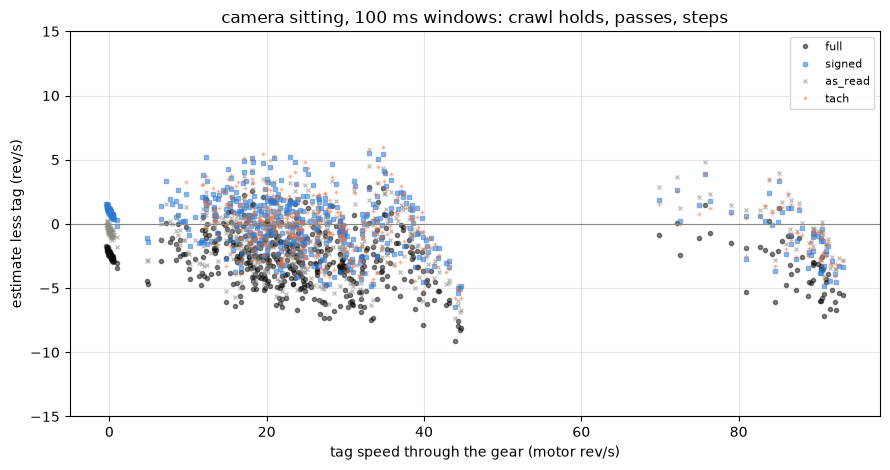

In [54]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for col, c_, mk in (("w_full", INK, "o"), ("w_signed", BLUE, "s"),
                    ("w_as_read", MUTED, "x"), ("tach", ORANGE, "+")):
    ax.plot(STEADY["truth"], STEADY[col] - STEADY["truth"], mk, ms=3,
            alpha=0.5, color=c_, label=col.replace("w_", ""), ls="none")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylim(-15, 15)
ax.legend(fontsize=8)
figures.label(ax, x="tag speed through the gear (motor rev/s)",
              y="estimate less tag (rev/s)",
              title="camera sitting, 100 ms windows: crawl holds, passes, "
                    "steps")
figures.finish(fig)

What you are looking at. Each 100 ms window's estimate less the tag's speed, with the clipped table, the signed table, the as-read construction and the ripple tach. The clipped table sits under zero all along the crawls and the passes, and the signed table and the tach sit on zero.

## 6. With current flowing

### The run-ups at 100 %

The run-ups drive 5 V at full duty from rest, so the current runs from the stall down toward the free current while the speed rises. Each turn window's truth is the order-tracked ripple count, the run-up notebook's, with the pot's local slope as its seed. At 100 % nothing switches, so the estimate is $E = u - V_0 - R(T)\,i - L\,di/dt - k_d\,\dot n_d - V_b$, with $u$ the tap volts and $i$ the current over the coast tail's awake zero. The table is the free ladder's.

In [55]:
RUNUP_SETS = {"runup-open-1": "servo-1.csv", "runup-close-1": "servo-1.csv",
              "runup-open-6": "servo-6.csv", "runup-close-6": "servo-6.csv",
              "runup-open-7": "servo-7.csv", "runup-close-7": "servo-7.csv"}
EDGE_ROWS, RUNUP_TAIL_ROWS = 40, 20     # rows a dropout is not read in
POT_SEED_S = (0.015, 0.045)             # s, the pot's seed for the count
POT_SLOPE_HALF_ROWS = 40                # rows, the pot slope's half span
DROPOUT_SPAN_S = 0.05                   # s, a window's rate span at least
KE_RAD = K["ke"] / (2 * np.pi)          # V s/rad
# the drag current the order count starts from, the type's 5 V meter fit
fit = NL_TYPE["drive_drag_by_level_meter"]["5 V"]
w_lo = 2 * np.pi * fit["speed_range_rev_s"]["lo"]
I_DRAG0 = float(fit["a_a"]["value"] + fit["b_a"]["value"]
                * np.log(max(w_lo, 1e-9) / (2 * np.pi * 100.0)))
print(f"order count seeded with the type's drag {I_DRAG0 * 1e3:.1f} mA")


def pot_speed_rad_s(pos, d):
    """The pot's local slope as motor rad/s, the nominal counts a turn."""
    return (ripple.local_line_slope(pos, POT_SLOPE_HALF_ROWS) * FS
            / SERVO.counts_per_motor_rev * 2 * np.pi * d)


def window_rates(rev, op):
    """The dropout rate around each turn window, over the turn or 50 ms."""
    rate = []
    for t_, w_ in zip(rev["t"], rev["w"]):
        half = max(np.pi / w_, DROPOUT_SPAN_S / 2)
        a = max(int(np.ceil((t_ - half) * FS)), 0)
        b = min(int(np.floor((t_ + half) * FS)), len(op))
        rate.append(op[a:b].sum() / ((b - a) / FS) if b > a else np.nan)
    return rate

order count seeded with the type's drag 43.5 mA


In [56]:
def read_runup(spin, co, d, zero_i, board):
    """(turn windows, run row) of one 100 % run-up: the order-tracked
    ripple count, each turn's mean current, volts and slope."""
    g = spin.iloc[tel.drive_start(spin):]
    counts = g["current_raw"].to_numpy(float)
    awake = float(co["current_raw"].iloc[-TAIL_ROWS:].mean())
    i_aw = (counts - awake) * A_PER_COUNT       # over the awake zero
    i_s1 = (counts - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT
    u = (((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - TAP_OFFSET)
         * V_PER_COUNT)
    op = tel.dropout_rows(i_s1, coast.local_mean(i_s1))
    op[:EDGE_ROWS] = False
    op[-RUNUP_TAIL_ROWS:] = False
    w_pot = pot_speed_rad_s(g["pos"].to_numpy(float), d)
    rough, scale = ripple.rough_speed(i_s1, u, w_pot, K["r_locked"],
                                      K["l_h"], KE_RAD, POT_SEED_S)
    count = ripple.count_speed(i_s1, rough, I_DRAG0, N_R)
    rev = ripple.rev_table(count["tc"], N_R, i_aw,
                           {"i_aw": i_aw, "i_s1": i_s1, "u": u}, op)
    rev["ok"] = ripple.flag_windows(rev["t"].to_numpy(), rev["w"].to_numpy())
    rev["rate"] = window_rates(rev, op)
    drive_s = len(counts) / FS
    row = {"held": bool((np.abs(g["duty_counts"].to_numpy())
                         == board.pwm_arr).all()),
           "rows": len(counts), "awake_step_counts": awake - zero_i,
           "dropouts": int(op.sum()), "dropouts_per_s": op.sum() / drive_s,
           "dropouts_last20ms_per_s": op[-400:].sum() / 0.02,
           "crossings": len(count["tc"]), "added": count["added"],
           "removed": count["removed"], "pot_scale": scale,
           "w_end_rev_s": rev["w"].iloc[-5:].mean() / (2 * np.pi),
           "i_end_a": i_aw[-100:].mean(),
           "window_valid_all": bool((g["window_valid"] == 1).all())}
    return rev, row

In [57]:
rows, windows = [], []
for name, csv in RUNUP_SETS.items():
    folder = PAIR_DIR / "run-up" / name
    pr = probes(csv)
    sitting = int(csv.split("-")[1].split(".")[0])
    for _, sw in pd.read_csv(folder / "cycles.csv").iterrows():
        df, meta, board = load(folder / sw["folder"])
        zero_i, zero_e = tel.rest_zeros(df)
        rail, ntc = rail_and_ntc(pr.get(label("run-up", name, sw["folder"])),
                                 board)
        for d, spin, co in coast.pairs(df):
            rev, row = read_runup(spin, co, d, zero_i, board)
            tags = {"set": name, "k": int(sw["k"]), "dir": d, "rail_v": rail,
                    "ntc_c": ntc, "sitting": sitting}
            windows.append(rev.assign(**tags))
            rows.append({**tags, **row})
RUNS = pd.DataFrame(rows)
RW = pd.concat(windows, ignore_index=True)
RW["truth"] = RW["w"] / (2 * np.pi)     # the order count, rev/s
RW["band"] = band_of(RW["truth"])
print(f"{len(RUNS)} run-ups, {len(RW)} turn windows, "
      f"{int((~RW['ok']).sum())} flagged; held {RUNS['held'].all()}, "
      f"window_valid {RUNS['window_valid_all'].all()}")
print(f"order count: pot seed scale {RUNS['pot_scale'].mean():.3f} sd "
      f"{RUNS['pot_scale'].std():.3f}, repairs +{RUNS['added'].sum()} "
      f"-{RUNS['removed'].sum()} of {RUNS['crossings'].sum()} crossings")
OK = RW[RW["ok"]].copy()

36 run-ups, 3505 turn windows, 59 flagged; held True, window_valid True
order count: pot seed scale 0.968 sd 0.040, repairs +2 -2 of 3721 crossings


In [58]:
RUNUP_FORMS = ["full", "signed", "no_kd", "no_l", "stage1_zero", "no_rt",
               "no_vb", "as_read"]


def runup_est(df, variant):
    """The estimate at 100 %: s = 1, no reading term, no brake; L di/dt
    off the volts."""
    i = (df["i_s1"] if variant == "stage1_zero" else df["i_aw"]).to_numpy()
    r = (np.full(len(df), K["r_c"]) if variant == "no_rt"
         else r_of_t(df["ntc_c"].to_numpy()))
    u = df["u"].to_numpy() - K["v0"] - r * i
    if variant != "no_l":
        u = u - K["l_h"] * df["didt"].to_numpy()
    if variant == "as_read":
        return ((df["u"].to_numpy() - K["r_locked"] * df["i_s1"].to_numpy())
                / K["ke"])
    if variant == "no_vb":
        return u / K["ke"]
    if variant != "no_kd":
        u = u - K["k_d"] * df["rate"].to_numpy()
    tab = TABLE_SIGNED if variant == "signed" else TABLE
    return solve_w(u, df["dir"].to_numpy(), tab)


for v in RUNUP_FORMS:
    OK[f"w_{v}"] = runup_est(OK, v)
RCOLS = [f"w_{v}" for v in RUNUP_FORMS]
S_RUN = by_band(score(OK, RCOLS))
S_RUN_DIR = by_band(score(OK, RCOLS, by=("band", "dir")), "dir")
S_RUN_SIT = by_band(score(OK, RCOLS, by=("sitting", "band")), "sitting")
print("run-up turn windows (100 % on 5 V): the full estimate less the "
      "order count")
print(fmt(S_RUN, ["w_full"]))

run-up turn windows (100 % on 5 V): the full estimate less the order count
   band    n  rev_s                w_full       w_full %
160-250  183  218.9 +29.51+/-0.28 / 29.74 +13.58 / 13.74
250-350  583  306.2 +26.43+/-0.20 / 26.89   +8.80 / 9.08
350-450 1397  408.7 +12.17+/-0.23 / 14.88   +3.10 / 3.84
450-600 1283  474.4  +2.76+/-0.29 / 10.87   +0.58 / 2.29


In [59]:
print("rms (rev/s) by band per variant, d = less the full one's")
tab = S_RUN[["band", "n"]].copy()
for v in RUNUP_FORMS:
    tab[v] = S_RUN[f"w_{v}_rms"].round(2)
    if v != "full":
        tab["d " + v] = (S_RUN[f"w_{v}_rms"] - S_RUN["w_full_rms"]).round(2)
print(tab.to_string(index=False))
cols = ["n", "rev_s", "w_full_mean", "w_full_se", "w_full_rms", "w_full_pct"]
print("\nby band and direction (full)")
print(S_RUN_DIR[["band", "dir", *cols]].round(2).to_string(index=False))
print("\nby sitting and band (full)")
print(S_RUN_SIT[["sitting", "band", *cols]].round(2).to_string(index=False))

rms (rev/s) by band per variant, d = less the full one's
   band    n  full  signed  d signed  no_kd  d no_kd  no_l  d no_l  stage1_zero  d stage1_zero  no_rt  d no_rt  no_vb  d no_vb  as_read  d as_read
160-250  183 29.74   29.75      0.01  30.29     0.55 26.58   -3.16        29.52          -0.22  29.58    -0.16  33.29     3.55    30.40       0.66
250-350  583 26.89   26.89      0.00  28.05     1.16 24.33   -2.56        26.67          -0.21  26.77    -0.12  37.26    10.37    35.72       8.84
350-450 1397 14.88   14.88      0.00  16.53     1.65 13.29   -1.59        14.72          -0.16  14.81    -0.07  39.26    24.38    39.33      24.45
450-600 1283 10.87   10.87      0.00  10.48    -0.39 10.57   -0.31        10.82          -0.05  10.84    -0.03  38.90    28.03    39.99      29.12

by band and direction (full)
   band  dir   n  rev_s  w_full_mean  w_full_se  w_full_rms  w_full_pct
160-250   -1  85 220.21        29.19       0.40       29.42       13.33
250-350   -1 283 305.89        28.

In [60]:
OK["x_mv"] = (OK["u"] - K["v0"] - r_of_t(OK["ntc_c"].to_numpy()) * OK["i_aw"]
              - K["l_h"] * OK["didt"] - K["ke"] * OK["truth"]) * 1e3
OK["vb_table_mv"] = vb_eval(TABLE, OK["dir"].to_numpy(), OK["truth"])
OK["x_less_table_mv"] = OK["x_mv"] - OK["vb_table_mv"]
X100 = OK.groupby([pd.cut(OK["truth"], np.arange(150, 601, 50)), "dir"],
                  observed=True).agg(
    n=("x_mv", "size"), i_a=("i_aw", "mean"), x_mv=("x_mv", "mean"),
    x_sd=("x_mv", "std"), table_mv=("vb_table_mv", "mean"),
    rate=("rate", "mean")).reset_index()
print("X at 100 % (mV) by 50 rev/s and direction, the free ladder's table "
      "and the mean current beside it")
print(X100.round(2).to_string(index=False))
sub = X100[(X100["truth"].map(lambda iv: iv.left) >= 150)
           & (X100["truth"].map(lambda iv: iv.right) <= 450)]
print(f"150 to 450 rev/s: X {sub['x_mv'].min():.0f} to "
      f"{sub['x_mv'].max():.0f} mV at {sub['i_a'].min():.2f} to "
      f"{sub['i_a'].max():.2f} A; table {sub['table_mv'].min():.0f} to "
      f"{sub['table_mv'].max():.0f} mV; sd {sub['x_sd'].min():.0f} to "
      f"{sub['x_sd'].max():.0f}")

X at 100 % (mV) by 50 rev/s and direction, the free ladder's table and the mean current beside it
     truth  dir   n  i_a   x_mv  x_sd  table_mv   rate
(150, 200]   -1  14 0.70 223.17 17.50      0.00   0.00
(150, 200]    1  25 0.70 244.47 20.57     10.53   8.23
(200, 250]   -1  71 0.65 224.56 30.50      6.58   0.00
(200, 250]    1  73 0.64 258.21 22.49     21.49  12.09
(250, 300]   -1 119 0.56 255.15 25.96     16.61   0.21
(250, 300]    1 121 0.56 277.00 23.05     41.32  19.26
(300, 350]   -1 164 0.48 265.77 24.64     45.28   2.55
(300, 350]    1 179 0.48 279.60 19.76     78.24  29.01
(350, 400]   -1 249 0.40 265.09 23.13     85.61   3.78
(350, 400]    1 270 0.40 283.06 26.99    110.54  45.45
(400, 450]   -1 409 0.33 248.39 26.86    135.56   4.92
(400, 450]    1 469 0.31 317.77 63.46    227.53  63.46
(450, 500]   -1 721 0.25 233.80 30.43    162.68   6.28
(450, 500]    1 523 0.25 334.22 73.12    315.66  82.67
(500, 550]   -1  35 0.22 202.95 61.09    162.68  12.64
(500, 550]    1   4 0.

In [61]:
DR = RUNS.groupby(["set", "dir"]).agg(
    n=("k", "size"), rate=("dropouts_per_s", "mean"),
    rate_sd=("dropouts_per_s", "std"),
    last20=("dropouts_last20ms_per_s", "mean"),
    w_end=("w_end_rev_s", "mean"), i_end=("i_end_a", "mean")).reset_index()
print("dropouts per second by set and direction, the whole drive and its "
      "last 20 ms")
print(DR.round(1).to_string(index=False))

dropouts per second by set and direction, the whole drive and its last 20 ms
          set  dir  n  rate  rate_sd  last20  w_end  i_end
runup-close-1   -1  3   6.4     11.1    16.7  494.1    0.2
runup-close-1    1  3  38.6     19.2   100.0  481.0    0.2
runup-close-6   -1  3   0.0      0.0     0.0  499.4    0.2
runup-close-6    1  3  77.2     58.0   200.0  480.9    0.2
runup-close-7   -1  3   0.0      0.0     0.0  500.1    0.2
runup-close-7    1  3  64.4     22.4   166.7  482.6    0.2
 runup-open-1   -1  3   6.4     11.1    16.7  497.0    0.2
 runup-open-1    1  3  12.9     11.2    33.3  475.4    0.2
 runup-open-6   -1  3   0.0      0.0     0.0  493.5    0.2
 runup-open-6    1  3  64.4     40.1   133.3  484.2    0.2
 runup-open-7   -1  3  12.9     22.4    33.3  499.5    0.2
 runup-open-7    1  3  51.6     48.7   116.7  483.7    0.2


The 36 run-ups give 3505 turn windows, 59 flagged by the count's own check, every row held at full duty with a valid window, the count repaired by +2 and -2 crossings of 3721.

With current flowing the free ladder's table does not hold. The full estimate reads +29.51 +/- 0.28 rev/s at 218.9 rev/s (+13.58 %), +26.43 +/- 0.20 at 306.2 (+8.80 %), +12.17 +/- 0.23 at 408.7 (+3.10 %) and +2.76 +/- 0.29 at 474.4 (+0.58 %, rms 10.87). Sittings 1, 6 and 7 read +31.18, +29.72 and +27.52 rev/s on the 160-250 band, the same error two days apart. X at 100 % runs 223 to 318 mV from 150 to 450 rev/s at 0.31 to 0.70 A, where the free ladder's table is 0 to 228 mV, and its excess over the table is largest where the current is largest.

The other terms are small beside it. The stage 1 zero and R_C at every temperature move the rms by 0.22 rev/s at most. Leaving $L\,di/dt$ out lowers the rms by 0.31 to 3.16 rev/s, a term of the transient that sits beside the main error (discrepancy 1). Without the table the rms grows to 33.29 to 39.26 rev/s.

The dropout rate in +1 runs 12.9 to 77.2 per s by set and in -1 0.0 to 12.9, up to 200.0 per s over a run-up's last 20 ms (section 9).

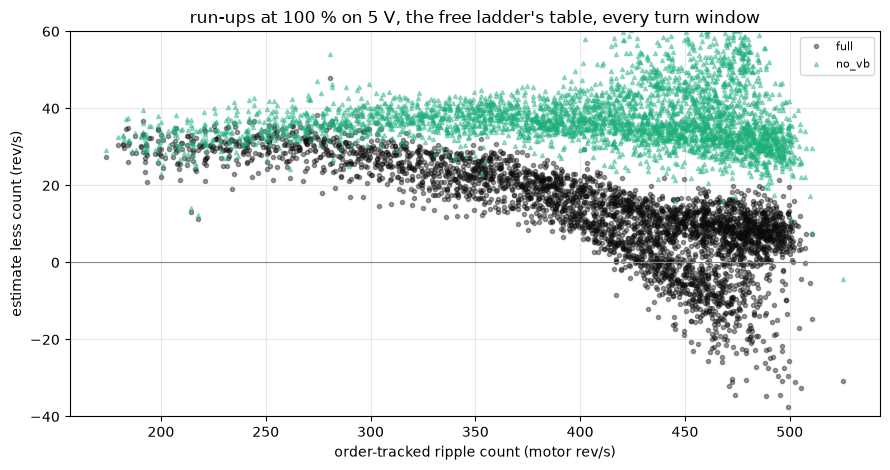

In [62]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for v, col, mk in (("full", INK, "o"), ("no_vb", GREEN, "^")):
    ax.plot(OK["truth"], OK[f"w_{v}"] - OK["truth"], mk, ms=3, alpha=0.4,
            color=col, label=v, ls="none")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylim(-40, 60)
ax.legend(fontsize=8)
figures.label(ax, x="order-tracked ripple count (motor rev/s)",
              y="estimate less count (rev/s)",
              title="run-ups at 100 % on 5 V, the free ladder's table, every "
                    "turn window")
figures.finish(fig)

What you are looking at. Every turn window's estimate less the order count, with the full estimate and without the brush table. The full estimate sits +26.43 to +29.51 rev/s high from 160 to 350 rev/s and comes down toward zero at the top, where the current has fallen toward the free value.

In [63]:
u_, c_ = u_of(FIT, "full")              # the ladder, k_d in
FIT["i_w"] = c_["i_w"]
HOLDS = HT.copy()                       # the turning holds, tach truth
u_, c_ = u_of(HOLDS, "full")
HOLDS["x_mv"] = (u_ - K["ke"] * HOLDS["truth"]) * 1e3
HOLDS["i_w"] = c_["i_w"]
OK["x_kd_mv"] = (OK["u"] - K["v0"] - r_of_t(OK["ntc_c"].to_numpy())
                 * OK["i_aw"] - K["l_h"] * OK["didt"] - K["k_d"] * OK["rate"]
                 - K["ke"] * OK["truth"]) * 1e3
OK["i_w"] = OK["i_aw"]
rm = rung_means(FIT, FIT["x_mv"].to_numpy())
im = rung_means(FIT, FIT["i_w"].to_numpy() * 1e3)
parts = []
for d in (1, -1):               # the run-ups less the ladder, same speed
    r_ = rm[rm["dir"] == d].sort_values("rev_s")
    i_ = im[im["dir"] == d].sort_values("rev_s")
    g = OK[(OK["dir"] == d) & (OK["truth"] >= r_["rev_s"].min())
           & (OK["truth"] <= r_["rev_s"].max())]
    parts.append(pd.DataFrame({
        "dir": d, "rev_s": g["truth"].to_numpy(),
        "sitting": g["sitting"].to_numpy(),
        "dx_mv": g["x_kd_mv"].to_numpy()
        - np.interp(g["truth"], r_["rev_s"], r_["x_mv"]),
        "di_ma": g["i_w"].to_numpy() * 1e3
        - np.interp(g["truth"], i_["rev_s"], i_["x_mv"])}))
CON = pd.concat(parts, ignore_index=True)
CON["band"] = band_of(CON["rev_s"])

In [64]:
def r_b_of(g):
    """(r_b ohm through the origin, its se, the rms about it)."""
    rb = np.sum(g["dx_mv"] * g["di_ma"]) / np.sum(g["di_ma"] ** 2)
    res = g["dx_mv"] - rb * g["di_ma"]
    se = np.sqrt(np.sum(res ** 2) / (len(g) - 1) / np.sum(g["di_ma"] ** 2))
    return float(rb), float(se), float(np.sqrt((res ** 2).mean()))


RB_BY = {}
print("the run-up windows' X less the ladder's at the same speed and "
      "direction, over the current difference")
for what in ("dir", "band", "sitting"):
    for key, g in CON.groupby(what):
        RB_BY[(what, key)] = r_b_of(g)
        rb, se, rms = RB_BY[(what, key)]
        print(f"  {what} {key}: r_b {rb:.3f} +/- {se:.3f} ohm; dX "
              f"{g['dx_mv'].mean():+.0f} mV at di {g['di_ma'].mean():+.0f} "
              f"mA, rms {rms:.0f} mV, n {len(g)}")
R_B, R_B_SE, _ = r_b_of(CON)
RB_ICPT = {}
for d, g in CON.groupby("dir"):
    A = np.column_stack([np.ones(len(g)), g["di_ma"]])
    beta, se, _ = fit_ls(A, g["dx_mv"].to_numpy())
    RB_ICPT[d] = (beta, se)
    print(f"  dir {d:+d} with an intercept: {beta[0]:+.0f} +/- {se[0]:.0f} "
          f"mV + {beta[1]:.3f} +/- {se[1]:.3f} ohm x di")
print(f"r_b pooled {R_B:.3f} +/- {R_B_SE:.3f} ohm; the steps result's "
      f"small-signal R {val(STP, 'r_step_a_ohm'):.2f} and take-back R "
      f"{val(STP, 'r_takeback_ohm'):.2f} less R_C: "
      f"{val(STP, 'r_step_a_ohm') - K['r_c']:.2f} and "
      f"{val(STP, 'r_takeback_ohm') - K['r_c']:.2f} ohm")

the run-up windows' X less the ladder's at the same speed and direction, over the current difference
  dir -1: r_b 0.567 +/- 0.005 ohm; dX +166 mV at di +256 mA, rms 53 mV, n 1090
  dir 1: r_b 0.524 +/- 0.007 ohm; dX +157 mV at di +253 mA, rms 68 mV, n 1020
  band 160-250: r_b 0.405 +/- 0.005 ohm; dX +224 mV at di +548 mA, rms 35 mV, n 183
  band 250-350: r_b 0.551 +/- 0.004 ohm; dX +211 mV at di +381 mA, rms 34 mV, n 583
  band 350-450: r_b 0.717 +/- 0.009 ohm; dX +136 mV at di +167 mA, rms 60 mV, n 1280
  band 450-600: r_b 1.860 +/- 0.115 ohm; dX +62 mV at di +30 mA, rms 29 mV, n 64
  sitting 1: r_b 0.573 +/- 0.008 ohm; dX +170 mV at di +256 mA, rms 62 mV, n 721
  sitting 6: r_b 0.543 +/- 0.008 ohm; dX +161 mV at di +255 mA, rms 61 mV, n 695
  sitting 7: r_b 0.522 +/- 0.008 ohm; dX +154 mV at di +252 mA, rms 61 mV, n 694
  dir -1 with an intercept: +84 +/- 2 mV + 0.321 +/- 0.007 ohm x di
  dir +1 with an intercept: +93 +/- 3 mV + 0.255 +/- 0.010 ohm x di
r_b pooled 0.546 +/- 0.005 oh

In [65]:
J = pd.concat([FIT[["truth", "dir", "x_mv", "i_w"]].assign(src="ladder"),
               HOLDS[["truth", "dir", "x_mv", "i_w"]].assign(src="holds"),
               OK[OK["truth"] < 450][["truth", "dir", "x_kd_mv", "i_w"]]
               .rename(columns={"x_kd_mv": "x_mv"}).assign(src="run-up")],
              ignore_index=True)
A = np.column_stack([np.ones(len(J)), (J["dir"] == 1).astype(float),
                     J["truth"], J["i_w"] * 1e3])
# the run-ups' 3000 windows weighted as about 100 spins
wts = np.where(J["src"] == "run-up", 1 / np.sqrt(30.0), 1.0)
JB, _, res = fit_ls(A, J["x_mv"].to_numpy(), wts)
print(f"joint line X = {JB[0]:+.0f} + {JB[1]:+.0f} [dir +1] + {JB[2]:+.3f} "
      f"w + {JB[3]:.3f} ohm x i (mV); rms " + ", ".join(
          f"{s} {np.sqrt((res[J['src'] == s] ** 2).mean()):.0f}"
          for s in ("ladder", "holds", "run-up")) + " mV")

joint line X = -79 + +9 [dir +1] + +0.326 w + 0.463 ohm x i (mV); rms ladder 31, holds 23, run-up 55 mV


In [66]:
def ladder_cv(variant, r_b):
    """The ladder held out by repeat with r_b in the volts balance."""
    parts = []
    for rep in sorted(FIT["repeat"].unique()):
        train = FIT[FIT["repeat"] != rep]
        test = FIT[FIT["repeat"] == rep].copy()
        tab, _ = fit_table(train, variant, r_b)
        test["w_hat"] = predict(test, variant, tab, r_b)
        parts.append(test)
    return pd.concat(parts, ignore_index=True)


def runup_pred(table, r_b):
    uu = (OK["u"] - K["v0"] - (r_of_t(OK["ntc_c"].to_numpy()) + r_b)
          * OK["i_aw"] - K["l_h"] * OK["didt"] - K["k_d"] * OK["rate"])
    return solve_w(uu.to_numpy(), OK["dir"].to_numpy(), table)


RB_SCORES, RB_TABLES = {}, {}
for lab, variant, r_b in (("full", "full", 0.0), ("full + r_b", "full", R_B),
                          ("signed", "signed", 0.0),
                          ("signed + r_b", "signed", R_B)):
    tab, _ = fit_table(FIT, variant, r_b)
    held = ladder_cv(variant, r_b).assign(src="ladder")
    hh = HOLDS.assign(w_hat=predict(HOLDS, variant, tab, r_b), src="holds")
    ww = OK.assign(w_hat=runup_pred(tab, r_b), src="run-up")
    rr = REFS.assign(w_hat=predict(REFS, variant, tab, r_b), src="refs",
                     band="ref 5 V 30 %")
    for f in (held, hh):
        f["band"] = band_of(f["truth"])
    allsets = pd.concat([held, hh, ww, rr], ignore_index=True)
    RB_SCORES[lab] = by_band(score(allsets, ["w_hat"], by=("src", "band")),
                             "src")
    RB_TABLES[lab] = tab
TABLE_RB = RB_TABLES["full + r_b"]
TABLE_RB_S = RB_TABLES["signed + r_b"]

In [67]:
tab = RB_SCORES["full"][["src", "band", "n", "rev_s"]].copy()
for lab, S in RB_SCORES.items():
    tab["mean " + lab] = S["w_hat_mean"].round(2)
for lab, S in RB_SCORES.items():
    tab["rms " + lab] = S["w_hat_rms"].round(2)
print("mean and rms error (rev/s) by set and band: the table alone and with "
      "a constant r_b in the volts balance, each table refit under it")
print(tab.to_string(index=False))
print("\nV_b with r_b in (mV):")
print(pd.DataFrame({"rev_s": KNOTS, "+1": TABLE_RB[1].round(1),
                    "-1": TABLE_RB[-1].round(1)}).to_string(index=False))

mean and rms error (rev/s) by set and band: the table alone and with a constant r_b in the volts balance, each table refit under it
   src         band    n      rev_s  mean full  mean full + r_b  mean signed  mean signed + r_b  rms full  rms full + r_b  rms signed  rms signed + r_b
 holds         0-30   18  23.425233      -3.78            -6.71        -0.90               1.75      4.24            6.96        2.19              2.68
 holds       30-100   57  35.564698      -3.54            -6.71        -0.57               1.94      3.88            6.91        1.74              2.69
 holds      160-250   24 210.382831       0.98            -4.82         1.11               1.62      1.15            4.90        1.26              1.74
 holds      250-350    2 253.576392      -0.41            -6.43        -0.41              -0.01      0.42            6.43        0.42              0.10
ladder       30-100   13  94.003990      -2.78            -8.22        -0.27              -0.32      2.89   

In [68]:
RB_FORMS = {"w_full_rb": ("u_full_rb", "rb"), "w_signed_rb": ("u_full_rb",
                                                             "rb_signed")}
RB_SET = {"rb": TABLE_RB, "rb_signed": TABLE_RB_S}
for e in SEG_EST:               # the clips' rows with r_b in the balance
    e["u_full_rb"] = e["v_c"] - K["v0"] - (e["r_t"] + R_B) * e["i_w"]
rb_cols = {c: [] for c in RB_FORMS}
for _, w in WIN.iterrows():
    e = SEG_EST[int(w["seg_i"])]
    m = (e["ta"] >= w["t0"]) & (e["ta"] < w["t0"] + w["w_ms"] / 1e3)
    out = window_estimates(e, m, int(w["dir"]), RB_FORMS, RB_SET)
    for c_ in RB_FORMS:
        rb_cols[c_].append(out[c_])
for c_, v_ in rb_cols.items():
    WIN[c_] = v_
W100 = W100.join(WIN[list(RB_FORMS)])   # the same windows, by index
STEADY = STEADY.join(WIN[list(RB_FORMS)])
S_CLIP_RB = by_band(score(STEADY, ["w_full_rb", "w_signed_rb"]))
print("the camera's 100 ms windows with r_b in the balance, against the tag")
print(fmt(S_CLIP_RB, ["w_full_rb", "w_signed_rb"], pct=False))

the camera's 100 ms windows with r_b in the balance, against the tag
  band   n  rev_s           w_full_rb         w_signed_rb
  0-30 362   17.4 -5.83+/-0.10 / 6.14 +2.80+/-0.10 / 3.43
30-100 152   53.2 -7.33+/-0.20 / 7.72 +0.90+/-0.22 / 2.79


### The current term

The free ladder ties the current to the speed, and the run-ups pass the same speeds at several times the current. At matched speed and direction, the run-up windows' X less the ladder's X over the current difference is a resistance through the origin of r_b 0.546 +/- 0.005 ohm, 0.567 in -1 and 0.524 in +1, and 0.573, 0.543 and 0.522 in sittings 1, 6 and 7. It is not one resistance. By band it runs 0.405 at 160-250 rev/s, 0.551 at 250-350 and 0.717 at 350-450, and with an intercept the line is +84 +/- 2 mV + 0.321 ohm in -1 and +93 +/- 3 mV + 0.255 ohm in +1. The steps result's small-signal R less R_C, 1.18 ohm, and its take-back R less R_C, 0.91 ohm, are larger again.

Carried as a constant in the volts balance, each table refit under it, r_b over-corrects every set it was not read from. The free ladder reads -8.22 to -3.64 rev/s under 350 rev/s, the refs -6.77, the holds -6.71 to -4.82 under 250 rev/s, and the clips -5.83 +/- 0.10 and -7.33 +/- 0.20. The run-ups move to -16.69 at 160-250 rev/s and -3.07 to +4.88 above. A speed table plus a constant r_b does not fit these sets.

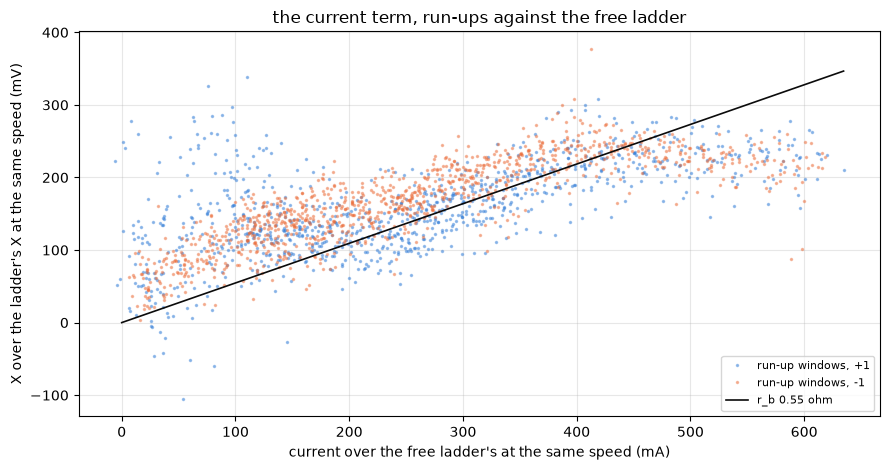

In [69]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for d, col in ((1, BLUE), (-1, ORANGE)):
    g = CON[CON["dir"] == d]
    ax.plot(g["di_ma"], g["dx_mv"], ".", ms=3, alpha=0.4, color=col,
            label=f"run-up windows, {d:+d}")
x = np.linspace(0, CON["di_ma"].max(), 10)
ax.plot(x, R_B * x, "-", color=INK, lw=1.2, label=f"r_b {R_B:.2f} ohm")
ax.legend(fontsize=8)
figures.label(ax, x="current over the free ladder's at the same speed (mA)",
              y="X over the ladder's X at the same speed (mV)",
              title="the current term, run-ups against the free ladder")
figures.finish(fig)

What you are looking at. Each run-up window's X over the ladder's X at the same speed and direction, against its current over the ladder's, with the line through the origin. The points bend off the line at both ends, the lever changing with the band.

### The lift

The load sitting's lifts drive a fixed duty from the arm's bottom, so the current at a given speed is set by the arm's torque and not by the free drag. No camera watched the arm, so the truth is the pot through the table over 100 ms windows from 200 ms into the held duty. The awake zero is each coast's tail.

In [70]:
LIFT_DIR = PAIR_DIR / "load" / "lift-1"
LIFT_WMS = 100                          # ms, a lift window
AT_REST_COUNTS = 4                      # counts, a coast tail at rest


def lift_window(s, half, v_on, i_over, rail, ntc, awake, d):
    """The forms over one lift window, the rows' per-row solve averaged."""
    rate = float(tel.dropout_rows(i_over[s]).mean() * FS)
    c = construct(half[s], v_on[s], i_over[s], rail, zero_mode="awake",
                  awake_counts=awake)
    u = c["v_c"] - K["v0"] - r_of_t(ntc) * c["i_w"] - K["k_d"] * rate
    u_rb = u - R_B * c["i_w"]
    dd = np.full(len(u), d)
    s1 = construct(half[s], v_on[s], i_over[s], rail, zero_mode="stage1")
    return {"w_full": float(solve_w(u, dd, TABLE).mean()),
            "w_signed": float(solve_w(u, dd, TABLE_SIGNED).mean()),
            "w_full_rb": float(solve_w(u_rb, dd, TABLE_RB).mean()),
            "w_signed_rb": float(solve_w(u_rb, dd, TABLE_RB_S).mean()),
            "w_no_vb": float((u / K["ke"]).mean()),
            "w_as_read": float(((s1["v_a"] - K["r_locked"] * s1["i"])
                                / K["ke"]).mean()),
            "i_w_ma": float(c["i_w"].mean() * 1e3),
            "v_on": float(v_on[s].mean()), "rate": rate}

In [71]:
def lift_cycle(df, info, rail, ntc):
    """[rows]: the 100 ms windows of one lift's held duty, from 200 ms
    in, against the pot through the table (no camera on the arm)."""
    zero_i, _ = tel.rest_zeros(df)
    out = []
    for d, sp, co in coast.pairs(df):
        tail = co.iloc[-TAIL_ROWS:]
        awake = float(tail["current_raw"].mean() - zero_i)
        at_rest = float(tail["pos"].max() - tail["pos"].min()) <= AT_REST_COUNTS
        g = sp.iloc[tel.drive_start(sp):]
        half = g["duty_counts"].abs().to_numpy(float)
        held = half == np.median(half[len(half) // 2:])
        g, half = g[held], half[held]
        taps = ((g["vmotor_a"] - g["vmotor_b"]) * d).to_numpy(float)
        v_on = SC.volts(taps, TAP_OFFSET)
        i_over = g["current_raw"].to_numpy(float) - zero_i
        valid = g["window_valid"].to_numpy() == 1
        pdeg = pot_deg(boxcar(g["pos"].to_numpy(float), POT_BOX_ROWS))
        t = np.arange(len(g)) / FS
        n = int(LIFT_WMS * FS / 1e3)
        for a in range(2 * n, len(g) - n, n // 2):  # the lash, spin-up out
            s = slice(a, a + n)
            if valid[s].mean() < 0.99 or np.isfinite(pdeg[s]).sum() < 0.9 * n:
                continue
            ok = np.isfinite(pdeg[s])
            pot = np.polyfit(t[s][ok], pdeg[s][ok], 1)[0] / DEG_S_PER_REV_S * d
            rec = {"k": int(info["k"]), "side": int(info["side"]),
                   "duty_pct": float(info["duty_pct"]), "dir": d,
                   "repeat": int(info["repeat"]), "t_ms": a / FS * 1e3,
                   "pot": pot, "angle_deg": float(np.nanmean(pdeg[s])),
                   "awake_at_rest": at_rest, "rail_v": rail}
            rec.update(lift_window(s, half, v_on, i_over, rail, ntc, awake, d))
            out.append(rec)
    return out

In [72]:
PR_LOAD = probes("servo-load-1.csv")
LIFT_CY = pd.read_csv(LIFT_DIR / "cycles.csv")
rows = []
for _, info in LIFT_CY.iterrows():
    df, meta, board = load(LIFT_DIR / info["folder"])
    rail, ntc = rail_and_ntc(PR_LOAD.get(label("load", "lift-1",
                                               info["folder"])), board)
    if not np.isfinite(rail):
        rail = float(info["vsys_read"])
    rows += lift_cycle(df, info, rail, ntc)
LIFT = pd.DataFrame(rows)
LIFT["truth"] = LIFT["pot"]             # the pot through the table
LIFT["band"] = band_of(LIFT["truth"])
LIFT_COASTS = LIFT.drop_duplicates(["k", "dir"])
print(f"{len(LIFT)} windows of {LIFT_WMS} ms over {len(LIFT_CY)} lifts; "
      f"awake zero read at rest in {int(LIFT_COASTS['awake_at_rest'].sum())}"
      f" of {len(LIFT_COASTS)} coasts; current {LIFT['i_w_ma'].min():.0f} to "
      f"{LIFT['i_w_ma'].max():.0f} mA at {LIFT['truth'].min():.0f} to "
      f"{LIFT['truth'].max():.0f} rev/s; duties "
      f"{', '.join(f'{x:.0f}' for x in sorted(LIFT['duty_pct'].unique()))} %")

104 windows of 100 ms over 12 lifts; awake zero read at rest in 1 of 12 coasts; current 100 to 343 mA at -1 to 110 rev/s; duties 20, 30, 40 %


In [73]:
LCOLS = ["w_full", "w_signed", "w_full_rb", "w_signed_rb", "w_no_vb",
         "w_as_read"]
S_LIFT = by_band(score(LIFT, LCOLS))
print("lift windows against the pot, by band")
print(fmt(S_LIFT, ["w_full", "w_signed", "w_full_rb"], pct=False))
print("\nerror against the winding current, every window: slope rev/s per "
      "100 mA (speed in the fit)")
LIFT_SLOPE = {}
for c_ in LCOLS:
    e = (LIFT[c_] - LIFT["truth"]).to_numpy()
    A = np.column_stack([np.ones(len(LIFT)), LIFT["i_w_ma"] / 100,
                         LIFT["truth"]])
    beta, se, res = fit_ls(A, e)
    LIFT_SLOPE[c_] = (beta[1], se[1])
    print(f"  {c_:12s}: {beta[1]:+.2f} +/- {se[1]:.2f}, intercept "
          f"{beta[0]:+.1f}, rms {np.sqrt((res ** 2).mean()):.2f}")
# the current term's size at low speed that zeroes the speed table's slope
r_low = LIFT_SLOPE["w_full"][0] / 100 * K["ke"] * 1e3
print(f"the full form's slope as a resistance: {r_low:.2f} +/- "
      f"{LIFT_SLOPE['w_full'][1] / 100 * K['ke'] * 1e3:.2f} ohm")

lift windows against the pot, by band
   band  n  rev_s              w_full            w_signed             w_full_rb
   0-30 60    8.3 -0.00+/-0.26 / 1.99 +2.95+/-0.27 / 3.62 -15.94+/-0.41 / 16.25
 30-100 43   55.6 +2.51+/-0.74 / 5.40 +5.18+/-0.73 / 7.01 -14.18+/-0.92 / 15.39
100-160  1  109.6  +1.71+/-nan / 1.71  +3.50+/-nan / 3.50  -15.88+/-nan / 15.88

error against the winding current, every window: slope rev/s per 100 mA (speed in the fit)
  w_full      : +1.53 +/- 0.59, intercept -3.8, rms 3.16
  w_signed    : +1.52 +/- 0.60, intercept -0.7, rms 3.22
  w_full_rb   : -5.97 +/- 0.59, intercept -3.8, rms 3.16
  w_signed_rb : -5.92 +/- 0.62, intercept +4.9, rms 3.36
  w_no_vb     : +1.53 +/- 0.59, intercept -3.8, rms 3.16
  w_as_read   : +4.13 +/- 0.58, intercept -3.0, rms 3.14
the full form's slope as a resistance: 0.11 +/- 0.04 ohm


The lifts at 20, 30 and 40 % give 104 windows over 12 lifts at 100 to 343 mA. The awake zero was read at rest in 1 of 12 coasts, the arm still swinging in the rest.

The full estimate reads -0.00 +/- 0.26 rev/s at 8.3 rev/s (rms 1.99) and +2.51 +/- 0.74 at 55.6 (rms 5.40). Its error grows with the current by +1.53 +/- 0.59 rev/s per 100 mA, which as a resistance is 0.11 +/- 0.04 ohm, a fifth of the run-ups' 0.546. With the constant r_b in, the slope turns to -5.97 +/- 0.59 and the bands read -15.94 and -14.18 rev/s. The run-ups and the lift ask for different current terms.

### The product form

A brush term proportional to speed times current, $V_b = c_0 + c_\mathrm{dir} + b\,\omega\,i_w$, with $c_\mathrm{dir}$ on +1 only, is fitted to X on the identification's own sets, the free ladder's spins and the run-up windows, the run-ups weighted as about 100 spins. With it the estimate is closed, $\omega = (u - c_0 - c_\mathrm{dir}) / (K_e + b\,i_w)$. The refs, the holds, the lift and the camera clips are held out.

In [74]:
def u_and_i(df, kind):
    """u = V_c - V0 - R(T) i_w - k_d rate (V) and i_w (A) per row of a set."""
    if kind == "spins":
        u, c = u_of(df, "full")
        return u, c["i_w"]
    if kind == "runup":
        u = (df["u"] - K["v0"] - r_of_t(df["ntc_c"].to_numpy()) * df["i_aw"]
             - K["l_h"] * df["didt"] - K["k_d"] * df["rate"]).to_numpy()
        return u, df["i_aw"].to_numpy()
    u = df["w_no_vb"].to_numpy() * K["ke"]  # the window's mean of u / Ke
    if kind == "clips":                 # the clips' carries no k_d term
        u = u - K["k_d"] * df["rate"].fillna(0).to_numpy()
    return u, df["i_w_ma"].to_numpy() / 1e3


PSETS = {"ladder": (HELD.copy(), "spins"),
         "run-up": (OK[OK["truth"] < 460].copy(), "runup"),
         "refs": (REFS.copy(), "spins"), "holds": (HOLDS.copy(), "spins"),
         "lift": (LIFT.copy(), "lift"), "clips": (STEADY.copy(), "clips")}
for name, (df, kind) in PSETS.items():
    u, i = u_and_i(df, kind)
    df["u_bal"], df["i_w"] = u, i
    df["x_mv"] = (u - K["ke"] * df["truth"]) * 1e3
    df["dirpos"] = (df["dir"] == 1).astype(float)

In [75]:
# the fit on the identification's sets: the ladder's spins and the run-up
# windows, the run-ups weighted as about 100 spins
F = pd.concat([PSETS["ladder"][0].assign(src="ladder"),
               PSETS["run-up"][0].assign(src="run-up")], ignore_index=True)
n_run = len(PSETS["run-up"][0])
wt = np.where(F["src"] == "run-up", 1 / np.sqrt(n_run / 100), 1.0)
A = np.column_stack([np.ones(len(F)), F["dirpos"], F["truth"] * F["i_w"]])
PB, PSE, res = fit_ls(A, F["x_mv"].to_numpy(), wt)
C0, CDIR, B = PB
P_RMS = {s: float(np.sqrt((res[F["src"] == s] ** 2).mean()))
         for s in ("ladder", "run-up")}
print(f"V_b = {C0:+.1f} +/- {PSE[0]:.1f} mV {CDIR:+.1f} +/- {PSE[1]:.1f} "
      f"[dir +1] + {B:.3f} +/- {PSE[2]:.3f} mV per (rev/s x A) x w x i; "
      f"rms ladder {P_RMS['ladder']:.0f} mV, run-up {P_RMS['run-up']:.0f}")
FF = FRIC["crawl_feed_forward_ma"]      # the free drag, the friction pair


def i_free_a(w):
    """The free shaft's current at w (rev/s), friction's pair, A."""
    return (val(FF, "coulomb") + val(FF, "per_rev_s") * w) / 1e3


print(f"dV/di {B * 100 / 1e3:.2f} ohm at 100 rev/s, {B * 400 / 1e3:.2f} at "
      f"400; at the free current ({i_free_a(100) * 1e3:.0f} and "
      f"{i_free_a(400) * 1e3:.0f} mA) {B * 100 * i_free_a(100):.0f} mV at "
      f"100 rev/s and {B * 400 * i_free_a(400):.0f} at 400")
lad = PSETS["ladder"][0]
A1 = np.column_stack([np.ones(len(lad)), lad["dirpos"],
                      lad["truth"] * lad["i_w"]])
B1, _, _ = fit_ls(A1, lad["x_mv"].to_numpy())
A2 = np.column_stack([np.ones(len(lad)), lad["dirpos"], lad["truth"]])
B2, _, _ = fit_ls(A2, lad["x_mv"].to_numpy())
print(f"the ladder alone: b {B1[2]:.3f} ({(B1[2] / B - 1) * 100:+.1f} % of "
      f"the joint), c0 {B1[0]:+.1f}; as a speed line c_w {B2[2]:+.3f} mV "
      f"per rev/s (c0 {B2[0]:+.1f})")

V_b = -35.6 +/- 1.7 mV +14.4 +/- 1.6 [dir +1] + 1.956 +/- 0.013 mV per (rev/s x A) x w x i; rms ladder 16 mV, run-up 52
dV/di 0.20 ohm at 100 rev/s, 0.78 at 400; at the free current (73 and 150 mA) 14 mV at 100 rev/s and 118 at 400
the ladder alone: b 1.905 (-2.6 % of the joint), c0 -35.3; as a speed line c_w +0.510 mV per rev/s (c0 -93.8)


In [76]:
print("X about the product form and about the best line in w and i "
      "separately (mV rms), per set")
for name in ("ladder", "holds", "lift", "run-up"):
    df = PSETS[name][0]
    pred = C0 + CDIR * df["dirpos"] + B * df["truth"] * df["i_w"]
    r_p = np.sqrt(((df["x_mv"] - pred) ** 2).mean())
    lin = (JB[0] + JB[1] * df["dirpos"] + JB[2] * df["truth"]
           + JB[3] * df["i_w"] * 1e3)
    r_l = np.sqrt(((df["x_mv"] - lin) ** 2).mean())
    print(f"  {name:7s}: product {r_p:.0f}, the separate line {r_l:.0f}")

X about the product form and about the best line in w and i separately (mV rms), per set
  ladder : product 16, the separate line 31
  holds  : product 12, the separate line 23
  lift   : product 32, the separate line 40
  run-up : product 52, the separate line 59


In [77]:
def w_product(u, i, d):
    """The closed form: w = (u - c0 - c_dir [+1]) / (Ke + b i)."""
    return (u - C0 * 1e-3 - CDIR * 1e-3 * (d == 1)) / (K["ke"] + B * 1e-3 * i)


TRUTH_SRC = {"ladder": "tach", "run-up": "count", "refs": "tach",
             "holds": "tach", "lift": "pot", "clips": "tag"}
parts = []
for name, (df, kind) in PSETS.items():
    df["w_product"] = w_product(df["u_bal"].to_numpy(), df["i_w"].to_numpy(),
                                df["dir"].to_numpy())
    if name in ("refs", "holds"):       # the speed table on the same u
        df["w_full"] = solve_w(df["u_bal"].to_numpy(), df["dir"].to_numpy(),
                               TABLE)
        df["w_signed"] = solve_w(df["u_bal"].to_numpy(),
                                 df["dir"].to_numpy(), TABLE_SIGNED)
    df["band"] = band_of(df["truth"])
    parts.append(df[["truth", "dir", "i_w", "band", "w_full", "w_signed",
                     "w_product"]].assign(src=name))
ALLP = pd.concat(parts, ignore_index=True)
PCOLS = ["w_full", "w_signed", "w_product"]
S_PROD = by_band(score(ALLP, PCOLS, by=("src", "band")), "src")
S_PROD["in_fit"] = S_PROD["src"].isin(["ladder", "run-up"])
print("every set by band: the speed table, the signed table and the "
      "product form (in the fit: ladder, run-up; the rest held out)")
print(fmt(S_PROD, PCOLS, keys=("src", "band", "in_fit"), pct=False))
L_ = PSETS["lift"][0]
e = (L_["w_product"] - L_["truth"]).to_numpy()
A = np.column_stack([np.ones(len(L_)), L_["i_w"] * 10, L_["truth"]])
beta, se, res = fit_ls(A, e)
LIFT_SLOPE["w_product"] = (beta[1], se[1])
print(f"\nlift under the product form: {beta[1]:+.2f} +/- {se[1]:.2f} rev/s "
      f"per 100 mA, intercept {beta[0]:+.1f}, rms "
      f"{np.sqrt((res ** 2).mean()):.2f}")

every set by band: the speed table, the signed table and the product form (in the fit: ladder, run-up; the rest held out)
   src    band  in_fit    n  rev_s                w_full              w_signed            w_product
 clips    0-30   False  362   17.4   -2.58+/-0.09 / 3.13   +0.38+/-0.10 / 1.89  +1.10+/-0.10 / 2.20
 clips  30-100   False  152   53.2   -3.59+/-0.20 / 4.32   -0.88+/-0.20 / 2.58  -0.41+/-0.21 / 2.61
 holds    0-30   False   18   23.4   -3.78+/-0.47 / 4.24   -0.90+/-0.48 / 2.19  +0.09+/-0.49 / 2.01
 holds  30-100   False   57   35.6   -3.54+/-0.21 / 3.88   -0.57+/-0.22 / 1.74  -0.10+/-0.24 / 1.78
 holds 160-250   False   24  210.4   +0.98+/-0.12 / 1.15   +1.11+/-0.13 / 1.26  +0.74+/-0.15 / 1.02
 holds 250-350   False    2  253.6   -0.41+/-0.07 / 0.42   -0.41+/-0.07 / 0.42  -0.81+/-0.16 / 0.82
ladder  30-100    True   13   94.0   -2.78+/-0.23 / 2.89   -0.27+/-0.29 / 1.05  -0.62+/-0.37 / 1.43
ladder 100-160    True   18  137.5   -1.47+/-0.15 / 1.60   -0.03+/-0.15 / 0.62

The fit gives c0 -35.6 +/- 1.7 mV, c_dir +14.4 +/- 1.6 mV and b 1.956 +/- 0.013 mV per (rev/s x A), rms 16 mV on the ladder and 52 on the run-ups. That is a dV/di of 0.20 ohm at 100 rev/s and 0.78 at 400. At the free current, 73 and 150 mA by the friction pair, it reads 14 mV at 100 rev/s and 118 at 400, the clipped table's size there. The ladder alone recovers b 1.905, -2.6 % of the joint value, so the one-pass identification reads it without run-ups. X about the product form leaves 16, 12, 32 and 52 mV rms on the ladder, the holds, the lift and the run-ups, against 31, 23, 40 and 59 about the joint line in w and i separately.

Scored, the product form reads -1.78 +/- 0.27, -1.94 +/- 0.15, +0.96 +/- 0.18 and +5.69 +/- 0.54 rev/s on the run-ups' bands (rms 4.00 to 10.25) and -0.41 to -0.68 on the ladder's bands, -1.21 at the top, both in the fit. Held out it reads +0.15 +/- 0.15 on the refs, +0.09, -0.10 and +0.74 on the holds, +1.10 +/- 0.10 and -0.41 +/- 0.21 on the clips (rms 2.20 and 2.61), and +3.22 +/- 0.21 and +2.83 +/- 0.62 on the lift. The lift's current slope goes to +0.36 +/- 0.53 rev/s per 100 mA.

The lift's offset of about +3 rev/s is the one held-out set the product form leaves open. Its truth is the pot over 100 ms at a spot, which carries the table's texture (section 7), and its awake zero came from coasts with the arm still swinging in all but 1 of 12, so it is a low to moderate grade (discrepancy 3).

Confidence. That the brush term depends on the current is high, the run-ups reading +26.43 +/- 0.20 to +29.51 +/- 0.28 rev/s under the speed table. That its form is speed times current is moderate. It rests on one servo and four sets, and stage 2's mg90-b held its speed table on its own run-ups, so whether the term belongs to this motor's brushes or to this stage's servo is open. A speed-only table holds at the free current only. Under current the product form fits this servo, and the matched-speed experiment at two currents decides the form (discrepancy 1).

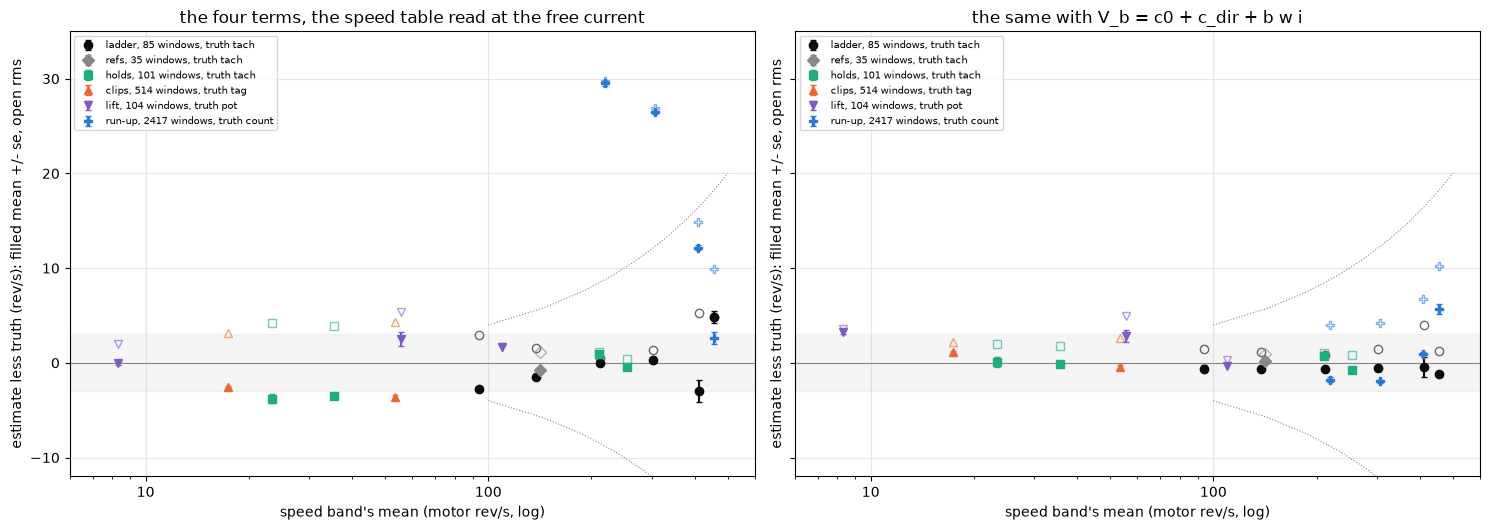

In [78]:
STYLE = {"ladder": (INK, "o"), "refs": (MUTED, "D"), "holds": (GREEN, "s"),
         "clips": (ORANGE, "^"), "lift": ("#7a5cc4", "v"),
         "run-up": (BLUE, "P")}
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
for ax, (col, title) in zip(axs, (
        ("w_full", "the four terms, the speed table read at the free current"),
        ("w_product", "the same with V_b = c0 + c_dir + b w i"))):
    for src, (c_, mk) in STYLE.items():
        g = S_PROD[S_PROD["src"] == src]
        ax.errorbar(g["rev_s"], g[f"{col}_mean"], yerr=g[f"{col}_se"],
                    fmt=mk, color=c_, ms=6, capsize=2,
                    label=f"{src}, {g['n'].sum()} windows, truth "
                          f"{TRUTH_SRC[src]}")
        ax.plot(g["rev_s"], g[f"{col}_rms"], ls="none", marker=mk,
                mfc="none", mec=c_, ms=6, alpha=0.6)
    ax.axhline(0, color=MUTED, lw=0.8)
    top = EXPECT_CRAWL[1]               # the README's crawl band, rev/s
    ax.axhspan(-top, top, color=MUTED, alpha=0.08)
    xs = np.linspace(100, 500, 10)
    for p in (-EXPECT_PCT[1], EXPECT_PCT[1]):   # its % band above 100
        ax.plot(xs, p / 100 * xs, ":", color=MUTED, lw=0.8)
    ax.set_xscale("log")
    ax.set_xlim(6, 600)
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
    ax.set_ylim(-12, 35)
    ax.legend(fontsize=7, loc="upper left")
    figures.label(ax, x="speed band's mean (motor rev/s, log)",
                  y="estimate less truth (rev/s): filled mean +/- se, "
                    "open rms", title=title)
figures.finish(fig)

What you are looking at. The central figure. Every set's error per speed band, filled the mean with its se and open the rms, on the left with the speed table read at the free current and on the right with the product form. The gray band is the README's 1 to 3 rev/s at a crawl and the dotted lines its 4 % above 100 rev/s.

On the left the run-ups sit +12.17 to +29.51 rev/s high under 450 rev/s, and every set at a crawl sits -2.58 to -3.78 rev/s low but the lift. On the right every set but the lift sits within 1.94 rev/s of zero under 450 rev/s, the run-ups included.

## 7. The pot as the velocity source

The pot through the table, differenced over a window W, against the tag over the same window, beside the EMF estimate averaged over the same window, on the held crawls, passes and steps. The pot's speed is read two ways, two points at the window's ends and a line through its rows. The product form is carried over every window by the same closed form.

In [79]:
# the product form over every window length, the same closed form
u_w = WIN["w_no_vb"].to_numpy() * K["ke"] - K["k_d"] * WIN["rate"].fillna(
    0).to_numpy()
WIN["w_product"] = w_product(u_w, WIN["i_w_ma"].to_numpy() / 1e3,
                             WIN["dir"].to_numpy())
Q2 = WIN[WIN["label"].isin(["crawl", "pass", "steps"])
         & (WIN["valid_share"] > 0.99)
         & (WIN["duty_pct"] >= CRAWL_DUTY_MIN)].copy()
Q2["truth"] = Q2["tag"]
Q2["band"] = band_of(Q2["truth"])
Q2_FORMS = ("pot_two", "pot_line", "w_full", "w_signed", "w_full_rb",
            "w_product")
rows = []
for (wms, band), g in Q2.groupby(["w_ms", "band"]):
    r = {"w_ms": wms, "band": band, "n": len(g), "rev_s": g["truth"].mean()}
    for col in Q2_FORMS:
        e = (g[col] - g["truth"]).dropna()
        r.update({col + "_rms": np.sqrt((e ** 2).mean()),
                  col + "_mean": e.mean(), col + "_sd": e.std(ddof=1)})
    rows.append(r)
Q2S = pd.DataFrame(rows).sort_values(
    ["band", "w_ms"], key=lambda s: s.map(ORDER) if s.name == "band"
    else s).reset_index(drop=True)
print("rms error against the tag (rev/s) by window and band")
print(Q2S[["w_ms", "band", "n", "rev_s"] + [f + "_rms" for f in Q2_FORMS]]
      .round(2).to_string(index=False))
print("\nmean error and sd (rev/s): the pot two-point, the EMF forms")
print(Q2S[["w_ms", "band", "pot_two_mean", "pot_two_sd", "w_full_mean",
           "w_full_sd", "w_signed_mean", "w_signed_sd", "w_product_mean"]]
      .round(2).to_string(index=False))

rms error against the tag (rev/s) by window and band
 w_ms    band   n  rev_s  pot_two_rms  pot_line_rms  w_full_rms  w_signed_rms  w_full_rb_rms  w_product_rms
   50    0-30 742  17.21         3.51          3.80        3.64          2.92           6.31           3.22
  100    0-30 362  17.41         2.03          2.20        3.13          1.89           6.14           2.20
  200    0-30 168  17.43         0.90          0.82        2.77          1.08           5.97           1.56
  300    0-30 101  17.04         0.76          0.53        2.71          1.04           5.95           1.54
  500    0-30  48  16.73         0.67          0.24        2.57          0.96           5.86           1.60
   50  30-100 340  52.47         4.91          5.19        5.84          4.34           8.80           4.20
  100  30-100 152  53.25         2.70          2.47        4.32          2.58           7.72           2.61
  200  30-100  62  55.71         1.09          0.91        3.40          1.43      

In [80]:
def crossover(g, pot, emf):
    """The window where the pot's rms falls under the EMF form's, by log
    interpolation; "< 50" or "> 500" when it never crosses."""
    g = g.sort_values("w_ms")
    diff = (g[pot + "_rms"] - g[emf + "_rms"]).to_numpy()
    w = g["w_ms"].to_numpy(float)
    if (diff <= 0).all():
        return f"< {w[0]:.0f}"
    if (diff > 0).all():
        return f"> {w[-1]:.0f}"
    j = int(np.flatnonzero(diff <= 0)[0])
    f = diff[j - 1] / (diff[j - 1] - diff[j])
    lw = np.log(w)
    return f"{np.exp(lw[j - 1] + f * (lw[j] - lw[j - 1])):.0f}"


CROSS = {band: {f"{emf} / {pot}": crossover(g, pot, emf)
                for emf in ("w_full", "w_signed", "w_full_rb", "w_product")
                for pot in ("pot_two", "pot_line")}
         for band, g in Q2S.groupby("band")}
print("the window (ms) where the pot's rms falls under the EMF form's")
print(pd.DataFrame(CROSS).to_string())
pt = Q2[Q2["w_ms"] == 100]
print(f"\npot two-point less tag over 100 ms: sd "
      f"{(pt['pot_two'] - pt['tag']).std():.2f} rev/s, mean "
      f"{(pt['pot_two'] - pt['tag']).mean():+.2f}; the table's fine "
      f"texture {val(POT, 'table_fine_rms_counts'):.1f} counts rms")

the window (ms) where the pot's rms falls under the EMF form's
                      0-30 100-160 30-100
w_full / pot_two      < 50    < 50   < 50
w_full / pot_line       55    < 50   < 50
w_signed / pot_two     134    < 50    119
w_signed / pot_line    146    < 50     92
w_full_rb / pot_two   < 50    < 50   < 50
w_full_rb / pot_line  < 50    < 50   < 50
w_product / pot_two     77    < 50    111
w_product / pot_line   100    < 50     92

pot two-point less tag over 100 ms: sd 2.25 rev/s, mean -0.10; the table's fine texture 6.0 counts rms


In [81]:
# the pot's floor as angle per window: rms x window, in motor rev
FLOOR = Q2S.assign(angle_rev=Q2S["pot_two_rms"] * Q2S["w_ms"] / 1e3)
print("the pot two-point's rms times the window, motor rev of angle")
print(FLOOR[["w_ms", "band", "pot_two_rms", "angle_rev"]].round(3)
      .to_string(index=False))
f100 = FLOOR[FLOOR["band"] == "0-30"]["angle_rev"]
POT_FLOOR_REV = float(f100.mean())
print(f"at the crawl over 50 to 500 ms {f100.min():.2f} to {f100.max():.2f}"
      f" rev, mean {POT_FLOOR_REV:.2f} = {POT_FLOOR_REV * 360 / GEAR:.2f} "
      f"horn deg = {POT_FLOOR_REV * 360 / GEAR * K['pot_scale']:.1f} counts")
RIP = POT["ripple_cycles_per_deg"]      # the crawl's ripple line, pot-table
print(f"the crawl's speed ripple line {RIP['lo']:.2f} to {RIP['hi']:.2f} "
      f"cycles per output degree (pot-table)")
print(f"tach against the tag, 100 ms: crawl "
      f"{S_CLIP['tach_mean'].iloc[0]:+.2f} +/- {S_CLIP['tach_se'].iloc[0]:.2f}"
      f", pass {S_CLIP['tach_mean'].iloc[1]:+.2f} +/- "
      f"{S_CLIP['tach_se'].iloc[1]:.2f} rev/s")

the pot two-point's rms times the window, motor rev of angle
 w_ms    band  pot_two_rms  angle_rev
   50    0-30        3.513      0.176
  100    0-30        2.029      0.203
  200    0-30        0.898      0.180
  300    0-30        0.758      0.227
  500    0-30        0.670      0.335
   50  30-100        4.907      0.245
  100  30-100        2.699      0.270
  200  30-100        1.090      0.218
  300  30-100        0.859      0.258
  500  30-100        0.425      0.212
   50 100-160       11.783      0.589
at the crawl over 50 to 500 ms 0.18 to 0.34 rev, mean 0.22 = 0.26 horn deg = 5.0 counts
the crawl's speed ripple line 0.14 to 0.17 cycles per output degree (pot-table)
tach against the tag, 100 ms: crawl +0.04 +/- 0.12, pass -0.87 +/- 0.20 rev/s


At the crawl, 17 rev/s, the pot's two-point speed reads 3.51, 2.03, 0.90, 0.76 and 0.67 rev/s rms over 50, 100, 200, 300 and 500 ms, and at 30-100 rev/s 4.91, 2.70, 1.09, 0.86 and 0.42. Its mean error stays within 0.26 rev/s at the crawl and 0.79 at 30-100, so the pot through the table carries no scale error against the tag. Its rms times the window stays near 0.2 motor rev, 0.18 to 0.34 rev at the crawl with a mean of 0.22, which is 0.26 horn deg or 5.0 counts, about the table's 6.0 counts rms of fine texture decorrelating over the window plus the converter's own noise. So the error falls about as 1/W. A line through the window gains little under 200 ms and more above it, 0.53 against 0.76 rev/s at 300 ms and 0.24 against 0.67 at 500.

The ladder's tach over the pot at a fixed spot, 0.9476 on its lowest rung and 0.9716 on the settled spins, is the same texture read at one place, since the tag and the tach agree. A 100 ms pot speed at a spot is graded by the tag, never the reverse (discrepancy 4).

The EMF over the same windows reads 3.64, 3.13, 2.77, 2.71 and 2.57 rev/s rms at the crawl with the clipped table, its -2.31 to -2.63 bias inside, and 2.92, 1.89, 1.08, 1.04 and 0.96 with the signed table. Its sd under the clipped table, 2.81, 1.78, 0.89, 0.82 and 0.69, sits under the pot's at 50 and 100 ms and beside it from 200 ms up. So the crossover where the pot's rms falls under the EMF's is under 50 ms against the clipped table, whose bias decides it. Against the signed table it is 134 ms by two points and 146 ms by the line at the crawl, and 119 and 92 ms at 30-100 rev/s. Against the product form it is 77 and 100 ms at the crawl and 111 and 92 ms at 30-100.

For a velocity loop the EMF carries the loop's bandwidth, windows of 50 to 100 ms at 1.89 to 2.92 rev/s rms at a crawl with the signed table. The pot over 200 ms and longer supplies the slow truth that pins the EMF's bias, which at zero current is a zero or V0 read and not the EMF's gain, since the EMF is never trimmed to the pot's speed. Under 200 ms the pot adds little. The crawl's own speed ripple, 0.366 of its mean, is locked to the angle at 0.14 to 0.17 cycles per output degree (pot-table), so both sources see it and a loop needs the notch the pot-table notebook named.

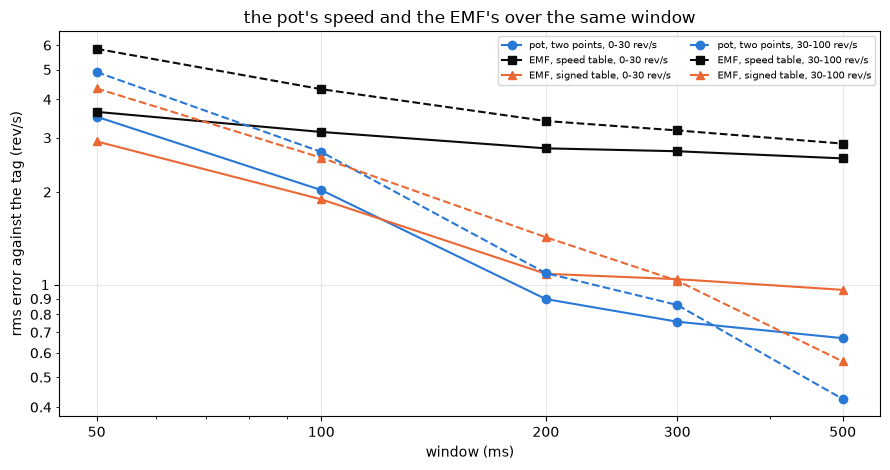

In [82]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for band, ls in (("0-30", "-"), ("30-100", "--")):
    g = Q2S[Q2S["band"] == band]
    for col, c_, mk, lab in (("pot_two", BLUE, "o", "pot, two points"),
                             ("w_full", INK, "s", "EMF, speed table"),
                             ("w_signed", ORANGE, "^", "EMF, signed table")):
        ax.plot(g["w_ms"], g[col + "_rms"], marker=mk, ls=ls, color=c_,
                label=f"{lab}, {band} rev/s")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(WINDOWS_MS, [str(w) for w in WINDOWS_MS])
ax.xaxis.set_minor_formatter(plt.NullFormatter())   # the windows only
for axis in (ax.yaxis,):                # plain numbers on the log axis
    axis.set_major_formatter(plt.FormatStrFormatter("%g"))
    axis.set_minor_formatter(plt.FormatStrFormatter("%g"))
ax.legend(fontsize=7, ncol=2)
figures.label(ax, x="window (ms)", y="rms error against the tag (rev/s)",
              title="the pot's speed and the EMF's over the same window")
figures.finish(fig)

What you are looking at. The rms error against the tag by window length, log on both axes, for the pot's two-point speed and the EMF with each table, solid at the crawl and dashed at 30-100 rev/s. The pot falls as 1/W and crosses the signed EMF between 92 and 146 ms, while the clipped EMF stays on its bias.

## 8. The position

The pot through the table against the tag, frame by frame, over the frames where the pot moves.

In [83]:
F3 = FR[np.isfinite(FR["pot_deg"]) & np.isfinite(FR["tag_deg"])].copy()
F3["resid"] = F3["pot_deg"] - F3["tag_deg"]   # the pot through the table
F3["bin"] = (F3["tag_deg"] // 10) * 10
MV = F3[F3["pot_speed"].abs() > MOVING_DEG_S]
POS_RMS = np.sqrt((MV["resid"] ** 2).mean())
print(f"frames moving over {MOVING_DEG_S} deg/s: rms {POS_RMS:.3f} deg "
      f"({POS_RMS * K['pot_scale']:.1f} "
      f"counts), mean {MV['resid'].mean():+.3f}, n {len(MV)}")
BY_KIND = MV.groupby(["kind", "dir"])["resid"].agg(["mean", "std", "size"])
print(BY_KIND.round(3).to_string())
BY_BIN = MV.groupby(["bin", "dir"])["resid"].agg(["mean", "std", "size"])
print(BY_BIN.unstack("dir").round(3).to_string())
po = MV[MV["block"] == "pass-open-9"]["resid"]
pc = MV[MV["block"] == "pass-close-9"]["resid"]
print(f"pass open {po.mean():+.3f} sd {po.std():.3f}; pass close "
      f"{pc.mean():+.3f} sd {pc.std():.3f} deg")

frames moving over 2.0 deg/s: rms 0.400 deg (7.6 counts), mean -0.013, n 8696
               mean    std  size
kind     dir                    
crawl    -1  -0.177  0.317  2955
          1   0.166  0.334  2898
pass     -1   0.253  0.201   264
          1  -0.764  0.293   261
reversal -1   0.314  0.446   668
          1  -0.280  0.366   695
steps    -1   0.203  0.174   474
          1  -0.104  0.163   481
         mean           std          size       
dir        -1      1     -1      1     -1      1
bin                                             
-170.0    NaN -0.534    NaN  0.340    NaN   30.0
-160.0 -0.148  0.060  0.167  0.379   17.0  444.0
-150.0 -0.108  0.118  0.203  0.287   78.0  910.0
-140.0 -0.062  0.038  0.203  0.396   78.0  369.0
-130.0  0.241  0.095  0.236  0.394   65.0  606.0
-120.0  0.211  0.032  0.435  0.437   58.0  665.0
-110.0  0.250  0.081  0.249  0.555  163.0  365.0
-100.0  0.168 -0.154  0.304  0.353  387.0  437.0
-90.0  -0.138 -0.260  0.448  0.363  405.0  212.0
-80.

In [84]:
# the load ladder's 3 s holds: two streamed 100 ms windows, start and end
rows = []
d_ = PAIR_DIR / "load" / "ladder-1"
for _, r in pd.read_csv(d_ / "ladder.csv").iterrows():
    df, meta, board = load(d_ / r["folder"])
    seg = pd.read_csv(d_ / r["folder"] / "segments.csv").set_index("seg")
    streamed = [s for s in seg.index if s > 0 and seg.loc[s, "streamed"] == 1]
    if len(streamed) < 2:
        continue
    first = df[df["seg"] == streamed[0]]["pos"].to_numpy(float)
    last = df[df["seg"] == streamed[-1]]["pos"].to_numpy(float)
    rows.append({"k": int(r["k"]), "side": int(r["side"]),
                 "duty_pct": float(r["duty_pct"]), "last_sd": last.std(),
                 "drift_counts": last.mean() - first.mean(),
                 "gap_s": seg.loc[streamed[-1], "t_start"]
                 - seg.loc[streamed[0], "t_start"], "range": np.ptp(last)})
LH = pd.DataFrame(rows)
STILL = LH[(LH["range"] <= 8) & (LH["duty_pct"] >= 6)]
print(f"{len(LH)} holds, {len(STILL)} still over their last window "
      f"(range <= 8 counts)")
print(STILL.groupby("side").agg(n=("k", "size"), sd=("last_sd", "mean"),
                                drift=("drift_counts", "mean"))
      .round(2).to_string())
print(f"pos sd within 100 ms {STILL['last_sd'].mean():.2f} counts "
      f"({STILL['last_sd'].min():.2f} to {STILL['last_sd'].max():.2f}); "
      f"start to end over {STILL['gap_s'].mean():.1f} s: |max| "
      f"{STILL['drift_counts'].abs().max():.0f} counts")

45 holds, 25 still over their last window (range <= 8 counts)
       n    sd   drift
side                  
-1    20  0.76 -723.40
 1     5  1.32  638.24
pos sd within 100 ms 0.87 counts (0.52 to 1.52); start to end over 3.7 s: |max| 1824 counts


In [85]:
COUPLE = LOAD["pot_torque_coupling_deg_per_50ma"]
PUSH_DEG = val(POT, "pot_force_excess_deg") / 2   # each way
print(f"pot under a push (pot-table): {PUSH_DEG:.2f} deg each way, "
      f"relaxing {val(POT, 'pot_force_relax_deg'):.2f} while held")
print(f"pot against a held torque (load): {COUPLE['value']:+.2f} +/- "
      f"{(COUPLE['hi'] - COUPLE['lo']) / 2:.2f} deg per 50 mA; the largest "
      f"motion under a 5 % step {val(LOAD, 'steps_motion_deg_max'):.2f} deg")
print(f"lash: play {POT['lash_play_deg']['lo']:.2f} to "
      f"{POT['lash_play_deg']['hi']:.2f} deg, by hand "
      f"{val(POT, 'lash_hand_deg'):.2f}; code 2047 "
      f"{val(POT, 'adc_code_2047_deg'):.2f} deg; the other wide codes "
      + ", ".join(f"{k} {v['value']:.2f}" for k, v in
                  POT["adc_wide_code_deg"].items() if k != "2047") + " deg")

pot under a push (pot-table): 0.51 deg each way, relaxing 0.31 while held
pot against a held torque (load): -0.11 +/- 0.08 deg per 50 mA; the largest motion under a 5 % step 0.33 deg
lash: play 0.39 to 1.12 deg, by hand 1.24; code 2047 0.71 deg; the other wide codes 511 0.20, 1023 0.62, 1279 0.20, 2559 0.32 deg


Over the travel the pot through the table less the tag reads 0.400 deg rms, 7.6 counts, mean -0.013 deg, over 8696 frames. The table was fitted on this sitting's clips, so this is in-sample, the texture the table leaves between its knots plus the tag's 0.16 deg grade.

By direction at a crawl the pot reads +0.166 deg ahead of the horn in +1 and -0.177 in -1, sd 0.334 and 0.317 over 2898 and 2955 frames. That is a direction-signed offset of about 0.17 deg, likely the pot on the gear side of the play leading the horn, inside the lash's play of 0.39 to 1.12 deg (1.24 by hand). The passes read -0.764 deg in +1 and +0.253 in -1, which is the per-group lead's alignment at speed and not a pot number, so the position grade at speed waits on the stamps (discrepancy 8). The table's level reads -0.277 deg at the opening pass and -0.229 at the closing, sd 0.709 and 0.376, not a finding.

The hold. The load ladder's holds stream a 100 ms window at their start and another at their end, 3.7 s apart. Over the end window, with the arm still (a range of 8 counts at most), the pot sits within 0.87 counts sd (0.52 to 1.52) over 25 holds of sitting 1. Between the two windows the arm swings to its rest, up to 1824 counts, and the hold itself is not streamed, so the drift of a hold under torque over seconds is not in the data. The force term stays a bound. The pot reads 0.51 deg past the horn each way under a hand push and relaxes 0.31 while it is held (pot-table), and reads -0.11 +/- 0.08 deg per 50 mA against a held torque, the largest motion under a 5 % step 0.33 deg (load).

So a closed-loop hold reads its position to about 0.87 counts of noise, +/-0.17 deg of direction-signed lash offset, 0.400 deg rms of table texture, 0.71 deg at code 2047, and up to 0.51 deg of force term under a side load the board does not see.

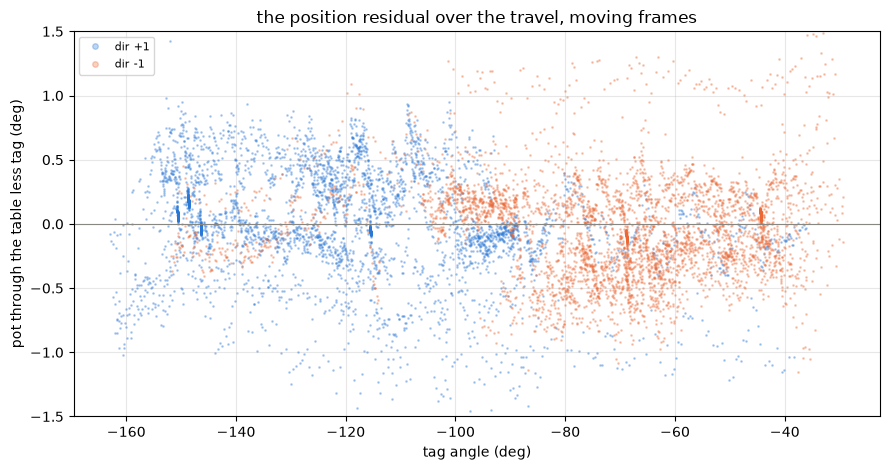

In [86]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for d, c_ in ((1, BLUE), (-1, ORANGE)):
    g = MV[MV["dir"] == d]
    ax.plot(g["tag_deg"], g["resid"], ".", ms=2, alpha=0.3, color=c_,
            label=f"dir {d:+d}")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylim(-1.5, 1.5)
ax.legend(fontsize=8, markerscale=4)
figures.label(ax, x="tag angle (deg)",
              y="pot through the table less tag (deg)",
              title="the position residual over the travel, moving frames")
figures.finish(fig)

What you are looking at. Each moving frame's pot through the table less the tag, against the tag angle, by direction. The texture the table leaves spreads the frames by about 0.400 deg rms over the travel. The two directions cover mostly different parts of the travel in this sitting, so the direction-signed offset reads from the crawls' means printed above and not from this picture.

## 9. The dropout flag

A dropout is a crest sample under a quarter of its window's mean, the count the board itself keeps. Its rate per second over a window is the flag's input.

In [87]:
CAP = SP[SP["tach_ok"]]
DROP_RUNGS = CAP.groupby(["set", "volts_set", "duty_pct", "dir"]).agg(
    n=("k", "size"), rev_s=("tach_rev_s", "mean"),
    rate=("dropouts_per_s", "mean"), rate_max=("dropouts_per_s", "max"),
    rows=("dropout_rows", "sum")).reset_index()
print("dropout rate per rung and direction (gated spins), per second over "
      "the spin window, the rungs with any")
print(DROP_RUNGS[DROP_RUNGS["rate_max"] > 0].round(1).to_string(index=False))
refs_ = CAP[CAP["set"].str.startswith("ref")]
quiet = CAP[CAP["tach_rev_s"] < 420]
print(f"spins with any dropout: {int((CAP['dropouts_per_s'] > 0).sum())} of "
      f"{len(CAP)}; under 420 rev/s {int((quiet['dropouts_per_s'] > 0).sum())}"
      f" of {len(quiet)}; reference rungs "
      f"{int((refs_['dropouts_per_s'] > 0).sum())} of {len(refs_)}")

dropout rate per rung and direction (gated spins), per second over the spin window, the rungs with any
      set  volts_set  duty_pct  dir  n  rev_s  rate  rate_max  rows
capture-1        7.4      60.0    1  3  425.8  28.2      56.3     3
   rail-1        7.4      67.0    1  3  439.4  50.5      75.9     4
spins with any dropout: 5 of 120; under 420 rev/s 0 of 108; reference rungs 0 of 35


In [88]:
RUNS["drive_s"] = RUNS["rows"] / FS
SIT = RUNS.groupby(["sitting", "dir"]).agg(
    rows=("dropouts", "sum"), n=("k", "size"), s=("drive_s", "sum"))
SIT["rate"] = SIT["rows"] / SIT["s"]
SIT["se"] = np.sqrt(SIT["rows"]) / SIT["s"]     # Poisson
print("run-up dropout rate by sitting and direction, rows per second of "
      "drive, Poisson se")
print(SIT.round(1).to_string())
REF_RATE = SIT.loc[(1, 1)]              # sitting 1, +1: the reference
s6 = SIT.loc[(6, 1)]
rise = (s6["rate"] - REF_RATE["rate"]) / np.hypot(s6["se"], REF_RATE["se"])
print(f"reference (sitting 1, +1): {REF_RATE['rate']:.0f} +/- "
      f"{REF_RATE['se']:.0f} per s over {int(REF_RATE['n'])} run-ups; the "
      f"rise to sitting 6 {rise:.1f} sigma")

run-up dropout rate by sitting and direction, rows per second of drive, Poisson se
             rows  n    s  rate    se
sitting dir                          
1       -1      2  6  0.3   6.4   4.6
         1      8  6  0.3  25.8   9.1
6       -1      0  6  0.3   0.0   0.0
         1     22  6  0.3  70.9  15.1
7       -1      2  6  0.3   6.5   4.6
         1     18  6  0.3  57.9  13.7
reference (sitting 1, +1): 26 +/- 9 per s over 6 run-ups; the rise to sitting 6 2.6 sigma


In [89]:
print("the table's error against the rate over 350 rev/s, speed in the fit")
RATE_SLOPE = {}
for name, df, col, rate in (
        ("ladder held out, full", HELD, "w_full", "dropouts_per_s"),
        ("ladder held out, no_kd", HELD, "w_no_kd", "dropouts_per_s"),
        ("run-up windows, full", OK, "w_full", "rate"),
        ("run-up windows, no_kd", OK, "w_no_kd", "rate")):
    g = df[df["truth"] > 350]
    e = (g[col] - g["truth"]).to_numpy()
    A = np.column_stack([np.ones(len(g)), g[rate], g["truth"]])
    beta, se, _ = fit_ls(A, e)
    RATE_SLOPE[name] = (beta[1], se[1], float(g[rate].max()), len(g))
    print(f"  {name}: {beta[1]:+.3f} +/- {se[1]:.3f} rev/s per dropout/s; "
          f"rate 0 to {g[rate].max():.0f}/s, n {len(g)}")
KD_REV = K["k_d"] / K["ke"]             # the candidate as rev/s per drop/s
print(f"k_d carried {K['k_d'] * 1e3:.2f} mV per dropout/s = {KD_REV:.3f} "
      f"rev/s per dropout/s")

the table's error against the rate over 350 rev/s, speed in the fit
  ladder held out, full: -0.137 +/- 0.045 rev/s per dropout/s; rate 0 to 76/s, n 18
  ladder held out, no_kd: -0.115 +/- 0.046 rev/s per dropout/s; rate 0 to 76/s, n 18
  run-up windows, full: -0.117 +/- 0.003 rev/s per dropout/s; rate 0 to 262/s, n 2680
  run-up windows, no_kd: -0.024 +/- 0.003 rev/s per dropout/s; rate 0 to 262/s, n 2680
k_d carried 0.78 mV per dropout/s = 0.107 rev/s per dropout/s


In [90]:
FLAG_MIN_EXCESS = 100       # per s, the flag's least excess (the rule)
FLAG_SE = 3                 # se of the reference the flag sits above
FLAG_SPAN_MS = 50           # ms, the span the flag's rate is read over
REF_MOVE_PCT = 2            # %, a reference rung's move that re-identifies
excess = max(FLAG_SE * REF_RATE["se"], FLAG_MIN_EXCESS)
REF_HELD = (S_REF["w_full_mean"].abs().max())
print(f"flag when the rate over >= {FLAG_SPAN_MS} ms exceeds "
      f"{REF_RATE['rate']:.0f} per s by more than max({FLAG_SE} x "
      f"{REF_RATE['se']:.0f}, {FLAG_MIN_EXCESS}) = {excess:.0f} per s")
print(f"the reference rungs held within {REF_HELD:.1f} rev/s over sittings "
      f"1, 6 and 7 while the +1 run-up rate went "
      f"{SIT.loc[(1, 1), 'rate']:.0f} -> {SIT.loc[(6, 1), 'rate']:.0f} -> "
      f"{SIT.loc[(7, 1), 'rate']:.0f} per s; re-identify on a reference move"
      f" over {REF_MOVE_PCT} % with the flag up")

flag when the rate over >= 50 ms exceeds 26 per s by more than max(3 x 9, 100) = 100 per s
the reference rungs held within 1.7 rev/s over sittings 1, 6 and 7 while the +1 run-up rate went 26 -> 71 -> 58 per s; re-identify on a reference move over 2 % with the flag up


On the free ladder the rate is 0 on every spin under 420 rev/s and on every reference rung, 0 of 108 and 0 of 35. Only 7.4 V 60 and 67 % in +1 drop out, 28.2 and 50.5 per s, 5 of 120 spins. On the full-duty run-ups +1 drops out at 25.8 +/- 9.1, 70.9 +/- 15.1 and 57.9 +/- 13.7 per s in sittings 1, 6 and 7, a rise of 2.6 sigma over two days, and -1 at 0.0 to 6.5.

The table's error over 350 rev/s moves with the rate by -0.137 +/- 0.045 rev/s per dropout/s on the ladder's dropout rungs with k_d in, -0.115 +/- 0.046 without, and on the run-up windows by -0.117 +/- 0.003 with k_d in and -0.024 +/- 0.003 without. The carried k_d, 0.78 mV per dropout/s or 0.107 rev/s per dropout/s, over-corrects by about its own size, so the data want k_d about 0 on this servo, moderate confidence. The rule is k_d = 0 with the rate over 50 ms or more a flag only.

The threshold above which the table no longer holds is bounded from below here. The reference rungs held within 1.7 rev/s over sittings 1, 6 and 7 while the +1 run-up rate went 26 -> 71 -> 58 per s, so the threshold sits above that rise. The rule for any servo takes the identification's full-duty run-up bracket as the reference rate per direction with its Poisson se, here 26 +/- 9 per s over 6 run-ups. It flags when the rate over 50 ms or more exceeds the reference by more than max(3 se, 100/s), here 100 per s, in either direction, and it re-identifies when a reference rung's estimate moves by more than 2 % with the flag up. Its lower side is high confidence from this data. Its upper side rests on stage 2's second motor, whose table moved after rates several times higher, moderate.

## 10. The limits and the zero

### The current zero

Every ladder, run-up and sag sweep's torque-off baseline gives the asleep zero, and every coast tail at rest the awake step over it, the board's two zeros.

In [91]:
Q5_SETS = [("ladder", n, "servo-1.csv") for n in (
    "capture-1", "rail-1", "low-1", "ref-open-1", "ref-close-1")]
Q5_SETS += [("ladder", n, "servo-6.csv") for n in ("ref-open-6",
                                                   "ref-close-6")]
Q5_SETS += [("ladder", n, "servo-7.csv") for n in ("ref-open-7",
                                                   "ref-close-7")]
Q5_SETS += [("run-up", n, f"servo-{n[-1]}.csv") for n in RUNUP_SETS]
TROUGH_DUTY_MAX = 0.30      # the trough feeds the tracker at <= 30 %


def zero_rows(df, board, base, fallback=False):
    """Per coast of a sweep: the awake step over the asleep zero, the
    coast tail's motion, and the trough's step at <= 30 % duty."""
    zero_i = base["zero_asleep"]
    out = []
    for d, sp, co in coast.pairs(df):
        tail = co.iloc[-TAIL_ROWS:]
        trough = np.nan
        if ("current_trough" in sp and sp["current_trough"].notna().any()
                and abs(sp["duty_counts"].abs().median() / board.pwm_arr)
                <= TROUGH_DUTY_MAX):
            trough = sp["current_trough"].iloc[-TAIL_ROWS:].mean() - zero_i
        out.append({**base, "dir": d, "trough_step": trough,
                    "awake_step": tail["current_raw"].mean() - zero_i,
                    "tail_pos_range": np.ptp(tail["pos"].to_numpy())})
    if fallback and not out:            # a sag sweep with no coast
        out.append({**base, "dir": 0, "awake_step": np.nan,
                    "tail_pos_range": np.nan, "trough_step": np.nan})
    return out

In [92]:
rows = []
for exp, name, csv in Q5_SETS:
    d_ = PAIR_DIR / exp / name
    pr = probes(csv)
    for _, info in pd.read_csv(d_ / "cycles.csv").iterrows():
        df, meta, board = load(d_ / info["folder"])
        rest = tel.baseline(df)
        by16 = rest.groupby(rest["tick"] % 16)["current_raw"].mean()
        rail, ntc = rail_and_ntc(pr.get(label(exp, name, info["folder"])),
                                 board)
        base = {"exp": exp, "set": name, "k": int(info["k"]),
                "sitting": int(csv.split("-")[1].split(".")[0]),
                "rail_v": rail, "ntc_c": ntc,
                "zero_asleep": tel.rest_zeros(df)[0],
                "rest_sd": rest["current_raw"].std(),
                "tick16_spread": by16.max() - by16.min()}
        rows += zero_rows(df, board, base)
pr = probes("servo-1.csv")
for _, info in LEVELS.iterrows():
    df, meta, board = load(SAG_DIR / info["folder"])
    rail, ntc = rail_and_ntc(pr.get(label("sag", "capture-1",
                                          info["folder"])), board)
    base = {"exp": "sag", "set": info["what"], "sitting": 1,
            "k": int(info["k"]), "rail_v": rail, "ntc_c": ntc,
            "zero_asleep": tel.rest_zeros(df)[0],
            "rest_sd": tel.baseline(df)["current_raw"].std(),
            "tick16_spread": np.nan}
    for r in zero_rows(df, board, base, fallback=True):
        rows.append({**r, "trough_step": np.nan})   # the sag's: no trough
Z = pd.DataFrame(rows)
print(f"{Z.drop_duplicates(['exp', 'set', 'k']).shape[0]} sweeps, "
      f"{int(Z['awake_step'].notna().sum())} coasts")

180 sweeps, 334 coasts


In [93]:
ZA = Z.drop_duplicates(["exp", "set", "k"]).groupby(["sitting", "exp"]).agg(
    n=("k", "size"), zero=("zero_asleep", "mean"), sd=("zero_asleep", "std"),
    lo=("zero_asleep", "min"), hi=("zero_asleep", "max"),
    ntc=("ntc_c", "mean"), rest_sd=("rest_sd", "mean"))
print("the asleep zero by sitting and experiment (counts), the NTC (C)")
print(ZA.round(2).to_string())
by_sit = Z.drop_duplicates(["exp", "set", "k"]).groupby("sitting")[
    "zero_asleep"].agg(["mean", "std"])
print(f"by sitting {by_sit['mean'].min():.1f} to {by_sit['mean'].max():.1f}"
      f" counts, sd {by_sit['std'].min():.1f} to {by_sit['std'].max():.1f}; "
      f"range {ZA['lo'].min():.0f} to {ZA['hi'].max():.0f} over "
      f"{int(ZA['n'].sum())} sweeps; NTC {Z['ntc_c'].min():.1f} to "
      f"{Z['ntc_c'].max():.1f} C")

the asleep zero by sitting and experiment (counts), the NTC (C)
                  n     zero    sd      lo      hi    ntc  rest_sd
sitting exp                                                       
1       ladder  111  1206.46  0.67  1205.0  1208.0  25.64     1.02
        run-up    6  1206.67  0.52  1206.0  1207.0  25.46     1.02
        sag      39  1207.21  0.47  1206.0  1208.0  25.57     1.01
6       ladder    6  1206.83  0.41  1206.0  1207.0  26.56     1.00
        run-up    6  1207.17  0.41  1207.0  1208.0  26.38     1.00
7       ladder    6  1206.17  0.41  1206.0  1207.0  26.95     1.03
        run-up    6  1206.50  0.55  1206.0  1207.0  26.69     1.03
by sitting 1206.3 to 1207.0 counts, sd 0.4 to 0.7; range 1205 to 1208 over 180 sweeps; NTC 24.5 to 27.5 C


In [94]:
ZW = Z[Z["awake_step"].notna() & (Z["tail_pos_range"] <= AT_REST_COUNTS)]
BYR = ZW.groupby(ZW["rail_v"].round(1)).agg(
    n=("k", "size"), step=("awake_step", "mean"), sd=("awake_step", "std"))
BYR["line"] = K["awake_per_v"] * BYR.index + K["awake_c0"]
BYR["step_ma"] = BYR["step"] * A_PER_COUNT * 1e3
print("the awake step over the asleep zero, coast tails at rest, by rail")
print(BYR.round(2).to_string())
AWAKE_LINE = np.polyfit(ZW["rail_v"], ZW["awake_step"], 1)
res = ZW["awake_step"] - np.polyval(AWAKE_LINE, ZW["rail_v"])
hi6 = ZW[ZW["rail_v"] > 5.5]
AWAKE_HI_SLOPE = np.polyfit(hi6["rail_v"], hi6["awake_step"], 1)[0]
AWAKE_RMS = float(res.std())
print(f"line over every tail {AWAKE_LINE[0]:.3f} counts/V "
      f"{AWAKE_LINE[1]:+.2f}, rms {AWAKE_RMS:.2f} counts over {len(ZW)} "
      f"tails; over 6 to 8.4 V alone {AWAKE_HI_SLOPE:+.3f} counts/V")
tr = Z[Z["trough_step"].notna()]
TROUGH = tr["trough_step"] - tr["awake_step"]
print(f"the trough at <= 30 % over the same cycle's awake step "
      f"{TROUGH.mean():+.2f} sd {TROUGH.std():.2f} counts, n {len(tr)}")
COUNT_REV_S = A_PER_COUNT * K["r_c"] / K["ke"]
print(f"one count of zero = {A_PER_COUNT * 1e3:.3f} mA = {COUNT_REV_S:.2f} "
      f"rev/s; {AWAKE_LINE[0] * COUNT_REV_S:.1f} rev/s per volt of rail")

the awake step over the asleep zero, coast tails at rest, by rail
         n   step    sd   line  step_ma
rail_v                                 
3.7     15   2.38  0.48   2.90     2.10
5.0     22   5.67  0.41   5.26     5.00
6.0      1   8.90   NaN   7.07     7.84
6.4      2  10.07  0.35   7.79     8.87
6.6      1   8.95   NaN   8.15     7.88
7.4     14   9.46  0.51   9.60     8.33
8.4      2   9.63  0.23  11.41     8.48
line over every tail 1.817 counts/V -3.76, rms 0.84 counts over 57 tails; over 6 to 8.4 V alone +0.054 counts/V
the trough at <= 30 % over the same cycle's awake step +0.74 sd 0.42 counts, n 192
one count of zero = 0.881 mA = 0.51 rev/s; 0.9 rev/s per volt of rail


In [95]:
TR = S1C["recommended_form"]["residual"]   # stage 1's tracker, replayed
print(f"stage 1's tracker: {val(TR, 'worst_admitted_rung_counts'):.2f} "
      f"counts on the worst admitted rung, "
      f"{val(TR, 'first_spin_above_gate_after_rail_step_rev_s'):.1f} rev/s "
      f"on the first spin after a rail step, "
      f"{val(TR, 'boot_first_row_rev_s'):.1f} rev/s at boot")
print("the constant offset in place of the awake zero, rms added on the "
      "ladder (rev/s): " + ", ".join(
          f"{b} {d:+.1f}" for b, d in zip(S_LAD["band"], S_LAD[
              "w_stage1_zero_rms"] - S_LAD["w_full_rms"])))

stage 1's tracker: 0.70 counts on the worst admitted rung, 2.1 rev/s on the first spin after a rail step, -5.1 rev/s at boot
the constant offset in place of the awake zero, rms added on the ladder (rev/s): 30-100 +0.2, 100-160 +0.6, 160-250 +1.4, 250-350 +1.5, 350-450 +0.5, 450-600 -0.1


The asleep zero sits at 1206.3 to 1207.0 counts by sitting, sd 0.4 to 0.7, range 1205 to 1208 over 180 sweeps, with the board NTC at 24.5 to 27.5 C. The awake step over it follows the rail as 1.817 counts/V -3.76, rms 0.84 counts over 57 coast tails on 3.7 to 8.4 V, 5.67 counts at 5 V and 9.46 at 7.4, and flat above 6 V, +0.054 counts/V. The slow-decay trough at 30 % duty and under sits +0.74 sd 0.42 counts over the same cycle's tail, n 192. One count is 0.881 mA, 0.51 rev/s of the estimate, so a 5 V constant kept on another rail costs 0.9 rev/s per volt.

So the tracker needs the step's rail dependence, the per-sitting wander of about a count, and the trough's +0.74 count offset against the tail. Stage 1's two-zero tracker, replayed in stage 1's compensation notebook, leaves 0.70 counts on the worst admitted rung, 2.1 rev/s on the first spin after a rail step and -5.1 rev/s at boot. Here the constant offset in place of the awake zero adds +0.2 to +1.5 rev/s of rms under 350 rev/s and splits the rails by -29.9 mV (section 4).

In [96]:
V_ON_5 = val(RES, "rails_v_on_v_5v_low")    # V, the 5 V chains' crest V_on
HOT = (val(LOAD, "stall_line_as_read_intercept_ma"),
       val(LOAD, "stall_line_as_read_ma_per_v"))   # mA, mA/V after 3 s
STALL = pd.DataFrame({"duty_pct": [10, 20, 30, 40, 50]})
D_ = STALL["duty_pct"] / 100
STALL["cold_ma"] = (D_ * V_ON_5 - K["v0"]) / K["r_c"] * 1e3
STALL["warm_ma"] = HOT[0] + HOT[1] * D_ * V_ON_5
STALL["warm_under_cold_pct"] = (1 - STALL["warm_ma"] / STALL["cold_ma"]) * 100
print(f"the stall line at 5 V (V_on {V_ON_5:.3f} V): cold (D V_on - V0) / "
      f"R_C, warm {HOT[0]:.1f} + {HOT[1]:.1f} mA/V x D V_on (load, 3 s)")
print(STALL.round(1).to_string(index=False))
print(f"the warm line {val(LOAD, 'stall_ma_per_pct_5v_hot'):.1f} mA per %; "
      f"+20 C of copper: R {K['r_c'] * (1 + ALPHA_CU * 20):.3f} ohm, the "
      f"stall current -{(1 - 1 / (1 + ALPHA_CU * 20)) * 100:.1f} %")
print(f"limits (registry): lock hold {SERVO.lock_hold_a} A, stop hold "
      f"{SERVO.stop_hold_a} A, lap cap {SERVO.lap_cap_a} A; the locked laps "
      f"{val(RES, 'r_term_amps') * 1e3:.0f} mA at 3.7 V 100 %, the run-up "
      f"stall {val(RUN, 'stall_current_a') * 1e3:.0f} mA at 5 V 100 % "
      f"({val(RUN, 'stall_terminal_v'):.2f} V at the terminals)")

the stall line at 5 V (V_on 4.778 V): cold (D V_on - V0) / R_C, warm 15.3 + 208.8 mA/V x D V_on (load, 3 s)
 duty_pct  cold_ma  warm_ma  warm_under_cold_pct
       10    106.5    115.1                 -8.1
       20    220.9    214.9                  2.7
       30    335.3    314.6                  6.2
       40    449.7    414.4                  7.8
       50    564.1    514.2                  8.8
the warm line 10.0 mA per %; +20 C of copper: R 4.503 ohm, the stall current -7.2 %
limits (registry): lock hold 0.85 A, stop hold 0.5 A, lap cap 0.45 A; the locked laps 767 mA at 3.7 V 100 %, the run-up stall 981 mA at 5 V 100 % (4.41 V at the terminals)


In [97]:
step = SAG["cap_step_pts_per_0v2"]
print(f"duty cap 100 x 5 / rail: {val(SAG, 'cap_5v_pct_8v4'):.1f} % at 8.4 V"
      f" to {val(SAG, 'cap_5v_pct_6v0'):.1f} % at 6.0 V, {step['lo']:.2f} "
      f"to {step['hi']:.2f} points per 0.2 V")
print(f"the rail read at rest: slope {val(SAG, 'rail_line_slope'):.3f} "
      f"({SAG['rail_line_slope']['lo']:.3f} to "
      f"{SAG['rail_line_slope']['hi']:.3f}), rms "
      f"{val(SAG, 'rail_read_rms_mv'):.1f} mV; the crest V_on under a "
      f"stall {val(SAG, 'rail_minus_crest_von_mv'):.0f} mV under the rail")
print(f"undervolt: the 0.5 V crawl kept turning in "
      f"{val(SAG, 'crawl_kept_turning_n'):.0f} of "
      f"{val(SAG, 'crawl_hold_n'):.0f} holds to 6.0 V; the held stall to "
      f"{val(SAG, 'held_after_window_rail_v'):.1f} V, reset "
      f"{SAG['held_reset']}")
hi_rail = SAG_CRAWL[SAG_CRAWL["volts_set"] >= 7.8]
print(f"the 0.5 V crawl on 7.8 V and up runs at "
      f"{100 * 0.5 / hi_rail['volts_set'].min():.1f} % duty and under: "
      f"full {hi_rail['full_err'].max():+.1f} to "
      f"{hi_rail['full_err'].min():+.1f} rev/s")

duty cap 100 x 5 / rail: 59.5 % at 8.4 V to 83.5 % at 6.0 V, 1.42 to 2.79 points per 0.2 V
the rail read at rest: slope 1.005 (1.002 to 1.008), rms 7.5 mV; the crest V_on under a stall 282 mV under the rail
undervolt: the 0.5 V crawl kept turning in 26 of 26 holds to 6.0 V; the held stall to 6.6 V, reset False
the 0.5 V crawl on 7.8 V and up runs at 6.4 % duty and under: full -7.4 to -8.2 rev/s


### The stall line and the ceiling

The cold stall line, $i = (D\,V_\mathrm{on} - V_0) / R_C$ with R_C 4.1767 ohm and V0 +33.2 mV at T0, gives 220.9 mA at 20 %, 335.3 at 30 %, 449.7 at 40 % and 564.1 at 50 % on 5 V, V_on 4.778 V. The load notebook's holds at the end of 3 s draw 15.3 + 208.8 mA/V x D V_on, 10.0 mA per %, 7.8 to 8.8 % under the cold line at 40 to 50 %, and +20 C of copper through R(T) is -7.2 %. A stall fault set from the cold line sits up to 8.8 % above a warm hold's current, so it is set from R(T) at the thermal estimate's temperature or from the warm line. At 10 % the warm line sits 8.1 % over the cold one, where its 15.3 mA intercept leads.

The ceiling is the current limit and not the duty. The registry's lock hold is 0.85 A, the stop hold 0.5 A and the lap cap 0.45 A. The locked laps drew 767 mA at 3.7 V 100 % and the run-up's stall 981 mA at 5 V 100 %, 4.41 V at the terminals, so a full-duty command from rest on 5 V exceeds the lock hold for its first milliseconds.

### The sag cap and the undervolt floor

The rail-tracking cap, 100 x 5 / rail, runs 59.5 % at 8.4 V to 83.5 % at 6.0 V, 1.42 to 2.79 points per 0.2 V, and the board reads a still rail to 0.5 %, slope 1.005, rms 7.5 mV. Under a stall the crest V_on sits 282 mV under the rail at rest, so the cap set from the rail at rest is conservative at that current.

The 0.5 V crawl kept turning in 26 of 26 holds down to 6.0 V, and the held stall held to 6.6 V with no reset, on the stiff DPS. What the estimate loses first is the tap reading. On 7.8 V and up the 0.5 V crawl runs at 6.4 % duty and under, the tap window drops under its floor, and the estimate reads -7.4 to -8.2 rev/s. The estimate takes the rail reading for V_on under the taps' 93 half-tick floor or declares itself invalid there.

## 11. What to compensate and how

The stage's deliverable. Each row is one effect, its size on mg90-d, whether a firmware compensates it, designs around it or bounds it, and the stage that owns it. The numbers are the cells' above, gathered here. The table describes what the data ask of a firmware.

In [98]:
CARRY_MASK_COUNTS = 12      # counts either side of a carry: pot-table's
#                             window for the carries' step, typed from it
TP_LOW = float(TP["mean"].min())        # the tach over the pot at a spot
TP_SET = float(FIT[FIT["settled"]]["tach_over_pot"].mean())
CRAWL_DIR = BY_KIND.loc["crawl", "mean"]        # the lash at a crawl, deg
RUN_160_350 = S_RUN[S_RUN["band"].isin(["160-250", "250-350"])]
X_LOW = RM[RM["rev_s"] < 100]["x_mv"]   # X's rung means under 100 rev/s
SIGNED_LOW = np.r_[TABLE_SIGNED[1][:2], TABLE_SIGNED[-1][:2]]  # 50, 100
FP = FRIC["firmware_pair"]["pooled"]
STICK = FRIC["stiction_driven_lower_uNm"]
KTG = LOAD["kt_gear_mn_m_per_a"]
SPLIT_KT = LOAD["side_kt_gear_split_sigma"]
DB = LOAD["hold_deadband_ma"]
# sittings 1 to 3 of the load result, the numbers that supersede the bounds
KT_ALL = LOAD["kt_gear_all_sittings_mn_m_per_a"]   # mN m/A, both ways
SPLIT_SET = LOAD["side_split_established"]          # False: one Kt
SPLIT_PCT = LOAD["side_split_bound_pct"]  # % down over up, below the edge
DB_UP = LOAD["hold_deadband_up_duty_pct"]       # % of duty, a rise held
DB_DOWN = LOAD["hold_deadband_down_duty_pct"]   # % of duty, a cut held
STATIC_UNM = LOAD["static_friction_un_m_motor"]   # back-driven, measured
STATIC_MN = LOAD["static_friction_mn_m"]          # the same at the output
DIP_DEG = LOAD["rest_dip_angle_deg"]    # the rests' dip from the bottom
DIP = [abs(v["value"]) for side in LOAD["rest_dip_depth_mn_m"].values()
       for v in side.values()]          # mN m, per side and sitting set
PLAY = POT["lash_play_deg"]
NO_G = S_LAD["w_no_g_mean"].to_numpy()  # without g, by band
X_RUN = X100[X100["truth"].map(lambda iv: iv.right) <= 350]  # 150-350
COST_S1 = (S_LAD["w_stage1_zero_rms"] - S_LAD["w_full_rms"]).iloc[:4]
WARM = STALL[STALL["duty_pct"] >= 40]["warm_under_cold_pct"]
WIDE_OTHER = [v["value"] for k, v in POT["adc_wide_code_deg"].items()
              if k != "2047"]           # the wide codes besides 2047, deg
LAD_REV = S_LAD["rev_s"].to_numpy()     # the ladder bands' mean speeds

In [99]:
print(f"tach over pot at a spot {TP_LOW:.3f} (lowest rung) and {TP_SET:.3f}"
      f" (settled): {(1 - TP_SET) * 100:.1f} to {(1 - TP_LOW) * 100:.1f} %")
print(f"lash at a crawl {CRAWL_DIR[1]:+.2f} / {CRAWL_DIR[-1]:+.2f} deg by "
      f"direction; X under 100 rev/s {X_LOW.min():.1f} to {X_LOW.max():.1f}"
      f" mV; the signed table at 50 and 100 rev/s {SIGNED_LOW.min():.0f} to "
      f"{SIGNED_LOW.max():.0f} mV")
print(f"run-ups 160 to 350 rev/s {RUN_160_350['w_full_mean'].min():+.1f} to "
      f"{RUN_160_350['w_full_mean'].max():+.1f} rev/s; the stage 1 zero "
      f"costs {COST_S1.min():+.1f} to {COST_S1.max():+.1f} rev/s rms under "
      f"350 rev/s; warm under cold {WARM.min():.1f} to {WARM.max():.1f} % at"
      f" 40 to 50 %")
print(f"friction pooled Tc {val(FP, 'coulomb_uNm'):.1f} uN m = "
      f"{val(FP, 'coulomb_ma'):.1f} mA, b {val(FP, 'viscous_ma_per_rev_s'):.3f}"
      f" mA per rev/s; stiction driven at least "
      f"{val(STICK, 'v_over_r'):.1f} to {val(STICK, 'c_current'):.1f} uN m; "
      f"floor {val(LAD, 'floor_v_effective'):.2f} V effective at "
      f"{val(LAD, 'floor_speed_at_lowest_turning_level_rev_s'):.1f} rev/s")
print(f"Kt through the gears {val(KTG, '+1'):.1f} / {val(KTG, '-1'):.1f} / "
      f"{val(KTG, 'pooled'):.1f} mN m/A, split {val(SPLIT_KT, 'all'):.1f} "
      f"sigma ({val(SPLIT_KT, 'table-only'):.1f} table-only); deadband at "
      f"least {val(LOAD, 'hold_deadband_duty_pct'):.0f} % of duty, "
      f"{DB['value']:.1f} mA ({DB['lo']:.1f} to {DB['hi']:.1f})")
print(f"three sittings: Kt through the gears {KT_ALL['value']:.1f} "
      f"({KT_ALL['lo']:.0f} to {KT_ALL['hi']:.0f}) mN m/A, split "
      f"established {SPLIT_SET}, down over up {SPLIT_PCT['lo']:.1f} to "
      f"{SPLIT_PCT['hi']:.1f} %; the rests dip {min(DIP):.0f} to "
      f"{max(DIP):.0f} mN m at {DIP_DEG['lo']:.1f} to {DIP_DEG['hi']:.1f} "
      f"deg; deadband up {DB_UP['lo']:.0f} to {DB_UP['hi']:.0f} %, down "
      f"{DB_DOWN['lo']:.0f} to {DB_DOWN['hi']:.0f} %; static friction "
      f"{STATIC_MN['lo']:.0f} to {STATIC_MN['hi']:.0f} mN m, "
      f"{STATIC_UNM['lo']:.0f} to {STATIC_UNM['hi']:.0f} uN m at the motor")

tach over pot at a spot 0.948 (lowest rung) and 0.972 (settled): 2.8 to 5.2 %
lash at a crawl +0.17 / -0.18 deg by direction; X under 100 rev/s -28.0 to -14.6 mV; the signed table at 50 and 100 rev/s -24 to -14 mV
run-ups 160 to 350 rev/s +26.4 to +29.5 rev/s; the stage 1 zero costs +0.2 to +1.5 rev/s rms under 350 rev/s; warm under cold 7.8 to 8.8 % at 40 to 50 %
friction pooled Tc 55.1 uN m = 47.5 mA, b 0.257 mA per rev/s; stiction driven at least 49.5 to 59.6 uN m; floor 0.34 V effective at 19.6 rev/s
Kt through the gears 215.8 / 234.3 / 222.9 mN m/A, split 2.6 sigma (1.6 table-only); deadband at least 5 % of duty, 49.6 mA (47.1 to 53.1)
three sittings: Kt through the gears 225.7 (221 to 242) mN m/A, split established False, down over up 4.5 to 19.8 %; the rests dip 3 to 6 mN m at 41.5 to 49.5 deg; deadband up 5 to 10 %, down 20 to 25 %; static friction 25 to 36 mN m, 81 to 117 uN m at the motor


In [100]:
ROWS = [
    ("pot scale and smooth bend",
     f"{val(POT, 'pot_scale_counts_per_deg'):.1f} counts/deg, "
     f"{val(POT, 'table_smooth_pp_counts'):.0f} counts pp over the travel",
     f"Compensate in firmware, the table at "
     f"{val(POT, 'table_knot_deg'):.1f} deg knots", "4"),
    ("pot fine texture",
     f"{val(POT, 'table_fine_rms_counts'):.1f} counts rms "
     f"({val(POT, 'table_fine_rms_counts') / K['pot_scale']:.2f} deg). "
     f"{(1 - TP_SET) * 100:.1f} to {(1 - TP_LOW) * 100:.1f} % on a 100 ms "
     f"pot speed at a spot, {POT_FLOOR_REV:.2f} rev/s x (1 s / W) tiling "
     f"the travel",
     "Compensate in firmware for position, the table. Design around for "
     "velocity, pot windows of 200 ms and longer and the EMF under that",
     "4"),
    ("converter's wide and missing codes",
     f"{val(POT, 'adc_code_2047_deg'):.2f} deg at 2047, "
     f"{min(WIDE_OTHER):.2f} to {max(WIDE_OTHER):.2f} at the other carries",
     f"Design around, mask +/-{CARRY_MASK_COUNTS} counts of a carry in the "
     f"velocity. Bound the position at {val(POT, 'adc_code_2047_deg'):.2f} "
     "deg there", "4"),
    ("lash",
     f"play {PLAY['lo']:.2f} to {PLAY['hi']:.2f} deg. The pot leads the "
     f"horn by {CRAWL_DIR[1]:+.2f} / {CRAWL_DIR[-1]:+.2f} deg by direction "
     "at a crawl",
     f"Compensate in firmware, a direction-signed "
     f"{abs(CRAWL_DIR).mean():.2f} deg offset on the position. Bound the "
     "rest on the hold", "4, 5"),
    ("pot force term",
     f"{PUSH_DEG:.2f} deg under a push, relaxing "
     f"{val(POT, 'pot_force_relax_deg'):.2f}. At most "
     f"{val(LOAD, 'steps_motion_deg_max'):.2f} deg per 50 mA stalled",
     "Bound, the board does not see it. The push block and a tag under "
     "torque measure it", "7"),
]

In [101]:
ROWS += [
    ("brush drop and its direction term",
     f"X = {C0:.1f} + {CDIR:.1f} [+1] + {B:.2f} w i mV on this servo. The "
     f"speed table reads {RUN_160_350['w_full_mean'].min():+.1f} to "
     f"{RUN_160_350['w_full_mean'].max():+.1f} rev/s on the 100 % run-ups "
     f"at {X_RUN['i_a'].min():.2f} to {X_RUN['i_a'].max():.2f} A",
     "Compensate in firmware. A speed-only table holds at the free current "
     "only. Under current the product form c0 + c_dir + b w i fits this "
     "servo, three constants and a sign, the ladder alone giving b to "
     f"{abs(B1[2] / B - 1) * 100:.1f} %. The matched-speed two-current "
     "experiment decides the form", "4"),
    ("reading term",
     f"g {K['g'] * 1e3:.2f} mS of (1 - D) V_on off the current. Without it "
     f"{NO_G[0]:+.1f} / {NO_G[1]:+.1f} rev/s at {LAD_REV[0]:.0f} / "
     f"{LAD_REV[1]:.0f} rev/s and a "
     f"{SPLIT[SPLIT['variant'] == 'no_g']['split_mv'].mean():.0f} mV rail "
     "split", "Compensate in firmware, as construction C with the "
     "meter-confirmed g", "4"),
    ("R(T)",
     f"{ALPHA_CU * 100:.2f} %/C. No lever here, the NTC at "
     f"{Z['ntc_c'].min():.1f} to {Z['ntc_c'].max():.1f} C. The warm 3 s "
     f"stall {WARM.min():.1f} to {WARM.max():.1f} % under cold at 40 to "
     "50 %", "Compensate in firmware, R(T) from the thermal estimate and "
     "the stall fault from the warm line", "4, 6"),
]

In [102]:
ROWS += [
    ("current zero's awake step",
     f"{AWAKE_LINE[0]:.2f} counts/V {AWAKE_LINE[1]:+.2f}, "
     f"{AWAKE_HI_SLOPE:+.2f} counts/V above 6 V. 1 count = "
     f"{COUNT_REV_S:.2f} rev/s",
     "Compensate in firmware, stage 1's two-zero tracker with the trough "
     f"fed at <= 30 %. A constant costs {COST_S1.min():.1f} to "
     f"{COST_S1.max():.1f} rev/s rms and a "
     f"{SPLIT[SPLIT['variant'] == 'stage1_zero']['split_mv'].mean():.0f} mV"
     " rail split", "4"),
    ("dropout rate",
     f"0 below 420 rev/s. {SIT.loc[(1, 1), 'rate']:.0f} -> "
     f"{SIT.loc[(6, 1), 'rate']:.0f} per s at 100 % over two days. The "
     f"data want k_d about 0, "
     f"{RATE_SLOPE['run-up windows, no_kd'][0]:+.3f} rev/s per dropout/s "
     "without it",
     f"Flag in firmware, the rate against the reference + max({FLAG_SE} "
     f"se, {FLAG_MIN_EXCESS}/s) over >= {FLAG_SPAN_MS} ms, no live term",
     "4, 6"),
    ("low-speed offset of the construction",
     f"X {X_LOW.min():.0f} to {X_LOW.max():.0f} mV under 100 rev/s, "
     f"{S_LAD['w_full_mean'].iloc[0]:+.1f} rev/s at "
     f"{S_LAD['rev_s'].iloc[0]:.0f} rev/s and "
     f"{S_CLIP['w_full_mean'].iloc[0]:+.1f} at a crawl, rail-flat",
     f"Compensate in firmware, the signed table ({SIGNED_LOW.min():.0f} to "
     f"{SIGNED_LOW.max():.0f} mV at 50 to 100 rev/s) or a V0 under rotation"
     f" lowered by as much, the product form's c0 of {C0:.1f} mV the same "
     "term. The cause is open (the ammeter experiment)", "4"),
]

In [103]:
ROWS += [
    ("train friction pair and stiction",
     f"Tc {val(FP, 'coulomb_uNm'):.0f} uN m ({val(FP, 'coulomb_ma'):.0f} "
     f"mA), b {val(FP, 'viscous_ma_per_rev_s'):.2f} mA per rev/s. Stiction "
     f">= {val(STICK, 'v_over_r'):.0f} to {val(STICK, 'c_current'):.0f} uN m"
     f" driven, a bound, and {STATIC_UNM['lo']:.0f} to "
     f"{STATIC_UNM['hi']:.0f} uN m back-driven, measured (load 11.7). The "
     f"floor {val(LAD, 'floor_v_effective'):.2f} V effective "
     f"at {val(LAD, 'floor_speed_at_lowest_turning_level_rev_s'):.0f} rev/s",
     f"Compensate in firmware, the feed-forward "
     f"{val(FP, 'coulomb_ma'):.0f} mA + {val(FP, 'viscous_ma_per_rev_s'):.2f}"
     " mA per rev/s (friction). Design around, the loop and not a duty "
     "carries a crawl under the floor's speed", "5"),
    ("hold deadband",
     f"A ratchet, follows a rise of {DB_UP['lo']:.0f} to "
     f"{DB_UP['hi']:.0f} % of duty and holds through a cut of "
     f"{DB_DOWN['lo']:.0f} to {DB_DOWN['hi']:.0f} % (load 11.4), measured."
     f" Pos sd {STILL['last_sd'].mean():.2f} counts at rest under torque. "
     "The drift over seconds is unmeasured",
     "Design around, integral action or dither in the position loop. A "
     "streamed hold measures the drift", "5"),
    ("Kt through the gears and its side split",
     f"One for both directions, {KT_ALL['value']:.1f} mN m/A "
     f"({KT_ALL['lo']:.0f} to {KT_ALL['hi']:.0f}) over three sittings. The "
     "split as a ratio not established. The rests dip "
     f"{min(DIP):.0f} to {max(DIP):.0f} mN m at {DIP_DEG['lo']:.1f} to "
     f"{DIP_DEG['hi']:.1f} deg on both sides, cause open (rig or train)",
     "Compensate in firmware, the one Kt through the gears for the torque "
     "limit. The dip sits inside the static friction band, design around",
     "6"),
]

In [104]:
ROWS += [
    ("sag cap",
     f"100 x 5 / rail, {val(SAG, 'cap_5v_pct_8v4'):.1f} to "
     f"{val(SAG, 'cap_5v_pct_6v0'):.1f} %, "
     f"{SAG['cap_step_pts_per_0v2']['lo']:.2f} to "
     f"{SAG['cap_step_pts_per_0v2']['hi']:.2f} points per 0.2 V",
     "Compensate in firmware, the cap from the rail at rest, read to "
     f"{(val(SAG, 'rail_line_slope') - 1) * 100:.1f} %", "6"),
    ("tap floor",
     f"V_on {TAP_LOW_V:.2f} V low at {TAP_FLOOR_HALF_TICKS} half-ticks with "
     f"window_valid 1. The flag follows the current's "
     f"{BOARD.i_window_min_ticks}-tick floor, the taps need "
     f"{BOARD.v_window_min_ticks}",
     f"Design around, V_on from the rail under {BOARD.v_window_min_ticks} "
     "half-ticks or the estimate invalid there. The board's window_valid "
     "has to cover the taps", "4, 6"),
    ("current ceiling and stall fault",
     f"lock {SERVO.lock_hold_a} A, stop {SERVO.stop_hold_a}, lap "
     f"{SERVO.lap_cap_a}. The cold line (D V_on - {K['v0']:.3f}) / "
     f"{K['r_c']:.3f}, warm {val(LOAD, 'stall_ma_per_pct_5v_hot'):.1f} mA "
     "per %", "Compensate in firmware, the limit as the ceiling and the "
     "fault from the warm line or R(T)", "6"),
]

In [105]:
CLOSING = pd.DataFrame(ROWS, columns=["effect", "size (mg90-d)", "how",
                                      "owner"])
lines = ["| effect | size (mg90-d) | compensate in firmware / design around "
         "/ bound | owner |", "|---|---|---|---|"]
lines += [f"| {r[0]} | {r[1]} | {r[2]} | {r[3]} |"
          for r in CLOSING.itertuples(index=False)]
print(len(CLOSING), "rows")
display(Markdown("\n".join(lines)))

17 rows


| effect | size (mg90-d) | compensate in firmware / design around / bound | owner |
|---|---|---|---|
| pot scale and smooth bend | 18.9 counts/deg, 50 counts pp over the travel | Compensate in firmware, the table at 1.5 deg knots | 4 |
| pot fine texture | 6.0 counts rms (0.32 deg). 2.8 to 5.2 % on a 100 ms pot speed at a spot, 0.22 rev/s x (1 s / W) tiling the travel | Compensate in firmware for position, the table. Design around for velocity, pot windows of 200 ms and longer and the EMF under that | 4 |
| converter's wide and missing codes | 0.71 deg at 2047, 0.20 to 0.62 at the other carries | Design around, mask +/-12 counts of a carry in the velocity. Bound the position at 0.71 deg there | 4 |
| lash | play 0.39 to 1.12 deg. The pot leads the horn by +0.17 / -0.18 deg by direction at a crawl | Compensate in firmware, a direction-signed 0.17 deg offset on the position. Bound the rest on the hold | 4, 5 |
| pot force term | 0.51 deg under a push, relaxing 0.31. At most 0.33 deg per 50 mA stalled | Bound, the board does not see it. The push block and a tag under torque measure it | 7 |
| brush drop and its direction term | X = -35.6 + 14.4 [+1] + 1.96 w i mV on this servo. The speed table reads +26.4 to +29.5 rev/s on the 100 % run-ups at 0.48 to 0.70 A | Compensate in firmware. A speed-only table holds at the free current only. Under current the product form c0 + c_dir + b w i fits this servo, three constants and a sign, the ladder alone giving b to 2.6 %. The matched-speed two-current experiment decides the form | 4 |
| reading term | g 4.75 mS of (1 - D) V_on off the current. Without it -15.1 / -12.2 rev/s at 94 / 137 rev/s and a -79 mV rail split | Compensate in firmware, as construction C with the meter-confirmed g | 4 |
| R(T) | 0.39 %/C. No lever here, the NTC at 24.5 to 27.5 C. The warm 3 s stall 7.8 to 8.8 % under cold at 40 to 50 % | Compensate in firmware, R(T) from the thermal estimate and the stall fault from the warm line | 4, 6 |
| current zero's awake step | 1.82 counts/V -3.76, +0.05 counts/V above 6 V. 1 count = 0.51 rev/s | Compensate in firmware, stage 1's two-zero tracker with the trough fed at <= 30 %. A constant costs 0.2 to 1.5 rev/s rms and a -30 mV rail split | 4 |
| dropout rate | 0 below 420 rev/s. 26 -> 71 per s at 100 % over two days. The data want k_d about 0, -0.024 rev/s per dropout/s without it | Flag in firmware, the rate against the reference + max(3 se, 100/s) over >= 50 ms, no live term | 4, 6 |
| low-speed offset of the construction | X -28 to -15 mV under 100 rev/s, -2.8 rev/s at 94 rev/s and -2.6 at a crawl, rail-flat | Compensate in firmware, the signed table (-24 to -14 mV at 50 to 100 rev/s) or a V0 under rotation lowered by as much, the product form's c0 of -35.6 mV the same term. The cause is open (the ammeter experiment) | 4 |
| train friction pair and stiction | Tc 55 uN m (47 mA), b 0.26 mA per rev/s. Stiction >= 50 to 60 uN m driven, a bound, and 81 to 117 uN m back-driven, measured (load 11.7). The floor 0.34 V effective at 20 rev/s | Compensate in firmware, the feed-forward 47 mA + 0.26 mA per rev/s (friction). Design around, the loop and not a duty carries a crawl under the floor's speed | 5 |
| hold deadband | A ratchet, follows a rise of 5 to 10 % of duty and holds through a cut of 20 to 25 % (load 11.4), measured. Pos sd 0.87 counts at rest under torque. The drift over seconds is unmeasured | Design around, integral action or dither in the position loop. A streamed hold measures the drift | 5 |
| Kt through the gears and its side split | One for both directions, 225.7 mN m/A (221 to 242) over three sittings. The split as a ratio not established. The rests dip 3 to 6 mN m at 41.5 to 49.5 deg on both sides, cause open (rig or train) | Compensate in firmware, the one Kt through the gears for the torque limit. The dip sits inside the static friction band, design around | 6 |
| sag cap | 100 x 5 / rail, 59.5 to 83.5 %, 1.42 to 2.79 points per 0.2 V | Compensate in firmware, the cap from the rail at rest, read to 0.5 % | 6 |
| tap floor | V_on 0.33 V low at 72 half-ticks with window_valid 1. The flag follows the current's 64-tick floor, the taps need 93 | Design around, V_on from the rail under 93 half-ticks or the estimate invalid there. The board's window_valid has to cover the taps | 4, 6 |
| current ceiling and stall fault | lock 0.85 A, stop 0.5, lap 0.45. The cold line (D V_on - 0.033) / 4.177, warm 10.0 mA per % | Compensate in firmware, the limit as the ceiling and the fault from the warm line or R(T) | 6 |

In [106]:
GAPS = [
    "PRBS and chirps. The steps only, since no osc-lab verb writes duty on "
    "a host clock",
    "The closed-loop hold, stage 5's bench. The open-loop holds here are "
    "unstreamed between their two windows",
    "A real pack. The DPS only, the cap read on the rail at rest",
    f"The loaded speed estimate at partial duty rests on the lift alone, "
    f"pot truth, {len(LIFT_CY)} lifts",
    "The brush term's form under load needs matched-speed holds at two "
    "currents",
    "The position grade at speed needs the stamp lead fixed",
]
print("\n".join("- " + g for g in GAPS))

- PRBS and chirps. The steps only, since no osc-lab verb writes duty on a host clock
- The closed-loop hold, stage 5's bench. The open-loop holds here are unstreamed between their two windows
- A real pack. The DPS only, the cap read on the rail at rest
- The loaded speed estimate at partial duty rests on the lift alone, pot truth, 12 lifts
- The brush term's form under load needs matched-speed holds at two currents
- The position grade at speed needs the stamp lead fixed


The owners are stage 4 for the estimators, 5 for the loops, 6 for the limits and 7 for the validation, which holds the closed loop to every row.

The gaps. The README's table names three of them and this notebook adds three, printed above. The excitation inside one burst, PRBS or a chirp, waits on an osc-lab verb. The closed-loop hold is stage 5's bench, and the open-loop holds here are unstreamed between their windows. Only the DPS fed this stage, so a real pack's sag is not in it. The loaded speed estimate at partial duty rests on the 12 lifts alone, graded by the pot. The brush term's form under load needs matched-speed holds at two currents. The position grade at speed needs the stamps' lead fixed.

## 12. Limitations, open questions and conclusion

### Open discrepancies and the experiments that separate their causes

1. The speed-only table reads +26.43 to +29.51 rev/s on the full-duty run-ups from 160 to 350 rev/s, while stage 2's mg90-b held its table on its run-ups. The product form closes it to -1.78 and -1.94 rev/s there and +0.96 to +5.69 above, with b 1.956 mV per (rev/s x A). The candidates are a brush contact resistance that rises with speed, a film on the fresh pair, a current-dependent iron term, and the run-up's transient, L di/dt and the inrush, the first milliseconds carrying the worst 160-250 band. Holds at one speed with two currents, the arm's angle setting the current in the camera-load rig with the tag on the hub, and full-duty run-ups on 3.7 V, the same speeds at a lower current, separate them. A speed-times-current term predicts the two currents at one speed part by b w times the current difference, an iron term predicts a part that does not scale with the speed, and the transient predicts no excess at all on a steady hold.
2. X under the full construction is a line of -52.8 mV + 0.303 mV per rev/s under 350 rev/s, rail-flat, negative to 150 to 187 rev/s on 5 V, and -2.58 rev/s at a crawl with the clipped table. The candidates are V0 at the crawl's current smaller than the chains' +33.2 mV read at higher current, a contact drop that bends with current, the reading term under rotation at low speed, and a volts-side term the taps miss at low duty. The DC ammeter in series on free spinning holds at the 30 and 40 % rungs of 3.7 V and the 15 and 20 % rungs of 7.4 V, stage 2's meter route on this servo, separates them. A current over-read shows as crest less meter, and a volts term does not.
3. The lift reads +3.22 and +2.83 rev/s under the product form with no current slope left. The candidates are the pot's truth over 100 ms at a spot, the 2.8 to 5.2 % texture near the arm's bottom where the table's local scale moves fastest, the awake zero read from coasts with the arm still swinging in all but 1 of 12, and the product form's c0 at low speed. The lift with the tag on the hub separates the first from the other two, and a lift whose coast is left to settle separates the zero.
4. The ripple tach and the pot over 100 ms at a fixed spot part by 2.8 to 5.2 % on the slow ladder rungs, 0.9476 at 3.7 V 30 % -1, while the tag and the tach agree to +0.04 +/- 0.12 rev/s at a crawl. The pot at a spot carries the texture. This is not a discrepancy of the estimate, but the ladder's `ripple_over_pot` key, on the nominal pot scale, hides it, so a 100 ms pot speed is graded by the tag.
5. The sag's 0.5 V crawls read -2.14 rev/s at 6.0 V falling to -3.81 at 7.6 V, -1.08 rev/s per volt, and -7.44 to -8.22 on 7.8 to 8.4 V, the tap floor. The candidates for the slope are the awake step read flat above 6 V while the crawl's current rises with the rail, the reading term at low duty extrapolated, and the trough's offset against the tail. The same crawls with the DC ammeter in series separate them, as in 2.
6. k_d. The ladder's 0.781 mV per dropout/s, from 5 spins in +1 only, against the run-ups' about 0, -0.024 +/- 0.003 rev/s per dropout/s without it. The candidates are the direction confound in the ladder's read and the window means' treatment of dropout rows, left in on the ladder and out on the run-ups. A sitting where both directions drop out, 7.4 V 67 % both ways with the brushes bedded, scored row by row, separates them.
7. The tap floor. At 72 half-ticks V_on reads 0.33 V low while window_valid is 1, the taps' floor 93 and the current's 64. A locked ladder from under 72 to over 93 half-ticks on 5 V, with the meter on the terminals and the board's window_valid beside it, finds the taps' true edge.
8. The passes' position residual by direction, -0.764 and +0.253 deg, against the crawls' +0.166 and -0.177. It is the alignment at speed. No experiment is needed, only the stamp lead fixed in the tooling and the pass re-read.

### Capture notes

- `ladder/low-1` has levels under the current's window floor with no number, and its 7.4 V levels with no turning hold read -46.9 to -42.4 rev/s on a stopped rotor.
- `load/lift-1`'s coasts end with the arm still swinging in all but 1 of 12, so its awake zero is a read under motion.
- The load ladder's holds are unstreamed between their two windows, so there is no drift under torque, and the hold's spread rests on sitting 1's 25 still holds.
- `steps/capture-1` has no coast, so no awake zero and no tach seed from a coast, and it is not scored here.
- The run-ups' 450-600 band splits by direction, +8.86 in -1 and -5.99 in +1 under the speed table, the table's top resting on the 7.4 V 67 % rungs, +1 with dropouts.

## Conclusion

On the free shaft the four-term estimate reads the speed within 0.25 to 1.24 % rms per band above 100 rev/s, held out by repeat, and the reference rung reads -0.70 +/- 0.15 rev/s over three sittings two days apart. Under 140 rev/s it carries one offset, X negative on every rail and in both directions, -2.58 rev/s at a crawl against the tag with the clipped table. The signed table closes it to +0.38 +/- 0.10, and its cause is open. The reading term is the largest term at a crawl and the brush table the largest above 160 rev/s. The awake zero and the meter's g together flatten the rails to -2.7 +/- 4.9 mV, R(T) has no lever at these temperatures and the brake form is not a finding.

With current flowing the speed table read at the free current does not hold, +26.43 to +29.51 rev/s on the run-ups from 160 to 350 rev/s. A brush term proportional to speed times current, c0 -35.6 mV, c_dir +14.4 mV and b 1.956 mV per (rev/s x A), fits the ladder and the run-ups at once and holds on every held-out set but the lift, within 1.94 rev/s under 450 rev/s. That the term depends on the current is high confidence. That its form is speed times current is moderate, one servo and four sets, and the matched-speed experiment at two currents decides it.

The pot is the better velocity source from 92 to 146 ms up against the EMF with its bias handled by the signed table, and the EMF carries the shorter windows. The position reads to 0.400 deg rms over the travel with a direction-signed 0.17 deg offset, and a hold under torque sits within 0.87 counts. The data want k_d about 0, with the dropout rate a flag above the run-up reference. The limits are the current ceiling, the warm stall line, the rail-tracking cap and the taps' floor, which the board's window_valid has to cover. The closing table carries each of them with its owner.

### The result file

Every quantity with its bounds and unit, speeds in motor rev/s.

In [107]:
q, pm = results.quantity, results.pm


def band_q(S, cols, keys=("band",)):
    """{form: {group: n, truth, mean +/- se, sd, rms, mean %, rms %}} of
    a score table, one group per row."""
    out = {}
    for c in cols:
        form = {}
        for _, r in S.iterrows():
            k = " ".join(f"{r[x]:g}" if isinstance(r[x], float) else
                         str(r[x]) for x in keys)
            form[k] = {"n": q(r["n"], unit="windows"),
                       "truth": q(r["rev_s"], unit="rev/s"),
                       "mean": pm(r[f"{c}_mean"], r[f"{c}_se"],
                                  "rev/s, +/- se"),
                       "sd": q(r[f"{c}_sd"], unit="rev/s"),
                       "rms": q(r[f"{c}_rms"], unit="rev/s"),
                       "mean_pct": q(r[f"{c}_pct"], unit="%"),
                       "rms_pct": q(r[f"{c}_rms_pct"], unit="%")}
        out[c.replace("w_", "")] = form
    return out


def coef_q(pair, unit):
    """A (value, se) pair as a quantity with its se as the bounds."""
    return pm(pair[0], pair[1], unit + ", +/- se")


def table_q(tab):
    """A V_b table as {knots, +1, -1} in mV, nan as null."""
    return {"knots_rev_s": tab["knots"], "+1": tab[1], "-1": tab[-1]}

In [108]:
QUANTITIES = {
    "estimate_form": (
        "i_w = (crest - awake zero) / counts_per_a - g (1 - D) V_on; V_c = "
        "s V_on - (1 - s) (b0 + b1 i_w); E = V_c - V0 - R(T) i_w - k_d rate "
        "- V_b(w, dir); w = E / Ke, one root by bisection on V_b. At 100 % "
        "s = 1, no brake, no reading term, and - L di/dt."),
    "constants_used": {
        "r_c": q(K["r_c"], *BRACKET["r_c"], "ohm"),
        "v0": q(K["v0"], *BRACKET["v0"], "V"),
        "g": q(K["g"] * 1e3, *BRACKET["g"], "mS"),
        "brake_line": {"intercept": q(K["brake_b0"] * 1e3, unit="mV"),
                       "slope": q(K["brake_b1"], unit="ohm")},
        "l": q(K["l_h"] * 1e3, unit="mH"),
        "ke": q(K["ke"] * 1e3, *BRACKET["ke"], "mV per rev/s"),
        "k_d": q(K["k_d"] * 1e3, unit="mV per dropout/s, the candidate"),
        "awake_line": {"per_v": q(K["awake_per_v"], unit="counts/V"),
                       "c0": q(K["awake_c0"], unit="counts")},
        "t0": q(K["t0_c"], unit="C"), "r_locked": q(K["r_locked"],
                                                    unit="ohm"),
        "alpha_cu": q(ALPHA_CU * 100, unit="%/C, typed")},
    "speed_by_band_ladder_cv": band_q(S_LAD, COLS),
    "speed_all_bands_ladder_cv": band_q(S_ALL, COLS),
    "speed_by_band_refs": band_q(S_REF_ALL, COLS),
    "speed_refs_by_set_dir": band_q(S_REF, ["w_full"], ("set", "dir")),
    "speed_by_band_ladder_by_rail": band_q(S_RAIL, ["w_full"],
                                           ("volts_set", "band")),
}
for name, set_ in (("holds", "low-1"), ("sag_crawl", "sag-crawl"),
                   ("sag_cycle", "sag-cycle")):
    QUANTITIES[f"speed_by_band_{name}"] = band_q(
        S_HOLD[S_HOLD["set"] == set_], HCOLS)
    QUANTITIES[f"speed_by_band_{name}_pot"] = band_q(
        S_HOLD_POT[S_HOLD_POT["set"] == set_], HCOLS)
print(len(QUANTITIES), "keys")

13 keys


In [109]:
QUANTITIES.update({
    "speed_by_band_clips_tag": {**band_q(S_CLIP, CCOLS),
                                **band_q(S_CLIP_RB, ["w_full_rb",
                                                     "w_signed_rb"])},
    "speed_clips_under_tap_floor": band_q(S_FLOOR, ["w_full", "w_as_read",
                                                    "tach"]),
    "speed_by_band_runup": band_q(S_RUN, RCOLS),
    "speed_by_band_runup_by_dir": band_q(S_RUN_DIR, ["w_full"],
                                         ("band", "dir")),
    "speed_by_band_runup_by_sitting": band_q(S_RUN_SIT, ["w_full"],
                                             ("sitting", "band")),
    "speed_by_band_lift_pot": band_q(S_LIFT, LCOLS),
    "speed_by_band_product": band_q(S_PROD, PCOLS, ("src", "band")),
    "speed_by_band_r_b": {lab: band_q(S, ["w_hat"], ("src", "band"))["hat"]
                          for lab, S in RB_SCORES.items()},
    "term_cost_rms_by_band": {
        "ladder": {v: {b: q(d, unit="rev/s rms added") for b, d in zip(
            S_LAD["band"], S_LAD[f"w_{v}_rms"] - S_LAD["w_full_rms"])}
            for v in VARIANTS if v != "full"},
        "run-up": {v: {b: q(d, unit="rev/s rms added") for b, d in zip(
            S_RUN["band"], S_RUN[f"w_{v}_rms"] - S_RUN["w_full_rms"])}
            for v in RUNUP_FORMS if v != "full"}},
    "lift_current_slope_rev_s_per_100ma": {
        c.replace("w_", ""): coef_q(v, "rev/s per 100 mA")
        for c, v in LIFT_SLOPE.items()},
    "lift_awake_zero_at_rest": {
        "coasts": q(len(LIFT_COASTS), unit="coasts"),
        "at_rest": q(int(LIFT_COASTS["awake_at_rest"].sum()),
                     unit="coasts")},
    "crawl_speed_ripple_sd_over_mean": q(CRAWL_RIPPLE, unit="ratio"),
    "sag_crawl_error_rail_slope_rev_s_per_v": {
        c: q(s, unit="rev/s per V") for c, s in SLOPE_CRAWL.items()},
    "sag_cycle_error_rail_slope_rev_s_per_v": {
        c: q(s, unit="rev/s per V") for c, s in SLOPE_CYCLE.items()},
})
print(len(QUANTITIES), "keys")

27 keys


In [110]:
QUANTITIES.update({
    "x_line_under_350": {
        **{k: coef_q(X_FIT[k], u) for k, u in (
            ("c0_mv", "mV"), ("c_dir_mv", "mV"),
            ("c_w_mv_per_rev_s", "mV per rev/s"),
            ("c_rail_mv_per_v", "mV/V"))},
        "rms_mv": q(X_FIT["rms_mv"], unit="mV"),
        "n": q(X_FIT["n"], unit="spins")},
    "x_rail_split_mv": {v: pm(g["split_mv"].mean(), g["split_mv"].std(
        ddof=1) / np.sqrt(len(g)), "mV, 7.4 V less 3.7 V, +/- se")
        for v, g in SPLIT.groupby("variant", sort=False)},
    "x_rung_means_mv": {
        f"{r.volts_set:g} V {r.duty:.0f} % {int(r.dir):+d}":
        q(r.x_mv, r.x_mv - r.sd, r.x_mv + r.sd, "mV, +/- sd")
        for r in RM.itertuples()},
    "v_b_table_mv": {"clipped": table_q(TABLE),
                     "signed": table_q(TABLE_SIGNED),
                     "with_r_b": table_q(TABLE_RB),
                     "signed_with_r_b": table_q(TABLE_RB_S)},
    "v_b_product_form": {
        "c0_mv": pm(C0, PSE[0], "mV, +/- se"),
        "c_dir_mv": pm(CDIR, PSE[1], "mV, +/- se"),
        "b_mv_per_rev_s_a": pm(B, PSE[2], "mV per (rev/s x A), +/- se"),
        "rms_mv": {s: q(v, unit="mV") for s, v in P_RMS.items()},
        "ladder_alone_b": q(B1[2], unit="mV per (rev/s x A)"),
        "ladder_alone_speed_line_c_w": q(B2[2], unit="mV per rev/s")},
    "r_b_constant_ohm": {
        "pooled": pm(R_B, R_B_SE, "ohm, +/- se"),
        **{f"{w} {k}": pm(v[0], v[1], "ohm, +/- se")
           for (w, k), v in RB_BY.items()},
        **{f"dir {d:+d} with an intercept": {
            "intercept_mv": pm(b[0], s[0], "mV, +/- se"),
            "slope_ohm": pm(b[1], s[1], "ohm, +/- se")}
           for d, (b, s) in RB_ICPT.items()}},
})

In [111]:
QUANTITIES.update({
    "runup_current_lever_ohm": {
        "joint_line_c0_mv": q(JB[0], unit="mV"),
        "joint_line_c_dir_mv": q(JB[1], unit="mV"),
        "joint_line_c_w_mv_per_rev_s": q(JB[2], unit="mV per rev/s"),
        "joint_line_r_b_ohm": q(JB[3], unit="ohm")},
    "x_100pct_mv_by_band_dir": {
        f"{r.truth.left:g}-{r.truth.right:g} {int(r.dir):+d}": {
            "x": q(r.x_mv, r.x_mv - r.x_sd, r.x_mv + r.x_sd, "mV, +/- sd"),
            "table": q(r.table_mv, unit="mV"), "i": q(r.i_a, unit="A"),
            "n": q(r.n, unit="windows")} for r in X100.itertuples()},
})
print(len(QUANTITIES), "keys")

35 keys


In [112]:
QUANTITIES.update({
    "tach_over_pot_table_by_rung": {
        f"{r.volts_set:g} V {r.duty_pct:.0f} % {int(r.dir):+d}":
        q(r.mean, r.mean - r.std, r.mean + r.std, "ratio, +/- sd")
        for r in TP.itertuples()},
    "tach_vs_tag_by_band": band_q(S_CLIP, ["tach"])["tach"],
    "pot_speed_rms_by_window_band": {
        f"{int(r['w_ms'])} ms": {} for _, r in Q2S.iterrows()},
    "pot_speed_floor_rev_per_window": q(POT_FLOOR_REV, f100.min(),
                                        f100.max(), "motor rev"),
    "crossover_ms": CROSS,
})
for _, r in Q2S.iterrows():
    QUANTITIES["pot_speed_rms_by_window_band"][f"{int(r['w_ms'])} ms"][
        r["band"]] = {f: {"rms": q(r[f + "_rms"], unit="rev/s"),
                          "mean": q(r[f + "_mean"], unit="rev/s"),
                          "sd": q(r[f + "_sd"], unit="rev/s")}
                      for f in Q2_FORMS} | {"n": q(r["n"], unit="windows")}
print(len(QUANTITIES), "keys")

40 keys


In [113]:
QUANTITIES.update({
    "position_resid_rms_deg": q(POS_RMS, unit="deg"),
    "position_resid_mean_deg": q(MV["resid"].mean(), unit="deg"),
    "position_resid_by_dir_crawl_deg": {
        f"{d:+d}": q(BY_KIND.loc[("crawl", d), "mean"], unit="deg")
        for d in (1, -1)},
    "position_resid_by_bin": {
        f"{b:g} deg {d:+d}": q(r["mean"], r["mean"] - r["std"],
                               r["mean"] + r["std"], "deg, +/- sd")
        for (b, d), r in BY_BIN.iterrows()},
    "position_pass_timing_deg": {
        f"{d:+d}": q(BY_KIND.loc[("pass", d), "mean"], unit="deg")
        for d in (1, -1)},
    "position_drift_open_close_deg": {"open": q(po.mean(), unit="deg"),
                                      "close": q(pc.mean(), unit="deg")},
    "hold_pos_sd_counts": q(STILL["last_sd"].mean(), STILL["last_sd"].min(),
                            STILL["last_sd"].max(), "counts"),
    "hold_drift_measured": False,
    "force_term_bound_deg_per_50ma": q(val(LOAD, "steps_motion_deg_max"),
                                       unit="deg, quoted, a bound"),
    "force_term_push_deg": q(PUSH_DEG, unit="deg each way, quoted"),
})
print(len(QUANTITIES), "keys")

50 keys


In [114]:
QUANTITIES.update({
    "dropout_rate_by_rung": {
        f"{r.set} {r.volts_set:g} V {r.duty_pct:.0f} % {int(r.dir):+d}":
        q(r.rate, 0, r.rate_max, "per s, mean (0 to max)")
        for r in DROP_RUNGS[DROP_RUNGS["rate_max"] > 0].itertuples()},
    "dropout_rate_runup_by_sitting_dir": {
        f"{s} {d:+d}": pm(r["rate"], r["se"], "per s, +/- Poisson se")
        for (s, d), r in SIT.iterrows()},
    "table_resid_per_dropout_s": {
        k: pm(v[0], v[1], "rev/s per dropout/s, +/- se")
        for k, v in RATE_SLOPE.items()},
    "k_d_recommended": q(0.0, unit="mV per dropout/s"),
    "dropout_flag_rule": {
        "reference": pm(REF_RATE["rate"], REF_RATE["se"], "per s"),
        "excess": q(excess, unit="per s, max(3 se, 100)"),
        "span": q(FLAG_SPAN_MS, unit="ms, at least"),
        "reidentify": q(REF_MOVE_PCT, unit="% move of a reference rung")},
})

In [115]:
QUANTITIES.update({
    "stall_line_cold": {f"{r.duty_pct} %": q(r.cold_ma, unit="mA")
                        for r in STALL.itertuples()},
    "stall_line_warm_quoted": {f"{r.duty_pct} %": q(r.warm_ma, unit="mA")
                               for r in STALL.itertuples()},
    "ceiling_a": {"lock": q(SERVO.lock_hold_a, unit="A"),
                  "stop": q(SERVO.stop_hold_a, unit="A"),
                  "lap": q(SERVO.lap_cap_a, unit="A")},
    "duty_cap_pct_by_rail": {"8.4 V": q(val(SAG, "cap_5v_pct_8v4"), unit="%"),
                             "6.0 V": q(val(SAG, "cap_5v_pct_6v0"), unit="%")},
    "zero_asleep_by_sitting": {
        str(s): q(r["mean"], r["mean"] - r["std"], r["mean"] + r["std"],
                  "counts, +/- sd") for s, r in by_sit.iterrows()},
    "awake_step_line": {"per_v": q(AWAKE_LINE[0], unit="counts/V"),
                        "c0": q(AWAKE_LINE[1], unit="counts"),
                        "rms": q(AWAKE_RMS, unit="counts"),
                        "per_v_above_6v": q(AWAKE_HI_SLOPE,
                                            unit="counts/V")},
    "trough_over_tail_counts": q(TROUGH.mean(), TROUGH.mean() - TROUGH.std(),
                                 TROUGH.mean() + TROUGH.std(),
                                 "counts, +/- sd"),
    "count_in_rev_s": q(COUNT_REV_S, unit="rev/s per count of zero"),
    "tap_floor_half_ticks": q(TAP_FLOOR_HALF_TICKS, unit="half-ticks, V_on "
                              "low with window_valid 1"),
    "tap_floor_v_low": q(TAP_LOW_V, unit="V"),
    "undervolt_held_to_v": {"crawl": q(6.0, unit="V, the sag's lowest"),
                            "stall": q(val(SAG, "held_after_window_rail_v"),
                                       unit="V")},
    "closing_table": CLOSING.to_dict("records"),
    "gaps": GAPS,
})
print(len(QUANTITIES), "keys")

68 keys


The notes that define the keys.

In [116]:
NOTES = (
    "stage 3 compensation of mg90-d on dev-v006-2A-D, no capture of its "
    "own: ladder (capture-1, rail-1, low-1, refs of sittings 1, 6, 7), the "
    "six run-up sets, sag/capture-1, pot-table's camera blocks of sitting "
    "9 and load/lift-1 and load/ladder-1 re-read from raw. The constants "
    "from the stage 3, stage 1 and type results named in constants_used, "
    "copper's 0.39 %/C typed. Speeds in motor rev/s. The free ladder is "
    "scored by repeat (the brush table from two repeats, the third "
    "scored), every other set on the table from every ladder spin. Truths, "
    "the ripple tach (ladder, refs, holds, sag), the order-tracked count "
    "(run-ups), the tag through the gear over 100 ms (clips), the pot "
    "through the table (lift). A band holds windows by the truth's speed, "
    "mean +/- se, sd, rms in rev/s and %. V_b tables are X's rung means per "
    "direction at 50 rev/s knots, flat under the lowest rung, null past "
    "the top + 25 rev/s, clipped at zero except the signed ones. The "
    "product form is fitted on the ladder and the run-ups (run-ups "
    "weighted as 100 spins). The pot windows tile held segments from 150 "
    "ms in, half-overlapping. hold_pos_sd_counts from load/ladder-1 alone "
    "(sitting 1). The closing table lists what the data ask of a firmware."
)

In [117]:
path = results.write("3-servo", "compensation", PAIR_DIR, pair=PAIR,
                     notes=NOTES, **QUANTITIES)
written = results.read("3-servo", "compensation", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])

wrote stages/3-servo/compensation/results/mg90-d__dev-v006-2A-D.json with 68 keys, capture telemetry/mg90-d__dev-v006-2A-D
